# BO / SM / W — relaxed threshold research

**Goal:** broader absorption/PVD screening + the same five source-inspired context hypotheses. Includes front 5 spreads and 5 jumbos per product. Both profiles below are experimental, NOT existing GPT-OSS/manual choices. No Excel or LLM needed.

| Feature | reference_research | relaxed_research |
|---|---:|---:|
| Delta z magnitude | >=1.50 | >=1.00 |
| Absolute-price-response z | <=-0.25 | <=0.25 |
| PVD exhaustion z | <=-1.50 | <=-1.00 |
| PVD expansion z | >=1.50 | >=1.00 |
| Compression score | >=0.30 | >=0.30 |

Signed delta retained; one shared magnitude threshold for buy/sell. Relaxed price gate permits mildly above-average normalized absolute response, so this is broad screening. Both profiles use the same raw bars/current-front universe. Multiple thresholds change together; differences cannot isolate which cutoff helped. Longest-window dedup can change event dates/durations, so groups are not paired identical trades.

W uses its configured API prefix W, months 3/5/7/9/12, tick 0.25. Analysis period follows configured months_back; data fetching adds warmup. Completed daily bars only. Current fronts back through history, NOT a historical rolling front portfolio.

Default: display the saved 2026-10-09 run. Set RECOMPUTE=True to update data/research.


In [15]:
from pathlib import Path
import sys, importlib
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path(r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
import market_analysis.combined_signal_analysis.combined_signal_notebook as core
importlib.reload(core)  # refresh config including Wheat
import market_analysis.combined_signal_analysis.multi_signal_hypotheses as multi
importlib.reload(multi)
import market_analysis.combined_signal_analysis.relaxed_research as research
importlib.reload(research)

RECOMPUTE = False
AS_OF = "2026-10-09"     # None = today's Asia/Kolkata date for a fresh run
PRODUCTS = ["BO", "SM", "W"]
FRONT_N = 5
STRUCTURES = ["spread", "jumbo"]
CANDLE_LENGTHS = [1, 2, 3, 5]
MONTHS_BACK = core.SETTINGS["months_back"]
PROFILES = {name: values.copy() for name, values in research.PROFILES.items()}
HYPOTHESIS_SETTINGS = {
    "range_lookback": 20,
    "volume_lookback": 20,
    "recovery_cutoff": .50,
    "relative_volume_cutoff": 1.50,
    "min_resolved_per_group": 10,
    "min_retained_fraction": .30,
}
day = str(pd.Timestamp(AS_OF).date()) if AS_OF is not None else str(pd.Timestamp.now(tz="Asia/Kolkata").date())
SAVED_FOLDER = ROOT / "combined_signal_analysis/outputs/relaxed_research" / day
display(pd.DataFrame(PROFILES).T)


,abs_volume_z,abs_price_z,pvd_exhaustion_z,pvd_expansion_z,compression_threshold
reference_research,1.5,-0.25,-1.5,1.5,0.3
relaxed_research,1.0,0.25,-1.0,1.0,0.3


## 1. Load results or run the experiment

Fresh run: cache first, missing ranges through configured OHLC API. Existing token is read from config. Raw CSVs go to data/bo, data/sm, data/w. Initial profile loads all data; next profile reuses exactly those bars. Failed/missing instruments stay visible in errors.

Editing parameters has no effect when RECOMPUTE=False; you are viewing the already-saved run.


In [16]:
if RECOMPUTE:
    RESEARCH = research.run_relaxed_research(
        products=PRODUCTS, front_n=FRONT_N, structures=STRUCTURES,
        as_of=AS_OF, months_back=MONTHS_BACK, candle_lengths=CANDLE_LENGTHS,
        profiles=PROFILES, data_mode="auto",
        hypothesis_settings=HYPOTHESIS_SETTINGS,
    )
else:
    RESEARCH = research.load_saved_research(SAVED_FOLDER)

research.display_relaxed_research(RESEARCH)


## BO / SM / W relaxed research

reference_research aur relaxed_research dono experimental hain; old optimized thresholds se comparison nahi. Same instruments/raw bars par comparison. Historical front snapshot hai, rolling front portfolio nahi. Expected_ticks = resolved-only maximum pre-stop opportunity. Raw ticks different products mein directly comparable nahi. Relaxation mein absorption/PVD cutoffs change hote hain; compression 0.30 same hai.

Profile,Product,Requested,Loaded,Signals,Zero_signal_instruments,Median_signals_per_instrument_month,Resolved,Success_pct,Expected_ticks,Unresolved,Censored
reference_research,BO,10,10,107,0,2.58,82,62.20,1.47,12,13
reference_research,SM,10,10,103,0,2.46,89,82.02,16.84,1,13
reference_research,W,10,10,86,0,1.99,72,88.89,15.68,1,13
relaxed_research,BO,10,10,166,0,3.86,122,56.56,1.23,23,21
relaxed_research,SM,10,10,172,0,3.98,152,80.26,14.64,1,19
relaxed_research,W,10,10,153,0,3.75,131,85.50,13.20,1,21


Loaded < Requested ho toh product result incomplete hai. Median monthly frequency requested calendar span ka rough per-instrument rate hai; missing history/warmup se affected ho sakta hai.

### Hypotheses by product/profile

Gain_ticks = selected vs comparison, relaxed minus reference nahi. PROMISING means exploratory, INSufficient sample means conclusion pending.

Product,BO,SM,W,BO,SM,W
Profile,reference_research,reference_research,reference_research,relaxed_research,relaxed_research,relaxed_research
Hypothesis,,,,,,
H1_REJECTION,LOW_SIGNAL_RETENTION,LOW_SIGNAL_RETENTION,LOW_SIGNAL_RETENTION,LOW_SIGNAL_RETENTION,LOW_SIGNAL_RETENTION,LOW_SIGNAL_RETENTION
H2_EXHAUSTION_BEFORE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,NO_PAYOFF_GAIN,NO_PAYOFF_GAIN,NO_PAYOFF_GAIN
H2_EXHAUSTION_DURING,PROMISING_IN_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,PROMISING_IN_SAMPLE,NO_PAYOFF_GAIN,NO_PAYOFF_GAIN
H3_EXPANSION_RECOVERY,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,LOW_SIGNAL_RETENTION
H4_COMPRESSION,NO_LARGER_MOVE,NO_LARGER_MOVE,NO_LARGER_MOVE,NO_LARGER_MOVE,LOW_SIGNAL_RETENTION,NO_LARGER_MOVE
H5_EXPANSION_VOLUME,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,INSUFFICIENT_SAMPLE,NO_PAYOFF_GAIN,NO_PAYOFF_GAIN,NO_PAYOFF_GAIN


Profile,Product,Hypothesis,Selected,Comparison,Resolved_S,Resolved_C,Gain_ticks,Verdict
reference_research,BO,H1_REJECTION,18,89,14,68,1.30,LOW_SIGNAL_RETENTION
reference_research,BO,H2_EXHAUSTION_BEFORE,15,9,15,8,0.36,INSUFFICIENT_SAMPLE
reference_research,BO,H2_EXHAUSTION_DURING,12,20,10,16,2.28,PROMISING_IN_SAMPLE
reference_research,BO,H3_EXPANSION_RECOVERY,2,19,1,11,-6.84,INSUFFICIENT_SAMPLE
reference_research,BO,H4_COMPRESSION,38,69,27,55,-0.10,NO_LARGER_MOVE
reference_research,BO,H5_EXPANSION_VOLUME,12,9,9,3,2.73,INSUFFICIENT_SAMPLE
reference_research,SM,H1_REJECTION,28,75,23,66,2.33,LOW_SIGNAL_RETENTION
reference_research,SM,H2_EXHAUSTION_BEFORE,17,13,16,9,-10.23,INSUFFICIENT_SAMPLE
reference_research,SM,H2_EXHAUSTION_DURING,9,15,7,13,-8.13,INSUFFICIENT_SAMPLE
reference_research,SM,H3_EXPANSION_RECOVERY,2,30,2,24,4.83,INSUFFICIENT_SAMPLE


### Coverage / errors

W absent ho toh errors dekho; zero-signal aur missing-data alag cases hain. Later profiles same cached snapshot use karte hain; initial profile coverage freshness check karo.

,instrument,product,raw_start,raw_end,analysis_bars,abs_events,cache_path,requested_start,requested_end,target_weekday_end,...,fetch_status,cache_fallback_used,coverage_warning,coverage_basis,analysis_start,analysis_end,warmup_bars_available,warmup_bars_requested,warmup_sufficient,Profile
0,BOZ26-F27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,7,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,cache_only,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
1,BOF27-H27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,9,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,cache_only,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
2,BOH27-K27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,9,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,cache_only,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
3,BOK27-N27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,10,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,cache_only,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
4,BON27-Q27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,14,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,cache_only,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,65.0,58.0,True,reference_research
5,BOZ26-H27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,12,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,fetched,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
6,BOZ26-K27,BO,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,13,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,fetched,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,66.0,58.0,True,reference_research
7,BOF27-K27,BO,2026-02-27 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,8,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,fetched,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,52.0,58.0,False,reference_research
8,BOF27-N27,BO,2026-03-06 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,12,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,fetched,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,35.0,58.0,False,reference_research
9,BOH27-N27,BO,2026-03-02 00:00:00+00:00,2026-10-08 00:00:00+00:00,91,13,C:\Users\shresth.shankhdhar\OneDrive - hertsht...,2026-02-25 00:00:00+00:00,2026-10-08 00:00:00+00:00,2026-10-08 00:00:00+00:00,...,fetched,False,NaN,cached bars plus missing-range API updates; in...,2026-06-01 00:00:00+00:00,2026-10-08 00:00:00+00:00,62.0,58.0,True,reference_research


,Profile


Saved: C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\combined_signal_analysis\outputs\relaxed_research\2026-10-09


## 2. What changed when thresholds relaxed?

Signals = deduplicated absorption events. Success_pct and Expected_ticks use resolved original target-before-stop outcomes; no-move/incomplete cases have separate counts. Expected_ticks is maximum pre-stop research opportunity, NOT realized profit. Compare profiles WITHIN a product; a Wheat tick and SM tick are not equivalent money or risk.

Median_signals_per_instrument_month includes loaded instruments with zero signals; it uses requested calendar duration and can understate active-history rate when warmup/data is incomplete. Coverage stays visible.


In [17]:
simple = RESEARCH["baseline"][[
    "Profile", "Product", "Requested", "Loaded", "Signals", "Resolved",
    "Success_pct", "Expected_ticks", "Unresolved", "Censored",
    "Median_signals_per_instrument_month"
]]
display(simple.style.format(precision=2, na_rep="n/a").hide(axis="index"))
print("COPY BASELINE")
print(simple.round(3).to_csv(index=False))


Profile,Product,Requested,Loaded,Signals,Resolved,Success_pct,Expected_ticks,Unresolved,Censored,Median_signals_per_instrument_month
reference_research,BO,10,10,107,82,62.20,1.47,12,13,2.58
reference_research,SM,10,10,103,89,82.02,16.84,1,13,2.46
reference_research,W,10,10,86,72,88.89,15.68,1,13,1.99
relaxed_research,BO,10,10,166,122,56.56,1.23,23,21,3.86
relaxed_research,SM,10,10,172,152,80.26,14.64,1,19,3.98
relaxed_research,W,10,10,153,131,85.50,13.20,1,21,3.75


COPY BASELINE
Profile,Product,Requested,Loaded,Signals,Resolved,Success_pct,Expected_ticks,Unresolved,Censored,Median_signals_per_instrument_month
reference_research,BO,10,10,107,82,62.195,1.469,12,13,2.575
reference_research,SM,10,10,103,89,82.022,16.845,1,13,2.458
reference_research,W,10,10,86,72,88.889,15.676,1,13,1.99
relaxed_research,BO,10,10,166,122,56.557,1.227,23,21,3.863
relaxed_research,SM,10,10,172,152,80.263,14.644,1,19,3.98
relaxed_research,W,10,10,153,131,85.496,13.202,1,21,3.746



## 3. Hypothesis results to share

H1 range rejection; H2 before/during exhaustion alignment (no automatic before inversion); H3 prior opposite expansion recovery; H4 compression; H5 expansion relative volume. Gains compare favorable-condition events vs their hypothesis comparator, NOT relaxed vs reference directly.

PROMISING_IN_SAMPLE is screening only. Several products/profiles share dates and signals; don't count these as independent confirmations. Keep unknown/unresolved/censored visible. Next step: select a small fixed set of hypotheses and validate on fresh dates; avoid repeatedly relaxing to chase an attractive result.


In [18]:
if RESEARCH["matrix"].empty:
    print("No hypothesis rows. Inspect errors and coverage.")
else:
    print("COPY HYPOTHESIS MATRIX")
    print(RESEARCH["matrix"].round(3).to_csv(index=False))

# Inspect one profile's full event-level outputs after RECOMPUTE=True:
# multi.display_multi_signal_tests(RESEARCH["tests"]["relaxed_research"])
# display(RESEARCH["tests"]["relaxed_research"]["events"])
# These tables are also saved beneath each profile's dated output folder.


COPY HYPOTHESIS MATRIX
Product,Hypothesis,Total_abs,Eligible,Selected,Comparison,Keep_pct,Resolved_S,Resolved_C,Success_S_pct,Success_C_pct,Ticks_S,Ticks_C,Gain_ticks,Median_gain_ticks,Move_gain_ticks,Positive_instruments,Verdict,Profile
BO,H1_REJECTION,107,107,18,89,16.822,14,68,71.429,60.294,2.545,1.247,1.298,0.3,0.8,6/8,LOW_SIGNAL_RETENTION,reference_research
BO,H2_EXHAUSTION_BEFORE,107,24,15,9,62.5,15,8,73.333,62.5,2.005,1.643,0.362,0.2,1.1,2/6,INSUFFICIENT_SAMPLE,reference_research
BO,H2_EXHAUSTION_DURING,107,32,12,20,37.5,10,16,80.0,56.25,3.218,0.935,2.283,0.95,1.3,5/8,PROMISING_IN_SAMPLE,reference_research
BO,H3_EXPANSION_RECOVERY,107,21,2,19,9.524,1,11,0.0,63.636,-4.907,1.933,-6.841,-7.207,1.6,0/1,INSUFFICIENT_SAMPLE,reference_research
BO,H4_COMPRESSION,107,107,38,69,35.514,27,55,59.259,63.636,1.401,1.502,-0.1,0.0,-0.7,6/10,NO_LARGER_MOVE,reference_research
BO,H5_EXPANSION_VOLUME,107,21,12,9,57.143,9,3,66.667,33.333,2.045,-0.682,2.727,3.768,3.1,1/1,INSUFFICIENT_SAMPLE,reference

## Research references and interpretation

- [Wyckoff Method](https://www.wyckoffanalytics.com/wyckoff-method/): effort/result, spring/upthrust and tests; qualitative practitioner framework.
- [Bollinger rules](https://www.bollingerbands.com/bollinger-band-rules): squeeze context and continuation vs reversal; not our PVD formula.
- [Adam Grimes: How I Trade](https://www.adamhgrimes.com/how-i-trade-part-2-2/): strong move vs overextension distinction.
- [Campbell–Grossman–Wang](https://www.nber.org/papers/w4193): volume and return persistence in stocks; H5 is our proposed spread-market adaptation.

These sources do not validate the numeric cutoffs above or the strategies on BO/SM/W. Daily delta is not full order-book imbalance. Research payoffs are hindsight opportunities. SM/BO related-product co-occurrence is separate from Wheat inclusion; no new cross-product correlation is assumed.


## 4. Next test: rejection × exhaustion

**Question:** kya rejection aur PVD together extra information dete hain, ya wahi good events dono identify kar rahe hain?

- **BO:** during-window latest exhaustion. Prespecified candidate = ALIGNED.
- **SM / W:** before-window latest exhaustion. Prespecified candidate = OPPOSITE.
- **ALIGNED:** exhaustion reversal prediction absorption trade direction se same. **OPPOSITE:** opposite direction. No automatic inversion applied.
- **NO_SIGNAL:** us phase mein exhaustion nahi mila (expansion ho sakta hai).
- Rejection YES/NO × these three exhaustion states = **six mutually exclusive cells** per product/profile. Each absorption enters exactly one cell. Unknown indicator/range history stays outside the six cells and is reported separately.

Both profiles reuse existing saved events; no API/indicator recalculation. Default view relaxed_research; change VIEW_PROFILE to see reference. Both profiles export together. Results use current exploratory selection, so later-date validation is still required.


In [19]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

VIEW_PROFILE = "relaxed_research"
MIN_CROSS_RESOLVED = 10
CROSS_PHASE = {"BO": "during", "SM": "before", "W": "before"}
CROSS_TARGET = {"BO": "ALIGNED", "SM": "OPPOSITE", "W": "OPPOSITE"}
CROSS_STATES = ["ALIGNED", "OPPOSITE", "NO_SIGNAL"]
CROSS_REJECTION = ["YES", "NO"]

# RESEARCH comes from section 1. Files contain all events, including unresolved.
def cross_read_events(profile):
    tests = RESEARCH.get("tests", {}).get(profile)
    if tests is not None:
        events = tests["events"].copy()
        folder = Path(RESEARCH["runs"][profile]["output_dir"])
    else:
        paths = list((Path(RESEARCH["output_dir"]) / profile).glob(
            "*/multi_signal_hypotheses/events.csv"))
        if len(paths) != 1:
            raise ValueError(f"{profile}: expected one saved events file, found {len(paths)}")
        events = pd.read_csv(paths[0])
        folder = paths[0].parent.parent

    metadata = json.loads((folder / "metadata.json").read_text(encoding="utf-8"))
    start = pd.to_datetime(metadata["analysis_start"], utc=True)
    end = pd.to_datetime(metadata["analysis_end"], utc=True)
    months = ((end - start).days + 1) / 30.4375
    if months <= 0:
        raise ValueError("Invalid analysis exposure")

    for column in ["range_known", "rejection"]:
        # Avoid bool("False") == True when reading string-typed CSV columns.
        mapped = events[column].astype(str).str.lower().map({"true": True, "false": False})
        if mapped.isna().any():
            raise ValueError(f"{profile}: invalid boolean column {column}")
        events[column] = mapped.astype(bool)

    if events.event_id.duplicated().any():
        raise ValueError(f"{profile}: duplicate event_id would inflate counts")
    events["Date"] = pd.to_datetime(events["Date"], utc=True)
    events["research_payoff_ticks"] = pd.to_numeric(events["research_payoff_ticks"], errors="raise")
    resolved = events.outcome.isin(["SUCCESS", "FAILURE"])
    if events.loc[resolved, "research_payoff_ticks"].isna().any():
        raise ValueError("Resolved event has missing payoff")
    return events, months


def cross_stats(group, instrument_months):
    resolved = group.loc[group.outcome.isin(["SUCCESS", "FAILURE"])]
    return {
        "Signals": len(group),
        "Resolved": len(resolved),
        "Unresolved": int(group.outcome.eq("UNRESOLVED").sum()),
        "Censored": int(group.outcome.eq("CENSORED").sum()),
        "Success_pct": 100 * resolved.outcome.eq("SUCCESS").mean() if len(resolved) else np.nan,
        "Expected_ticks": resolved.research_payoff_ticks.mean(),
        "Median_ticks": resolved.research_payoff_ticks.median(),
        "Avg_signals_per_instrument_month": len(group) / instrument_months,
    }


cross_rows, cross_filters, cross_contrasts, cross_coverage, cross_members = [], [], [], [], []
for profile in RESEARCH["baseline"]["Profile"].drop_duplicates():
    events, exposure_months = cross_read_events(profile)
    for product, phase in CROSS_PHASE.items():
        all_events = events.loc[events["product"].eq(product)].copy()
        loaded_row = RESEARCH["baseline"].loc[
            RESEARCH["baseline"].Profile.eq(profile) & RESEARCH["baseline"].Product.eq(product)]
        loaded = int(loaded_row.iloc[0].Loaded) if len(loaded_row) else 0
        if loaded == 0:
            cross_coverage.append(dict(Profile=profile, Product=product, Phase=phase,
                                       Total=0, Eligible=0, Excluded=0, Loaded=0))
            continue

        all_events["PVD"] = all_events[phase + "_exhaustion_state"]
        if not all_events.PVD.isin(CROSS_STATES + ["UNKNOWN"]).all():
            raise ValueError(f"{profile}/{product}: unexpected exhaustion label")
        known = all_events.range_known & all_events.PVD.isin(CROSS_STATES)
        eligible = all_events.loc[known].copy()
        eligible["Rejection"] = np.where(eligible.rejection, "YES", "NO")
        instrument_months = loaded * exposure_months
        cross_coverage.append(dict(Profile=profile, Product=product, Phase=phase,
                                   Total=len(all_events), Eligible=len(eligible),
                                   Excluded=int((~known).sum()), Loaded=loaded))
        for event in all_events.itertuples():
            cross_members.append(dict(Profile=profile, Product=product, event_id=event.event_id,
                                      Rejection="YES" if event.rejection else "NO", PVD=event.PVD,
                                      Eligible=bool(event.range_known and event.PVD in CROSS_STATES)))

        for rejection in CROSS_REJECTION:
            for state in CROSS_STATES:
                group = eligible.loc[eligible.Rejection.eq(rejection) & eligible.PVD.eq(state)]
                cross_rows.append(dict(Profile=profile, Product=product, Phase=phase,
                                       Rejection=rejection, PVD=state,
                                       **cross_stats(group, instrument_months)))

        target = CROSS_TARGET[product]
        reject_mask, pvd_mask = eligible.rejection, eligible.PVD.eq(target)
        strategies = {
            "All known": pd.Series(True, index=eligible.index),
            "Rejection only": reject_mask,
            f"PVD {target} only": pvd_mask,
            f"BOTH rejection + {target}": reject_mask & pvd_mask,
        }
        for name, mask in strategies.items():
            group = eligible.loc[mask]
            cross_filters.append(dict(Profile=profile, Product=product, Strategy=name,
                                      Keep_pct=100*len(group)/len(eligible) if len(eligible) else np.nan,
                                      **cross_stats(group, instrument_months)))

        # Compare non-overlapping groups while holding the other condition fixed.
        contrasts = [
            ("PVD adds within rejection",
             eligible.loc[reject_mask & pvd_mask],
             eligible.loc[reject_mask & ~pvd_mask],
             f"rejection YES + {target}", "rejection YES + other PVD states"),
            ("Rejection adds within target PVD",
             eligible.loc[pvd_mask & reject_mask],
             eligible.loc[pvd_mask & ~reject_mask],
             f"{target} + rejection YES", f"{target} + rejection NO"),
        ]
        for question, selected, comparison, selected_label, comparison_label in contrasts:
            a = cross_stats(selected, instrument_months)
            b = cross_stats(comparison, instrument_months)
            gain = a["Expected_ticks"] - b["Expected_ticks"]
            median_gain = a["Median_ticks"] - b["Median_ticks"]
            success_gain = a["Success_pct"] - b["Success_pct"]
            if min(a["Resolved"], b["Resolved"]) < MIN_CROSS_RESOLVED:
                verdict = "INSUFFICIENT_SAMPLE"
            elif gain > 0 and median_gain >= 0 and success_gain >= 0:
                verdict = "POSITIVE_IN_SAMPLE"
            elif gain > 0:
                verdict = "MIXED"
            else:
                verdict = "NO_MEAN_GAIN"
            cross_contrasts.append(dict(Profile=profile, Product=product, Question=question,
                                        Selected_group=selected_label, Comparison_group=comparison_label,
                                        Signals_S=a["Signals"], Signals_C=b["Signals"],
                                        Resolved_S=a["Resolved"], Resolved_C=b["Resolved"],
                                        Ticks_S=a["Expected_ticks"], Ticks_C=b["Expected_ticks"],
                                        Gain_ticks=gain, Median_gain_ticks=median_gain,
                                        Success_gain_pp=success_gain, Verdict=verdict))

CROSS_CELLS = pd.DataFrame(cross_rows)
CROSS_FILTERS = pd.DataFrame(cross_filters)
CROSS_CONTRASTS = pd.DataFrame(cross_contrasts)
CROSS_COVERAGE = pd.DataFrame(cross_coverage)
CROSS_MEMBERS = pd.DataFrame(cross_members)

# Sanity check: six cells partition eligible events exactly.
for row in CROSS_COVERAGE.itertuples():
    group = CROSS_CELLS.loc[
        CROSS_CELLS.Profile.eq(row.Profile) & CROSS_CELLS.Product.eq(row.Product)]
    assert group.Signals.sum() == row.Eligible
print("Cross-test ready. No data fetched. Profiles:", list(RESEARCH["baseline"].Profile.unique()))


Cross-test ready. No data fetched. Profiles: ['reference_research', 'relaxed_research']


## 5. Read the 2 × 3 matrices slowly

Each product has three small matrices with the SAME six groups:
1. **Signals / Resolved:** first check sample size. E.g. 8 / 5 = eight events, five outcomes resolved.
2. **Success %:** original target-before-stop successes / resolved outcomes.
3. **Expected ticks:** average existing pre-stop research payoff on resolved outcomes; failures included, unresolved/censored excluded.

Read left-to-right within rejection YES: is target PVD better than other/absent exhaustion? Then read YES vs NO within target PVD: does rejection add something? **NO_SIGNAL means no exhaustion, not no other signals.**

These are exploratory associations, not proof of independent information. A high percentage with two resolved cases is not a dependable filter.


In [20]:
if VIEW_PROFILE not in CROSS_COVERAGE.Profile.unique():
    raise ValueError("VIEW_PROFILE must be one of the saved profiles")
for product, phase in CROSS_PHASE.items():
    table = CROSS_CELLS.loc[
        CROSS_CELLS.Profile.eq(VIEW_PROFILE) & CROSS_CELLS.Product.eq(product)].copy()
    if table.empty:
        print(product, ": no loaded data")
        continue
    display(Markdown(f"### {product} | {phase} exhaustion | {VIEW_PROFILE}\n"
                     f"Candidate PVD state: **{CROSS_TARGET[product]}**. Rows = rejection; columns = exhaustion direction."))
    table["Signals / Resolved"] = table.Signals.astype(str) + " / " + table.Resolved.astype(str)
    for metric, description in [
        ("Signals / Resolved", "COUNTS — small resolved count means weak evidence."),
        ("Success_pct", "SUCCESS % — target achieved before original stop."),
        ("Expected_ticks", "EXPECTED TICKS — resolved-only research opportunity, not realized profit."),
    ]:
        print(description)
        matrix = table.pivot(index="Rejection", columns="PVD", values=metric).reindex(
            index=CROSS_REJECTION, columns=CROSS_STATES)
        display(matrix if metric == "Signals / Resolved" else matrix.style.format(precision=2, na_rep="n/a"))

display(Markdown("### Does combining add anything?\n"
                 "Two non-overlapping comparisons: within rejection, target PVD vs other states; "
                 "within target PVD, rejection YES vs NO. Gain is a mean difference, not statistical significance."))
view = CROSS_CONTRASTS.loc[CROSS_CONTRASTS.Profile.eq(VIEW_PROFILE)]
display(view[["Product", "Question", "Resolved_S", "Resolved_C",
              "Ticks_S", "Ticks_C", "Gain_ticks", "Verdict"]].style.format(precision=2, na_rep="n/a").hide(axis="index"))

display(Markdown("### How many signals survive?\n"
                 "All known is the same eligible universe for all strategies. Strategy rows overlap; don't sum them. "
                 "Keep_pct = retained / eligible events. Monthly rate is average per loaded instrument per requested calendar month "
                 "(month=30.4375 days); missing history may understate active-history frequency. "
                 "A pooled mean does not guarantee each spread gets 1–3 signals."))
display(CROSS_FILTERS.loc[CROSS_FILTERS.Profile.eq(VIEW_PROFILE),
    ["Product", "Strategy", "Signals", "Resolved", "Keep_pct", "Success_pct",
     "Expected_ticks", "Avg_signals_per_instrument_month"]]
    .style.format(precision=2, na_rep="n/a").hide(axis="index"))
display(Markdown("### Excluded/unknown coverage\n"
                 "Unknown ranges or PVD history are excluded, not converted to NO_SIGNAL. Loaded includes instruments with zero events."))
display(CROSS_COVERAGE.loc[CROSS_COVERAGE.Profile.eq(VIEW_PROFILE)])


### BO | during exhaustion | relaxed_research
Candidate PVD state: **ALIGNED**. Rows = rejection; columns = exhaustion direction.

COUNTS — small resolved count means weak evidence.


PVD,ALIGNED,OPPOSITE,NO_SIGNAL
Rejection,,,
YES,9 / 8,6 / 3,11 / 8
NO,36 / 26,27 / 24,77 / 53


SUCCESS % — target achieved before original stop.


PVD,ALIGNED,OPPOSITE,NO_SIGNAL
Rejection,,,
YES,87.50,66.67,50.00
NO,69.23,58.33,45.28


...

Product,Question,Resolved_S,Resolved_C,Ticks_S,Ticks_C,Gain_ticks,Verdict
BO,PVD adds within rejection,8,11,4.00,1.32,2.67,INSUFFICIENT_SAMPLE
BO,Rejection adds within target PVD,8,26,4.00,1.54,2.45,INSUFFICIENT_SAMPLE
SM,PVD adds within rejection,4,31,36.00,19.26,16.74,INSUFFICIENT_SAMPLE
SM,Rejection adds within target PVD,4,34,36.00,19.59,16.41,INSUFFICIENT_SAMPLE
W,PVD adds within rejection,4,18,21.25,13.49,7.76,INSUFFICIENT_SAMPLE
W,Rejection adds within target PVD,4,29,21.25,17.88,3.37,INSUFFICIENT_SAMPLE


### How many signals survive?
All known is the same eligible universe for all strategies. Strategy rows overlap; don't sum them. Keep_pct = retained / eligible events. Monthly rate is average per loaded instrument per requested calendar month (month=30.4375 days); missing history may understate active-history frequency. A pooled mean does not guarantee each spread gets 1–3 signals.

Product,Strategy,Signals,Resolved,Keep_pct,Success_pct,Expected_ticks,Avg_signals_per_instrument_month
BO,All known,166,122,100.00,56.56,1.23,3.89
BO,Rejection only,26,19,15.66,68.42,2.45,0.61
BO,PVD ALIGNED only,45,34,27.11,73.53,2.12,1.05
BO,BOTH rejection + ALIGNED,9,8,5.42,87.50,4.00,0.21
SM,All known,172,152,100.00,80.26,14.64,4.03
SM,Rejection only,41,35,23.84,97.14,21.18,0.96
SM,PVD OPPOSITE only,45,38,26.16,81.58,21.32,1.05
SM,BOTH rejection + OPPOSITE,5,4,2.91,100.00,36.00,0.12
W,All known,153,131,100.00,85.50,13.20,3.58
W,Rejection only,26,22,16.99,95.45,14.90,0.61


### Excluded/unknown coverage
Unknown ranges or PVD history are excluded, not converted to NO_SIGNAL. Loaded includes instruments with zero events.

,Profile,Product,Phase,Total,Eligible,Excluded,Loaded
3,relaxed_research,BO,during,166,166,0,10
4,relaxed_research,SM,before,172,172,0,10
5,relaxed_research,W,before,153,153,0,10


## 6. Share these outputs

Both profiles export below, including six-group counts and unresolved/censored outcomes. Share CROSS CELLS + CONDITIONAL COMPARISONS first; retention output helps assess whether a promising filter leaves enough signals.

Original profile event ledgers remain the source; nothing is re-labelled or re-optimized. New files are only CSV result exports inside the existing research output directory.


In [21]:
CROSS_SAVE_DIR = Path(RESEARCH["output_dir"]) / "rejection_exhaustion_cross"
CROSS_SAVE_DIR.mkdir(parents=True, exist_ok=True)
for name, table in {
    "cells": CROSS_CELLS, "filters": CROSS_FILTERS, "contrasts": CROSS_CONTRASTS,
    "coverage": CROSS_COVERAGE, "membership": CROSS_MEMBERS,
}.items():
    table.to_csv(CROSS_SAVE_DIR / (name + ".csv"), index=False)

print("COPY CROSS CELLS")
print(CROSS_CELLS.round(3).to_csv(index=False))
print("COPY CONDITIONAL COMPARISONS")
print(CROSS_CONTRASTS.round(3).to_csv(index=False))
print("COPY RETENTION")
print(CROSS_FILTERS.round(3).to_csv(index=False))
print("Saved:", CROSS_SAVE_DIR)


COPY CROSS CELLS
Profile,Product,Phase,Rejection,PVD,Signals,Resolved,Unresolved,Censored,Success_pct,Expected_ticks,Median_ticks,Avg_signals_per_instrument_month
reference_research,BO,during,YES,ALIGNED,5,5,0,0,100.0,5.42,4.5,0.117
reference_research,BO,during,YES,OPPOSITE,5,3,2,0,66.667,1.006,2.0,0.117
reference_research,BO,during,YES,NO_SIGNAL,8,6,1,1,50.0,0.918,0.455,0.187
reference_research,BO,during,NO,ALIGNED,7,5,1,1,60.0,1.015,2.6,0.164
reference_research,BO,during,NO,OPPOSITE,15,13,2,0,53.846,0.918,2.3,0.351
reference_research,BO,during,NO,NO_SIGNAL,67,50,6,11,62.0,1.356,2.35,1.569
reference_research,SM,before,YES,ALIGNED,6,6,0,0,100.0,28.167,26.0,0.14
reference_research,SM,before,YES,OPPOSITE,3,1,0,2,100.0,44.0,44.0,0.07
reference_research,SM,before,YES,NO_SIGNAL,19,16,0,3,87.5,13.388,14.0,0.445
reference_research,SM,before,NO,ALIGNED,11,10,0,1,50.0,4.821,-0.304,0.258
reference_research,SM,before,NO,OPPOSITE,10,8,0,2,87.5,21.277,11.0,0.234
reference_research,SM,before,NO,NO_S

## 7. OR filter: signal quality + usable frequency

Run section 4 definitions first. These cells reuse saved events; no API calls.

- **BO:** rejection YES **OR** during exhaustion ALIGNED.
- **SM / W:** rejection YES **OR** before exhaustion OPPOSITE.
- Both conditions present still counts **once**. Neither condition = discarded.
- Same known-data universe as the cross test. Unknown history excluded explicitly.

Compare All known, Rejection only, PVD only, AND, OR, and Discarded. OR-vs-baseline has overlapping samples: a descriptive filtering comparison, not independent statistical evidence. Mean payoff uses resolved original absorption outcomes; unresolved/censored counts remain visible. This is historical research opportunity, not realized P&L.


In [22]:
# Uses cross_read_events(), cross_stats(), CROSS_PHASE and CROSS_TARGET from section 4.
if "cross_read_events" not in globals():
    raise RuntimeError("Run section 4 (cross-test definitions) first.")

or_strategies, or_buckets, or_months, or_instruments, or_coverage = [], [], [], [], []
for profile in RESEARCH["baseline"].Profile.drop_duplicates():
    events, exposure_months = cross_read_events(profile)
    if profile in RESEARCH.get("runs", {}):
        profile_folder = Path(RESEARCH["runs"][profile]["output_dir"])
    else:
        paths = list((Path(RESEARCH["output_dir"]) / profile).glob("*/multi_signal_hypotheses/events.csv"))
        if len(paths) != 1:
            raise ValueError(f"Ambiguous profile data: {profile}")
        profile_folder = paths[0].parent.parent

    meta = json.loads((profile_folder / "metadata.json").read_text(encoding="utf-8"))
    period_start = pd.to_datetime(meta["analysis_start"], utc=True).normalize()
    period_end = pd.to_datetime(meta["analysis_end"], utc=True).normalize()
    loaded_coverage = pd.read_csv(profile_folder / "coverage.csv")

    for product, phase in CROSS_PHASE.items():
        instruments = sorted(loaded_coverage.loc[
            loaded_coverage["product"].eq(product), "instrument"].unique())
        if not instruments:
            continue
        all_events = events.loc[events["product"].eq(product)].copy()
        state = all_events[phase + "_exhaustion_state"]
        known = all_events.range_known & state.isin(CROSS_STATES)
        eligible = all_events.loc[known].copy()
        eligible["target_pvd"] = eligible[phase + "_exhaustion_state"].eq(CROSS_TARGET[product])
        eligible["keep_or"] = eligible.rejection | eligible.target_pvd
        eligible["keep_and"] = eligible.rejection & eligible.target_pvd
        instrument_months = len(instruments) * exposure_months

        # Event counts obey union = rejection + PVD - both.
        assert int(eligible.keep_or.sum()) == (
            int(eligible.rejection.sum()) + int(eligible.target_pvd.sum()) - int(eligible.keep_and.sum()))
        or_coverage.append(dict(Profile=profile, Product=product, Total=len(all_events),
                                Eligible=len(eligible), Excluded=int((~known).sum()),
                                Loaded=len(instruments), Calendar_months=exposure_months))

        masks = {
            "All known": pd.Series(True, index=eligible.index),
            "Rejection only": eligible.rejection,
            "PVD only": eligible.target_pvd,
            "AND": eligible.keep_and,
            "OR": eligible.keep_or,
            "Discarded": ~eligible.keep_or,
        }
        for strategy, mask in masks.items():
            group = eligible.loc[mask]
            or_strategies.append(dict(Profile=profile, Product=product, Strategy=strategy,
                                      Keep_pct=100*len(group)/len(eligible) if len(eligible) else np.nan,
                                      **cross_stats(group, instrument_months)))

        # Mutually exclusive buckets: these four DO sum to all eligible events.
        buckets = {
            "Both": eligible.keep_and,
            "Rejection alone": eligible.rejection & ~eligible.target_pvd,
            "PVD alone": ~eligible.rejection & eligible.target_pvd,
            "Neither": ~eligible.keep_or,
        }
        for bucket, mask in buckets.items():
            or_buckets.append(dict(Profile=profile, Product=product, Bucket=bucket,
                                   **cross_stats(eligible.loc[mask], instrument_months)))

        # Include every loaded instrument, even when it has zero retained signals.
        for instrument in instruments:
            group = eligible.loc[eligible.instrument.eq(instrument)]
            kept = group.loc[group.keep_or]
            stat = cross_stats(kept, exposure_months)
            or_instruments.append(dict(Profile=profile, Product=product, Instrument=instrument,
                                        Original_signals=len(group), **stat))

        # Month = absorption detection END month, not future exit month.
        # Show zero-signal months; partial months use only requested days.
        periods = pd.period_range(period_start.tz_localize(None), period_end.tz_localize(None), freq="M")
        for month in periods:
            left = max(period_start, month.start_time.tz_localize("UTC").normalize())
            right = min(period_end, month.end_time.tz_localize("UTC").normalize())
            fraction = ((right-left).days + 1) / month.days_in_month
            group = eligible.loc[eligible.Date.between(left, right)]
            kept = group.loc[group.keep_or]
            baseline_stats = cross_stats(group, len(instruments)*fraction)
            kept_stats = cross_stats(kept, len(instruments)*fraction)
            or_months.append(dict(Profile=profile, Product=product, Month=str(month),
                                  Partial_month=fraction < 1, Total=baseline_stats["Signals"], OR_signals=kept_stats["Signals"],
                                  Resolved_base=baseline_stats["Resolved"], Resolved_OR=kept_stats["Resolved"],
                                  Unresolved_OR=kept_stats["Unresolved"], Censored_OR=kept_stats["Censored"],
                                  Success_base_pct=baseline_stats["Success_pct"], Success_OR_pct=kept_stats["Success_pct"],
                                  Ticks_base=baseline_stats["Expected_ticks"], Ticks_OR=kept_stats["Expected_ticks"],
                                  Gain_ticks=kept_stats["Expected_ticks"]-baseline_stats["Expected_ticks"],
                                  Avg_OR_per_instrument_month=kept_stats["Avg_signals_per_instrument_month"]))

OR_STRATEGIES = pd.DataFrame(or_strategies)
OR_BUCKETS = pd.DataFrame(or_buckets)
OR_MONTHLY = pd.DataFrame(or_months)
OR_INSTRUMENTS = pd.DataFrame(or_instruments)
OR_COVERAGE = pd.DataFrame(or_coverage)
if OR_STRATEGIES.empty:
    raise RuntimeError("No loaded instruments/events. Inspect coverage in section 1.")

or_summary_rows = []
for (profile, product), group in OR_STRATEGIES.groupby(["Profile", "Product"]):
    base = group.loc[group.Strategy.eq("All known")].iloc[0]
    kept = group.loc[group.Strategy.eq("OR")].iloc[0]
    discarded = group.loc[group.Strategy.eq("Discarded")].iloc[0]
    inst = OR_INSTRUMENTS.loc[OR_INSTRUMENTS.Profile.eq(profile) & OR_INSTRUMENTS.Product.eq(product)]
    months = OR_MONTHLY.loc[OR_MONTHLY.Profile.eq(profile) & OR_MONTHLY.Product.eq(product)]
    # Monthly sign is descriptive; expose N per month rather than declare significance.
    comparable = months.Gain_ticks.notna()
    gain = kept.Expected_ticks - base.Expected_ticks
    if min(kept.Resolved, discarded.Resolved) < MIN_CROSS_RESOLVED:
        verdict = "INSUFFICIENT_SAMPLE"
    elif gain > 0 and kept.Success_pct >= base.Success_pct and kept.Median_ticks >= base.Median_ticks:
        verdict = "PROMISING_IN_SAMPLE"
    elif gain > 0:
        verdict = "MIXED_MEAN_GAIN"
    else:
        verdict = "NO_MEAN_GAIN"
    or_summary_rows.append(dict(Profile=profile, Product=product, Original_signals=int(base.Signals),
                                OR_signals=int(kept.Signals), Keep_pct=kept.Keep_pct,
                                Resolved_base=int(base.Resolved), Resolved_OR=int(kept.Resolved),
                                Success_base_pct=base.Success_pct, Success_OR_pct=kept.Success_pct,
                                Ticks_base=base.Expected_ticks, Ticks_OR=kept.Expected_ticks,
                                Gain_ticks=gain, Median_gain_ticks=kept.Median_ticks-base.Median_ticks,
                                Avg_OR_per_instrument_month=kept.Avg_signals_per_instrument_month,
                                Instruments_at_1_to_3=f"{int(inst.Avg_signals_per_instrument_month.between(1,3).sum())}/{len(inst)}",
                                Zero_OR_instruments=int(inst.Signals.eq(0).sum()),
                                Positive_months=f"{int((months.loc[comparable,'Gain_ticks']>0).sum())}/{int(comparable.sum())}",
                                Verdict=verdict))

OR_SUMMARY = pd.DataFrame(or_summary_rows)
print("OR test ready: no API calls. View profile:", VIEW_PROFILE)


OR test ready: no API calls. View profile: relaxed_research


## 8. OR result: read this first

**Gain_ticks** = OR retained average minus original eligible average. **Keep_pct** = retained / eligible signals. Larger conditional average does not imply higher total profit.

Monthly rate is an average per loaded instrument. **Instruments_at_1_to_3** shows how many individual instruments meet the 1–3/month average, rather than relying only on the pooled average. Overall rates use requested days/30.4375. Monthly rows use that calendar month's observed fraction; short recent months are unstable and their forward outcomes may still be censored.

Month stability compares OR and baseline on the SAME event-origin month. These are descriptive overlapping samples. Inspect counts and incomplete outcomes before interpreting monthly improvements.


In [23]:
selected = OR_SUMMARY.loc[OR_SUMMARY.Profile.eq(VIEW_PROFILE)]
display(Markdown(f"### OR vs original | {VIEW_PROFILE}\n"
                 "Positive gain + maintained success + useful frequency is a candidate for fresh-date validation."))
display(selected[["Product", "Original_signals", "OR_signals", "Keep_pct", "Resolved_OR",
                  "Success_base_pct", "Success_OR_pct", "Ticks_base", "Ticks_OR", "Gain_ticks", "Verdict"]]
        .style.format(precision=2, na_rep="n/a").hide(axis="index"))

display(Markdown("### Signal frequency\n"
                 "Check individual-instrument coverage as well as pooled frequency. Positive_months is not an independent confidence measure."))
display(selected[["Product", "Avg_OR_per_instrument_month", "Instruments_at_1_to_3",
                  "Zero_OR_instruments", "Positive_months"]].style.format(precision=2, na_rep="n/a").hide(axis="index"))

display(Markdown("### Baseline / single filters / AND / OR / discarded\n"
                 "Strategy rows overlap; don't sum them. Discarded is neither condition and is disjoint from OR. "
                 "Unresolved/Censored are excluded only from resolved payoff/success averages."))
display(OR_STRATEGIES.loc[OR_STRATEGIES.Profile.eq(VIEW_PROFILE),
    ["Product", "Strategy", "Signals", "Resolved", "Unresolved", "Censored",
     "Success_pct", "Expected_ticks", "Avg_signals_per_instrument_month"]]
    .style.format(precision=2, na_rep="n/a").hide(axis="index"))

display(Markdown("### Month-wise consistency\n"
                 "Group by absorption END month. Recent partial months may have very few resolved outcomes; n/a does not mean zero payoff."))
display(OR_MONTHLY.loc[OR_MONTHLY.Profile.eq(VIEW_PROFILE),
    ["Product", "Month", "Partial_month", "Total", "OR_signals", "Resolved_base", "Resolved_OR",
     "Censored_OR", "Ticks_base", "Ticks_OR", "Gain_ticks"]]
    .style.format(precision=2, na_rep="n/a").hide(axis="index"))


### OR vs original | relaxed_research
Positive gain + maintained success + useful frequency is a candidate for fresh-date validation.

Product,Original_signals,OR_signals,Keep_pct,Resolved_OR,Success_base_pct,Success_OR_pct,Ticks_base,Ticks_OR,Gain_ticks,Verdict
BO,166,62,37.35,45,56.56,68.89,1.23,1.93,0.70,PROMISING_IN_SAMPLE
SM,172,81,47.09,69,80.26,88.41,14.64,20.39,5.75,PROMISING_IN_SAMPLE
W,153,57,37.25,51,85.50,94.12,13.20,16.59,3.39,PROMISING_IN_SAMPLE


### Signal frequency
Check individual-instrument coverage as well as pooled frequency. Positive_months is not an independent confidence measure.

Product,Avg_OR_per_instrument_month,Instruments_at_1_to_3,Zero_OR_instruments,Positive_months
BO,1.45,9/10,0,4/4
SM,1.90,8/10,0,3/4
W,1.33,8/10,0,3/4


### Baseline / single filters / AND / OR / discarded
Strategy rows overlap; don't sum them. Discarded is neither condition and is disjoint from OR. Unresolved/Censored are excluded only from resolved payoff/success averages.

Product,Strategy,Signals,Resolved,Unresolved,Censored,Success_pct,Expected_ticks,Avg_signals_per_instrument_month
BO,All known,166,122,23,21,56.56,1.23,3.89
BO,Rejection only,26,19,5,2,68.42,2.45,0.61
BO,PVD only,45,34,7,4,73.53,2.12,1.05
BO,AND,9,8,0,1,87.50,4.00,0.21
BO,OR,62,45,12,5,68.89,1.93,1.45
BO,Discarded,104,77,11,16,49.35,0.82,2.43
SM,All known,172,152,1,19,80.26,14.64,4.03
SM,Rejection only,41,35,0,6,97.14,21.18,0.96
SM,PVD only,45,38,0,7,81.58,21.32,1.05
SM,AND,5,4,0,1,100.00,36.00,0.12


### Month-wise consistency
Group by absorption END month. Recent partial months may have very few resolved outcomes; n/a does not mean zero payoff.

Product,Month,Partial_month,Total,OR_signals,Resolved_base,Resolved_OR,Censored_OR,Ticks_base,Ticks_OR,Gain_ticks
BO,2026-06,False,37,14,36,13,0,1.32,1.55,0.23
BO,2026-07,False,37,13,34,11,0,0.89,3.13,2.24
BO,2026-08,False,40,17,33,12,0,1.66,1.89,0.23
BO,2026-09,False,36,18,18,9,5,1.02,1.04,0.03
BO,2026-10,True,16,0,1,0,0,-1.17,n/a,n/a
SM,2026-06,False,39,19,38,19,0,17.39,27.74,10.35
SM,2026-07,False,40,16,40,16,0,9.34,14.31,4.97
SM,2026-08,False,45,21,45,21,0,13.41,23.91,10.51
SM,2026-09,False,35,18,29,13,5,20.29,11.46,-8.82
SM,2026-10,True,13,7,0,0,7,n/a,n/a,n/a


## 9. Save and share OR outputs

Share **COPY OR SUMMARY** and **COPY OR MONTHLY** first. The strategy table includes unresolved/censored counts and the discarded group. Disjoint buckets and per-instrument rates are saved for deeper diagnosis. No signal is counted twice inside OR.


In [24]:
OR_SAVE_DIR = Path(RESEARCH["output_dir"]) / "rejection_exhaustion_or"
OR_SAVE_DIR.mkdir(parents=True, exist_ok=True)
for name, table in {
    "summary": OR_SUMMARY, "strategies": OR_STRATEGIES, "buckets": OR_BUCKETS,
    "monthly": OR_MONTHLY, "instruments": OR_INSTRUMENTS, "coverage": OR_COVERAGE,
}.items():
    table.to_csv(OR_SAVE_DIR / (name + ".csv"), index=False)

print("COPY OR SUMMARY")
print(OR_SUMMARY.round(3).to_csv(index=False))
print("COPY OR MONTHLY")
print(OR_MONTHLY.round(3).to_csv(index=False))
print("COPY OR STRATEGIES")
print(OR_STRATEGIES.round(3).to_csv(index=False))
print("Saved:", OR_SAVE_DIR)

# Optional:
# display(OR_BUCKETS.loc[OR_BUCKETS.Profile.eq(VIEW_PROFILE)])
# display(OR_INSTRUMENTS.loc[OR_INSTRUMENTS.Profile.eq(VIEW_PROFILE)])


COPY OR SUMMARY
Profile,Product,Original_signals,OR_signals,Keep_pct,Resolved_base,Resolved_OR,Success_base_pct,Success_OR_pct,Ticks_base,Ticks_OR,Gain_ticks,Median_gain_ticks,Avg_OR_per_instrument_month,Instruments_at_1_to_3,Zero_OR_instruments,Positive_months,Verdict
reference_research,BO,107,25,23.364,82,19,62.195,68.421,1.469,2.142,0.674,0.2,0.585,1/10,0,2/4,PROMISING_IN_SAMPLE
reference_research,SM,103,38,36.893,89,31,82.022,90.323,16.845,19.272,2.427,2.0,0.89,3/10,0,1/4,PROMISING_IN_SAMPLE
reference_research,W,86,21,24.419,72,18,88.889,94.444,15.676,17.708,2.033,6.0,0.492,0/10,0,3/4,PROMISING_IN_SAMPLE
relaxed_research,BO,166,62,37.349,122,45,56.557,68.889,1.227,1.926,0.698,0.35,1.452,9/10,0,4/4,PROMISING_IN_SAMPLE
relaxed_research,SM,172,81,47.093,152,69,80.263,88.406,14.644,20.394,5.75,8.0,1.896,8/10,0,3/4,PROMISING_IN_SAMPLE
relaxed_research,W,153,57,37.255,131,51,85.496,94.118,13.202,16.594,3.392,3.0,1.335,8/10,0,3/4,PROMISING_IN_SAMPLE

COPY OR MONTHLY
Profile,Product,Month,

## 10. Common rule across BO / SM / W

**Same rule for all products:** rejection **OR during exhaustion ALIGNED** with absorption direction.

Compare on the SAME known-data universe: All known, Rejection only, Common OR, and Existing product-specific OR. For SM/W, the existing OR uses BEFORE exhaustion OPPOSITE. Unknown ranges/during/before-required states are excluded from all comparison strategies equally.

**Critical question:** does adding common PVD improve rejection-only quality, or just add more signals? The separate **PVD-added without rejection** group shows exactly what new events entered. Rule-defined groups overlap except this added group vs rejection-only; don't sum strategy counts. No direction/trade labels are changed.


In [25]:
# Run section 4 definitions first; no API calls.
if "cross_read_events" not in globals():
    raise RuntimeError("Run section 4 definitions first.")

common_groups, common_summary, common_coverage = [], [], []
for profile in RESEARCH["baseline"].Profile.drop_duplicates():
    events, months = cross_read_events(profile)
    for product, existing_phase in CROSS_PHASE.items():
        data = events.loc[events["product"].eq(product)].copy()
        during = data["during_exhaustion_state"]
        existing = data[existing_phase + "_exhaustion_state"]
        known = data.range_known & during.isin(CROSS_STATES) & existing.isin(CROSS_STATES)
        eligible = data.loc[known].copy()
        loaded_row = RESEARCH["baseline"].loc[
            RESEARCH["baseline"].Profile.eq(profile) & RESEARCH["baseline"].Product.eq(product)]
        loaded = int(loaded_row.iloc[0].Loaded) if len(loaded_row) else 0
        common_coverage.append(dict(Profile=profile, Product=product,
                                    Total=len(data), Eligible=len(eligible), Excluded=int((~known).sum())))
        if not loaded:
            continue
        instrument_months = loaded * months
        reject = eligible.rejection
        aligned = eligible.during_exhaustion_state.eq("ALIGNED")
        old_target = eligible[existing_phase + "_exhaustion_state"].eq(CROSS_TARGET[product])

        masks = {
            "All known": pd.Series(True, index=eligible.index),
            "Rejection only": reject,
            "Common OR": reject | aligned,
            "Existing specific OR": reject | old_target,
            "PVD-added without rejection": aligned & ~reject,
            "Common discarded": ~(reject | aligned),
        }
        stats = {}
        for name, mask in masks.items():
            group = eligible.loc[mask]
            stats[name] = cross_stats(group, instrument_months)
            common_groups.append(dict(Profile=profile, Product=product, Strategy=name,
                                       Keep_pct=100*len(group)/len(eligible) if len(eligible) else np.nan,
                                       **stats[name]))
        assert stats["Common OR"]["Signals"] == (
            stats["Rejection only"]["Signals"] + stats["PVD-added without rejection"]["Signals"])
        assert stats["Common OR"]["Signals"] + stats["Common discarded"]["Signals"] == len(eligible)

        base, rej, common, specific, added = [
            stats[name] for name in ["All known", "Rejection only", "Common OR",
                                    "Existing specific OR", "PVD-added without rejection"]]
        gain_base = common["Expected_ticks"] - base["Expected_ticks"]
        gain_rej = common["Expected_ticks"] - rej["Expected_ticks"]
        gain_specific = common["Expected_ticks"] - specific["Expected_ticks"]
        if min(common["Resolved"], rej["Resolved"], added["Resolved"]) < MIN_CROSS_RESOLVED:
            conclusion = "INSUFFICIENT_SAMPLE"
        elif gain_base > 0 and gain_rej > 0:
            conclusion = "MEAN_GAIN_VS_BOTH"
        elif gain_base > 0:
            conclusion = "GAIN_VS_BASE_ONLY"
        else:
            conclusion = "NO_BASELINE_MEAN_GAIN"
        common_summary.append(dict(Profile=profile, Product=product,
                                    Baseline_signals=base["Signals"], Rejection_signals=rej["Signals"],
                                    Common_signals=common["Signals"], Added_signals=added["Signals"],
                                    Common_resolved=common["Resolved"], Added_resolved=added["Resolved"],
                                    Success_base_pct=base["Success_pct"], Success_rejection_pct=rej["Success_pct"],
                                    Success_common_pct=common["Success_pct"],
                                    Ticks_base=base["Expected_ticks"], Ticks_rejection=rej["Expected_ticks"],
                                    Ticks_common=common["Expected_ticks"], Ticks_specific=specific["Expected_ticks"],
                                    Ticks_added=added["Expected_ticks"], Gain_vs_base=gain_base,
                                    Gain_vs_rejection=gain_rej, Gain_vs_specific=gain_specific,
                                    Common_signals_per_instrument_month=common["Avg_signals_per_instrument_month"],
                                    Specific_signals_per_instrument_month=specific["Avg_signals_per_instrument_month"],
                                    Conclusion=conclusion))

COMMON_GROUPS = pd.DataFrame(common_groups)
COMMON_SUMMARY = pd.DataFrame(common_summary)
COMMON_COVERAGE = pd.DataFrame(common_coverage)

display(Markdown(f"### Common rule vs baseline and rejection-only | {VIEW_PROFILE}\n"
                 "Gain_vs_rejection is the key extra-quality check. More signals with lower mean may be a frequency tradeoff, "
                 "not proof that PVD improves prediction. Conclusion labels judge means only; inspect success and sample size too."))
display(COMMON_SUMMARY.loc[COMMON_SUMMARY.Profile.eq(VIEW_PROFILE),
    ["Product", "Common_signals", "Common_resolved", "Success_common_pct",
     "Ticks_base", "Ticks_rejection", "Ticks_common",
     "Gain_vs_base", "Gain_vs_rejection", "Common_signals_per_instrument_month", "Conclusion"]]
    .style.format(precision=2, na_rep="n/a").hide(axis="index"))

display(Markdown("### What did common PVD add?\n"
                 "PVD-added without rejection is disjoint from Rejection only. This isolates the extra events. "
                 "Success/payoff use original absorption direction and profit-before-stop rule. Unresolved/censored remain visible."))
display(COMMON_GROUPS.loc[COMMON_GROUPS.Profile.eq(VIEW_PROFILE),
    ["Product", "Strategy", "Signals", "Resolved", "Unresolved", "Censored",
     "Success_pct", "Expected_ticks", "Median_ticks", "Avg_signals_per_instrument_month"]]
    .style.format(precision=2, na_rep="n/a").hide(axis="index"))
display(COMMON_COVERAGE.loc[COMMON_COVERAGE.Profile.eq(VIEW_PROFILE)])


### Common rule vs baseline and rejection-only | relaxed_research
Gain_vs_rejection is the key extra-quality check. More signals with lower mean may be a frequency tradeoff, not proof that PVD improves prediction. Conclusion labels judge means only; inspect success and sample size too.

Product,Common_signals,Common_resolved,Success_common_pct,Ticks_base,Ticks_rejection,Ticks_common,Gain_vs_base,Gain_vs_rejection,Common_signals_per_instrument_month,Conclusion
BO,62,45,68.89,1.23,2.45,1.93,0.70,-0.52,1.45,GAIN_VS_BASE_ONLY
SM,64,55,92.73,14.64,21.18,18.82,4.18,-2.35,1.50,GAIN_VS_BASE_ONLY
W,44,38,92.11,13.20,14.90,13.16,-0.04,-1.74,1.03,NO_BASELINE_MEAN_GAIN


### What did common PVD add?
PVD-added without rejection is disjoint from Rejection only. This isolates the extra events. Success/payoff use original absorption direction and profit-before-stop rule. Unresolved/censored remain visible.

Product,Strategy,Signals,Resolved,Unresolved,Censored,Success_pct,Expected_ticks,Median_ticks,Avg_signals_per_instrument_month
BO,All known,166,122,23,21,56.56,1.23,2.25,3.89
BO,Rejection only,26,19,5,2,68.42,2.45,3.00,0.61
BO,Common OR,62,45,12,5,68.89,1.93,2.60,1.45
BO,Existing specific OR,62,45,12,5,68.89,1.93,2.60,1.45
BO,PVD-added without rejection,36,26,7,3,69.23,1.54,2.55,0.84
BO,Common discarded,104,77,11,16,49.35,0.82,-1.03,2.43
SM,All known,172,152,1,19,80.26,14.64,11.00,4.03
SM,Rejection only,41,35,0,6,97.14,21.18,19.00,0.96
SM,Common OR,64,55,1,8,92.73,18.82,16.00,1.50
SM,Existing specific OR,81,69,0,12,88.41,20.39,19.00,1.90


,Profile,Product,Total,Eligible,Excluded
3,relaxed_research,BO,166,166,0
4,relaxed_research,SM,172,172,0
5,relaxed_research,W,153,153,0


## 11. Share common-rule outputs

Share COPY COMMON SUMMARY and COPY COMMON GROUPS. **Gain_vs_specific** checks whether common timing improves on the existing product-specific OR within the shared eligible universe. Baseline averages here may differ from earlier tables if extra unknown history was excluded.

Compare within each product; raw ticks are not equivalent monetary/risk amounts across BO/SM/W. Both profiles share data and are not independent validations. Current-data comparisons are descriptive; fresh-date validation remains required.


In [26]:
COMMON_SAVE_DIR = Path(RESEARCH["output_dir"]) / "common_rejection_during_aligned"
COMMON_SAVE_DIR.mkdir(parents=True, exist_ok=True)
for name, table in {"summary": COMMON_SUMMARY, "groups": COMMON_GROUPS, "coverage": COMMON_COVERAGE}.items():
    table.to_csv(COMMON_SAVE_DIR / (name + ".csv"), index=False)

print("COPY COMMON SUMMARY")
print(COMMON_SUMMARY.round(3).to_csv(index=False))
print("COPY COMMON GROUPS")
print(COMMON_GROUPS.round(3).to_csv(index=False))
print("Saved:", COMMON_SAVE_DIR)


COPY COMMON SUMMARY
Profile,Product,Baseline_signals,Rejection_signals,Common_signals,Added_signals,Common_resolved,Added_resolved,Success_base_pct,Success_rejection_pct,Success_common_pct,Ticks_base,Ticks_rejection,Ticks_common,Ticks_specific,Ticks_added,Gain_vs_base,Gain_vs_rejection,Gain_vs_specific,Common_signals_per_instrument_month,Specific_signals_per_instrument_month,Conclusion
reference_research,BO,107,18,25,7,19,5,62.195,71.429,68.421,1.469,2.545,2.142,2.142,1.015,0.674,-0.403,0.0,0.585,0.585,INSUFFICIENT_SAMPLE
reference_research,SM,103,28,34,6,27,4,82.022,91.304,81.481,16.845,18.575,15.81,19.272,-0.089,-1.035,-2.765,-3.462,0.796,0.89,INSUFFICIENT_SAMPLE
reference_research,W,86,16,19,3,18,3,88.889,93.333,88.889,15.676,18.117,18.837,17.708,22.44,3.162,0.721,1.129,0.445,0.492,INSUFFICIENT_SAMPLE
relaxed_research,BO,166,26,62,36,45,26,56.557,68.421,68.889,1.227,2.448,1.926,1.926,1.544,0.698,-0.523,0.0,1.452,1.452,GAIN_VS_BASE_ONLY
relaxed_research,SM,172,41,64,23,55,20,80.263,9

## 12. Senior presentation: actual candles + multisignal examples

Section 1 aur section 4 definitions run karo, phir ye cells. **N_EXAMPLES total plots hai**; product/profile/seed change kar sakte ho. Saved daily scores use hote hain: API call nahi. Selection product + scenario + outcome buckets ko round-robin cover karta hai, highest-profit sorting nahi. Selected examples population ka representative sample ya strategy proof nahi; full cohort table hi performance batata hai.

**Kaise dekho:** blue area = absorption; grey = before 5 bars; yellow = next 10 bars. Purple dotted boundaries = absorption START se pehle 20 bars ka fixed range. Purple diamond = same-day boundary break/recovery (rejection). E arrows = exhaustion reversal hypothesis, X = expansion price direction (automatic reversal prediction nahi). Orange ring = rule mein used latest exhaustion. Green target/red stop configured original absorption trade ke hain. After-window signals sirf hindsight context hain.

Helpful candidate: BO rejection OR during-aligned; SM/W rejection OR before-opposite. Common OR = rejection OR during-aligned for all. SM common improved baseline but weaker than specific; W common approximately baseline, not helpful by mean payoff. 'Before-opposite' historical filter hai: exhaustion ka natural reversal absorption se opposite hai, hum usko automatic invert nahi karte.


In [27]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from IPython.display import display, Markdown

N_EXAMPLES = 24             # TOTAL examples, e.g. 6 / 20 / 30
EXAMPLE_PROFILE = "relaxed_research"
EXAMPLE_PRODUCTS = ["BO", "SM", "W"]
EXAMPLE_SEED = 42
SAVE_EXAMPLE_PLOTS = True

if "cross_read_events" not in globals():
    raise RuntimeError("Pehle section 1 aur section 4 definitions run karo.")
if isinstance(N_EXAMPLES, bool) or not isinstance(N_EXAMPLES, int) or N_EXAMPLES < 1:
    raise ValueError("N_EXAMPLES positive integer hona chahiye.")
paths = list((Path(RESEARCH["output_dir"]) / EXAMPLE_PROFILE).glob("*/multi_signal_hypotheses/events.csv"))
if len(paths) != 1:
    raise ValueError("Saved profile events must have exactly one matching run.")
EXAMPLE_RUN_DIR = paths[0].parent.parent
EXAMPLE_META = json.loads((EXAMPLE_RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
EXAMPLE_HYP = json.loads((paths[0].parent / "settings.json").read_text(encoding="utf-8"))
EXAMPLE_LOOKBACK = int(EXAMPLE_HYP["range_lookback"])
EXAMPLE_BEFORE = int(EXAMPLE_META["settings"]["before_bars"])
EXAMPLE_FORWARD = int(EXAMPLE_META["settings"]["forward_bars"])
EXAMPLE_TARGET = float(EXAMPLE_META["abs_params"]["required_move_ticks"])
features, _ = cross_read_events(EXAMPLE_PROFILE)
original = pd.read_csv(EXAMPLE_RUN_DIR / "events.csv")
if original.event_id.duplicated().any():
    raise ValueError("Duplicate original event ids.")
extra = ["event_id", "window_start_index", "signal_index", "entry_price", "stop_loss",
         "stop_distance_ticks", "profit_bar_offset", "maximum_profit_bar_offset",
         "exit_index", "stop_hit", "stop_after_profit", "stop_bar_order_unknown"]
EXAMPLE_EVENTS = features.merge(original[extra], on="event_id", how="left", validate="one_to_one")
if EXAMPLE_EVENTS.signal_index.isna().any():
    raise ValueError("Original event missing for some feature rows.")
EXAMPLE_EVENTS = EXAMPLE_EVENTS.loc[EXAMPLE_EVENTS["product"].isin(EXAMPLE_PRODUCTS)].copy()
phase = EXAMPLE_EVENTS["product"].map(CROSS_PHASE)
EXAMPLE_EVENTS["specific_pvd"] = [row[f"{CROSS_PHASE[row['product']]}_exhaustion_state"] == CROSS_TARGET[row['product']]
                                  for _, row in EXAMPLE_EVENTS.iterrows()]
known = EXAMPLE_EVENTS.range_known & EXAMPLE_EVENTS.during_exhaustion_state.isin(CROSS_STATES)
known &= pd.Series([row[f"{CROSS_PHASE[row['product']]}_exhaustion_state"] in CROSS_STATES
                    for _, row in EXAMPLE_EVENTS.iterrows()], index=EXAMPLE_EVENTS.index)
EXAMPLE_EXCLUDED = len(EXAMPLE_EVENTS) - int(known.sum())
EXAMPLE_EVENTS = EXAMPLE_EVENTS.loc[known].copy()
EXAMPLE_EVENTS["common_pvd"] = EXAMPLE_EVENTS.during_exhaustion_state.eq("ALIGNED")
EXAMPLE_EVENTS["specific_keep"] = EXAMPLE_EVENTS.rejection | EXAMPLE_EVENTS.specific_pvd
EXAMPLE_EVENTS["common_keep"] = EXAMPLE_EVENTS.rejection | EXAMPLE_EVENTS.common_pvd
EXAMPLE_EVENTS["scenario"] = np.select(
    [EXAMPLE_EVENTS.rejection,
     EXAMPLE_EVENTS.specific_pvd & EXAMPLE_EVENTS.common_pvd,
     EXAMPLE_EVENTS.specific_pvd,
     EXAMPLE_EVENTS.common_pvd],
    ["Rejection present", "Both OR rules: PVD only", "Specific OR only: PVD", "Common OR only: PVD"],
    default="Neither OR: baseline example")

# Whole eligible cohorts, NOT the selected example sample.
rows = []
for product, g in EXAMPLE_EVENTS.groupby("product"):
    for name, mask in [("Baseline", pd.Series(True, index=g.index)),
                       ("Rejection only", g.rejection), ("Specific OR", g.specific_keep),
                       ("Common OR", g.common_keep)]:
        part = g.loc[mask]; resolved = part.loc[part.outcome.isin(["SUCCESS", "FAILURE"])]
        rows.append(dict(Product=product, Rule=name, Signals=len(part), Resolved=len(resolved),
                         Success_pct=100*resolved.outcome.eq("SUCCESS").mean(),
                         Expected_ticks=resolved.research_payoff_ticks.mean()))
EXAMPLE_COHORTS = pd.DataFrame(rows)
display(Markdown("### Full cohort: ye performance hai, neeche plots sirf examples hain\n"
                 "Success = target stop se pehle. Expected ticks = resolved research opportunity, booked profit nahi."))
display(EXAMPLE_COHORTS.round(2))

# Seeded draws across product/scenario/outcome cells. No payoff ranking.
rng = np.random.default_rng(EXAMPLE_SEED)
queues = [list(rng.permutation(g.index)) for _, g in EXAMPLE_EVENTS.groupby(
    ["product", "scenario", "outcome"], sort=True)]
rng.shuffle(queues)
chosen = []
while queues and len(chosen) < min(N_EXAMPLES, len(EXAMPLE_EVENTS)):
    next_queues = []
    for q in queues:
        if len(chosen) < N_EXAMPLES:
            chosen.append(q.pop())
        if q:
            next_queues.append(q)
    queues = next_queues
PLOT_EXAMPLES = EXAMPLE_EVENTS.loc[chosen].copy().reset_index(drop=True)
assert PLOT_EXAMPLES.event_id.is_unique
EXAMPLE_PLOT_DIR = Path(RESEARCH["output_dir"]) / "trade_examples" / EXAMPLE_PROFILE
if SAVE_EXAMPLE_PLOTS:
    EXAMPLE_PLOT_DIR.mkdir(parents=True, exist_ok=True)
    PLOT_EXAMPLES.to_csv(EXAMPLE_PLOT_DIR / "selected_examples.csv", index=False)
print(f"{len(PLOT_EXAMPLES)} plots selected; unknown excluded={EXAMPLE_EXCLUDED}. Seed={EXAMPLE_SEED}")
display(PLOT_EXAMPLES[["product", "instrument", "Date", "absorption_side", "scenario", "outcome"]])


### Full cohort: ye performance hai, neeche plots sirf examples hain
Success = target stop se pehle. Expected ticks = resolved research opportunity, booked profit nahi.

,Product,Rule,Signals,Resolved,Success_pct,Expected_ticks
0,BO,Baseline,166,122,56.56,1.23
1,BO,Rejection only,26,19,68.42,2.45
2,BO,Specific OR,62,45,68.89,1.93
3,BO,Common OR,62,45,68.89,1.93
4,SM,Baseline,172,152,80.26,14.64
5,SM,Rejection only,41,35,97.14,21.18
6,SM,Specific OR,81,69,88.41,20.39
7,SM,Common OR,64,55,92.73,18.82
8,W,Baseline,153,131,85.50,13.20
9,W,Rejection only,26,22,95.45,14.90


24 plots selected; unknown excluded=0. Seed=42


,product,instrument,Date,absorption_side,scenario,outcome
0,BO,BOZ26-H27,2026-09-17 00:00:00+00:00,SELL,Neither OR: baseline example,UNRESOLVED
1,BO,BOZ26-F27,2026-08-03 00:00:00+00:00,SELL,Rejection present,UNRESOLVED
2,W,WK27-U27,2026-10-06 00:00:00+00:00,SELL,Specific OR only: PVD,CENSORED
3,SM,SMN27-Q27,2026-06-26 00:00:00+00:00,SELL,Common OR only: PVD,FAILURE
4,SM,SMK27-N27,2026-08-14 00:00:00+00:00,BUY,Neither OR: baseline example,FAILURE
5,BO,BOZ26-F27,2026-09-30 00:00:00+00:00,BUY,Both OR rules: PVD only,CENSORED
6,SM,SMZ26-K27,2026-07-24 00:00:00+00:00,BUY,Both OR rules: PVD only,SUCCESS
7,BO,BOH27-K27,2026-08-03 00:00:00+00:00,BUY,Both OR rules: PVD only,UNRESOLVED
8,SM,SMH27-N27,2026-06-29 00:00:00+00:00,BUY,Common OR only: PVD,SUCCESS
9,SM,SMH27-N27,2026-09-08 00:00:00+00:00,BUY,Rejection present,FAILURE


### Example 1: BOZ26-H27 — Neither OR: baseline example

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-09-15 se 2026-09-17.

**Rejection:** NO. Prior 20 bars ka range -0.55–0.63; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** UNRESOLVED; research payoff not resolved / not measured.

Observed horizon mein target/stop se label resolve nahi hua; average payoff mein include nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

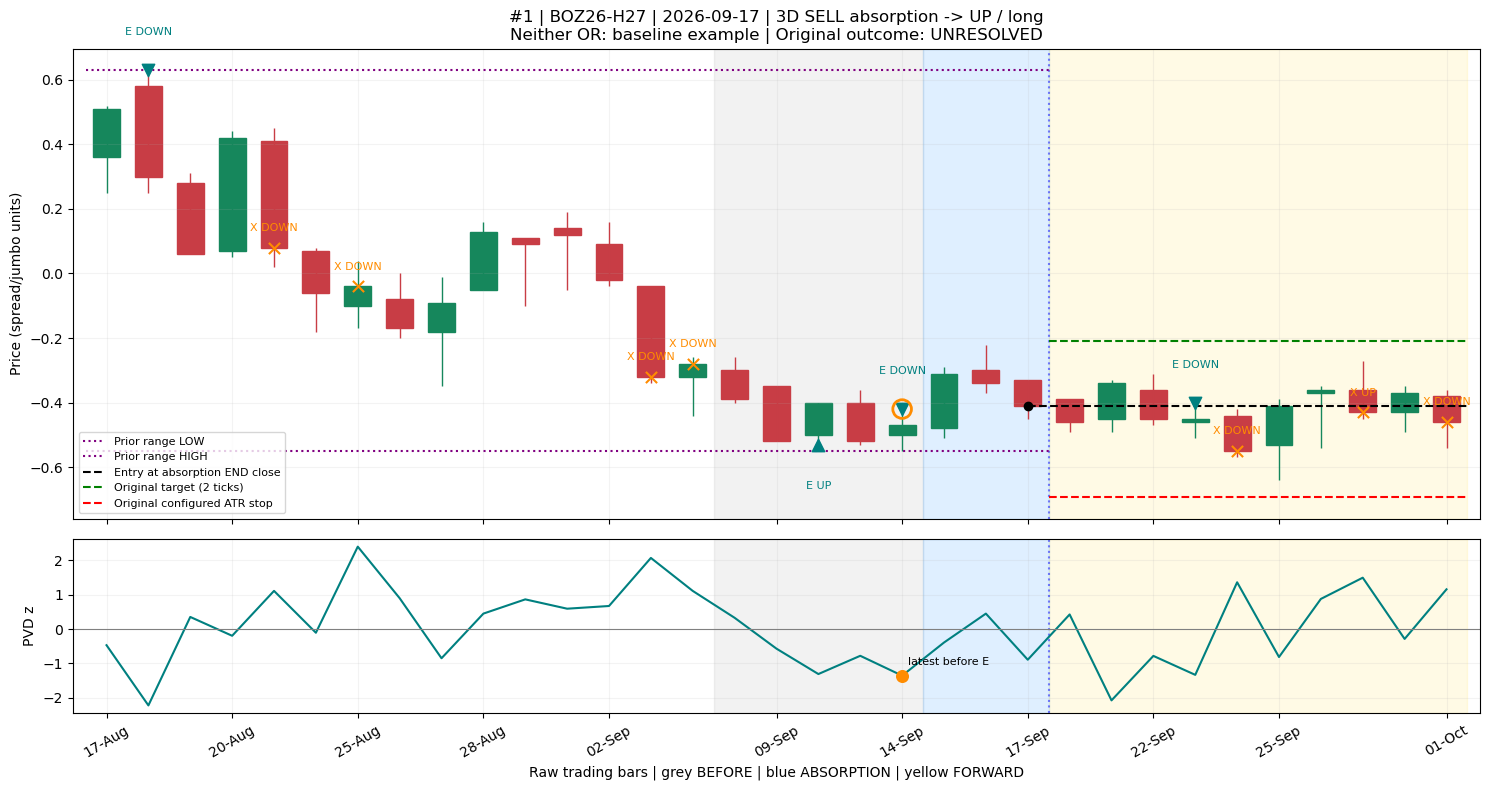

### Example 2: BOZ26-F27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-07-28 se 2026-08-03.

**Rejection:** YES. Prior 20 bars ka range 0.02–0.56; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=OPPOSITE. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** UNRESOLVED; research payoff not resolved / not measured.

Observed horizon mein target/stop se label resolve nahi hua; average payoff mein include nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

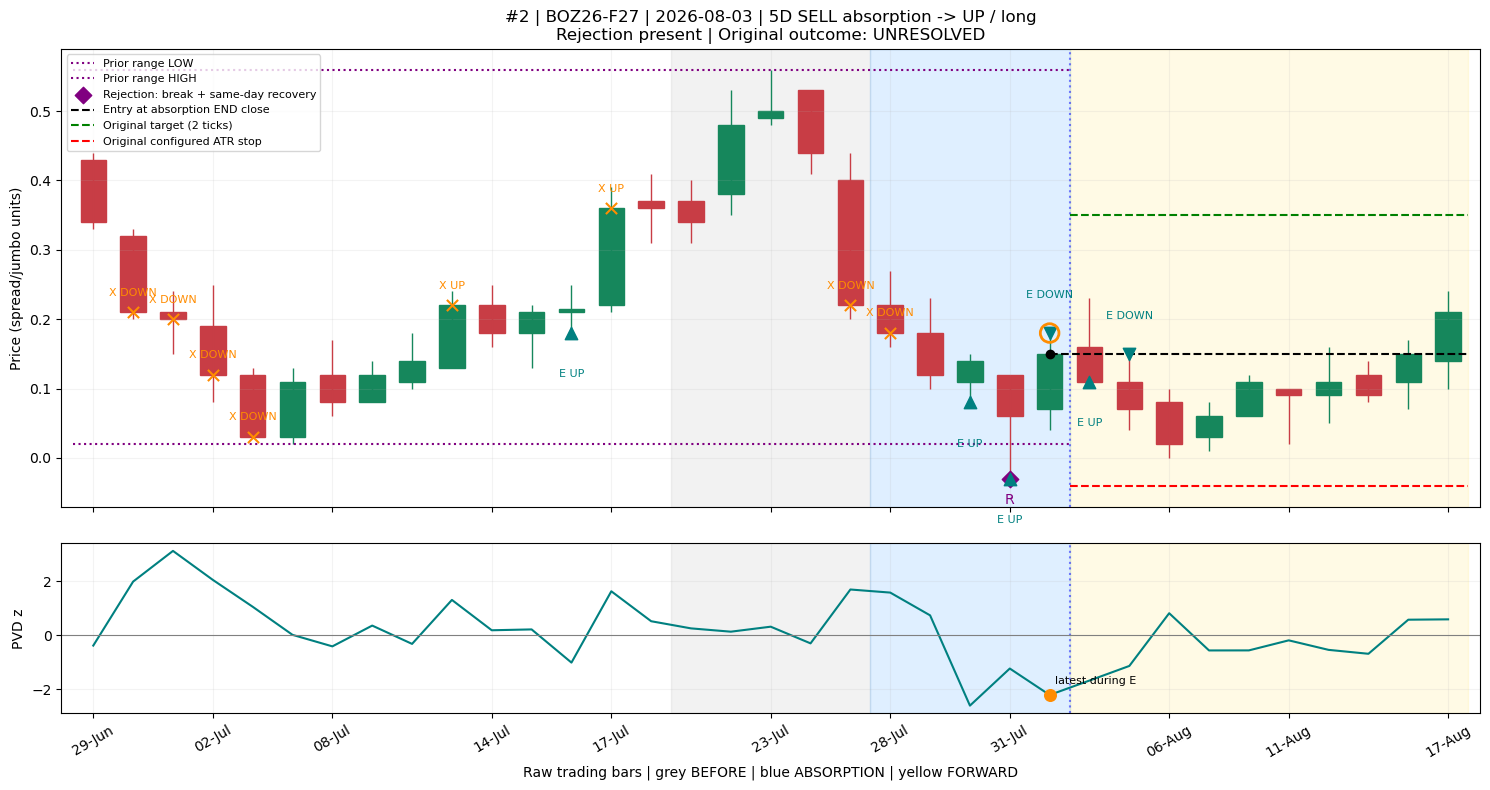

### Example 3: WK27-U27 — Specific OR only: PVD

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-10-06 se 2026-10-06.

**Rejection:** NO. Prior 20 bars ka range -9.25–5.75; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=OPPOSITE. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

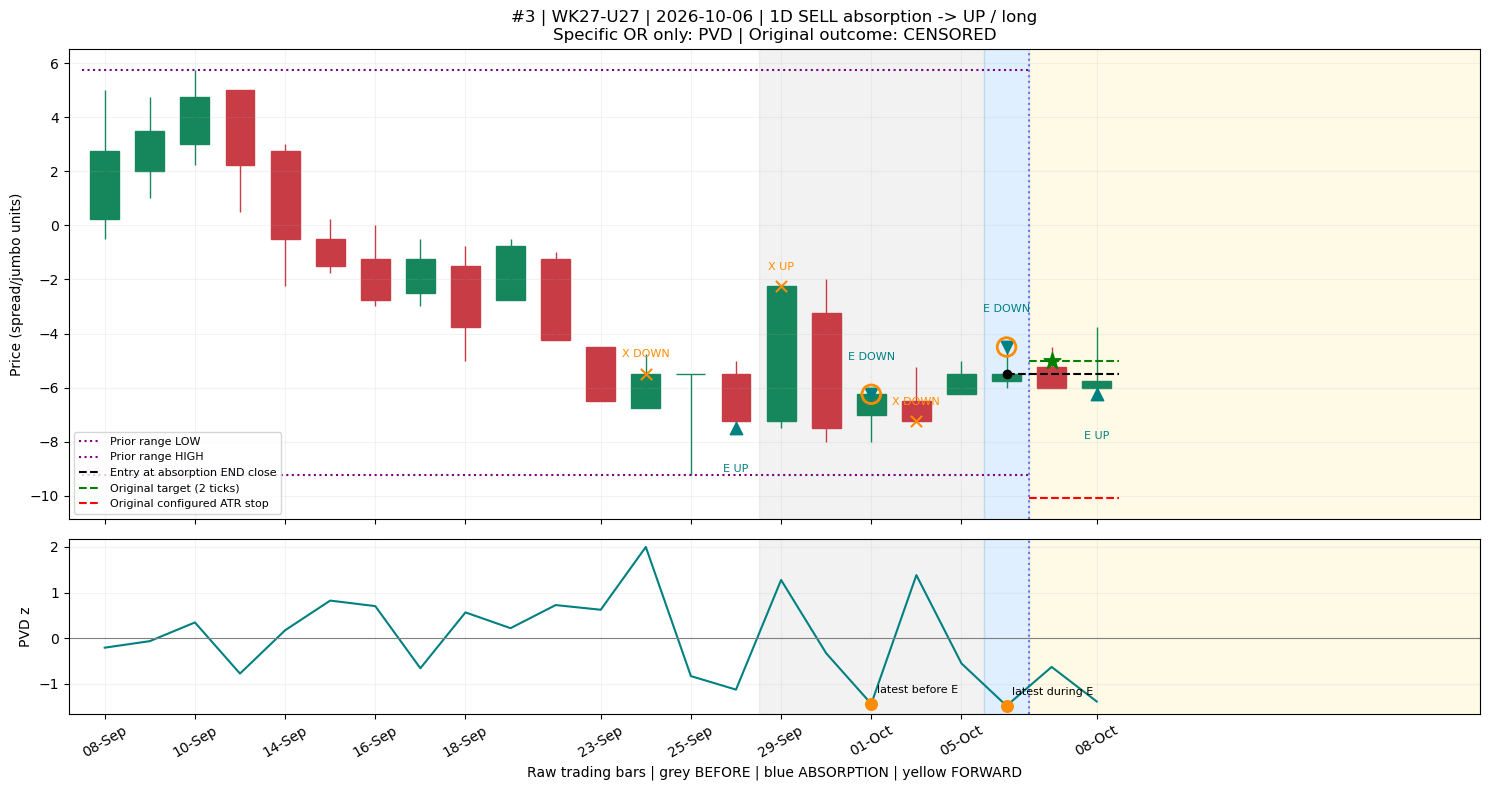

### Example 4: SMN27-Q27 — Common OR only: PVD

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-06-22 se 2026-06-26.

**Rejection:** NO. Prior 20 bars ka range -0.6–1.7; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** FAILURE; research payoff -4.93 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

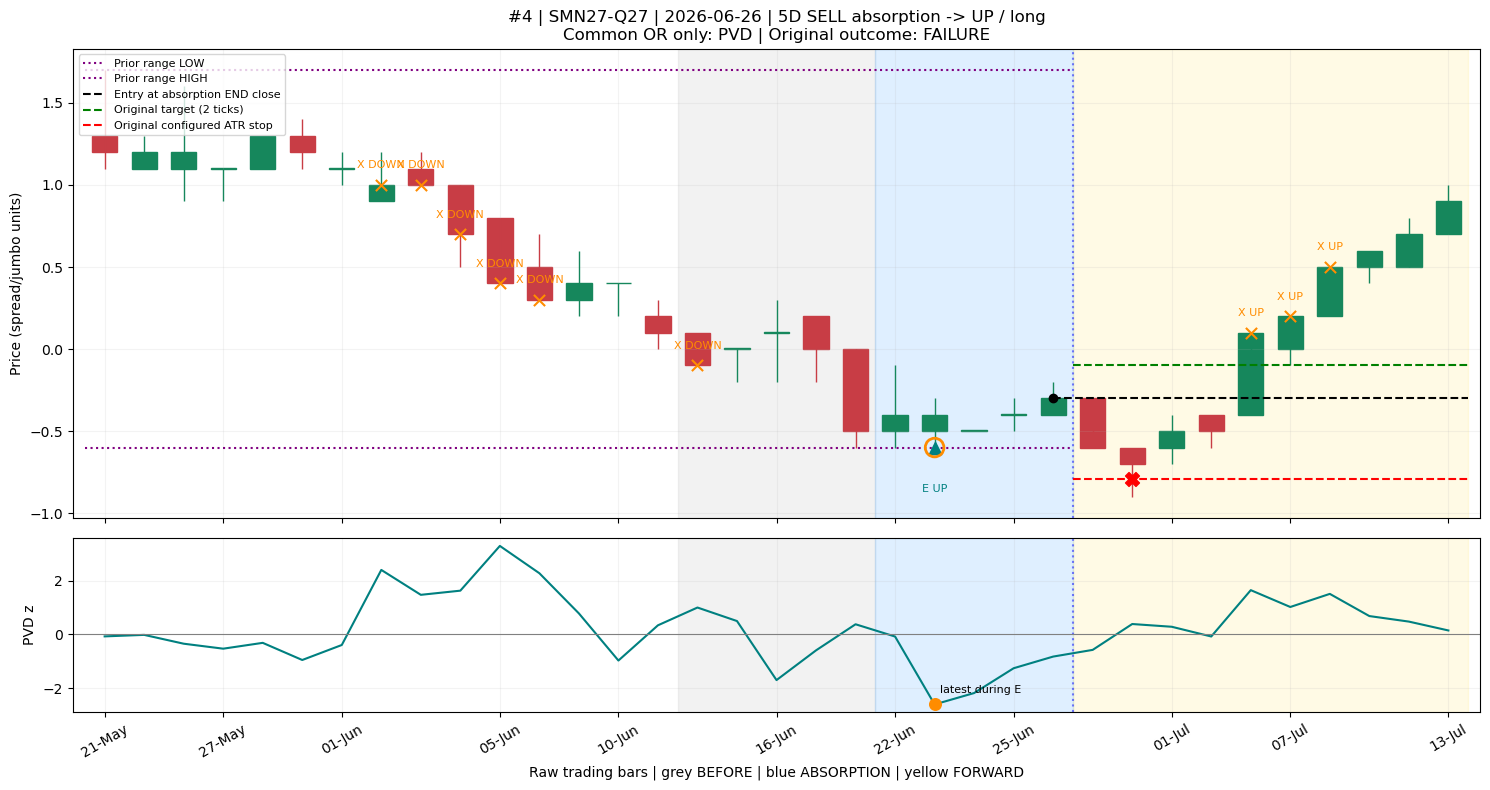

### Example 5: SMK27-N27 — Neither OR: baseline example

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-08-14 se 2026-08-14.

**Rejection:** NO. Prior 20 bars ka range -3.5–-1.8; range absorption start se pehle ka hai.

**Latest exhaustion:** before=ALIGNED; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** FAILURE; research payoff -6.00 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

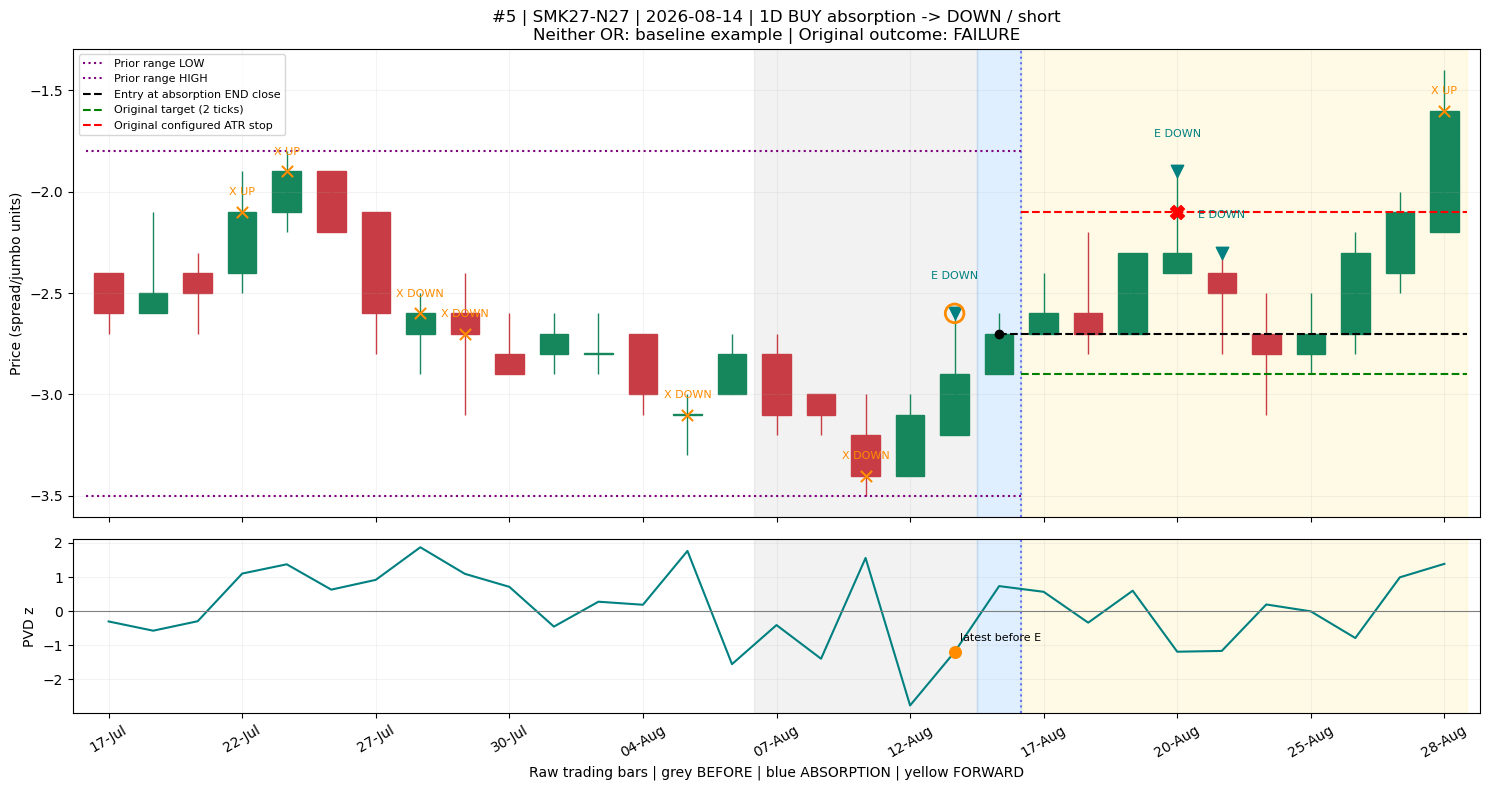

### Example 6: BOZ26-F27 — Both OR rules: PVD only

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-09-24 se 2026-09-30.

**Rejection:** NO. Prior 20 bars ka range -0.32–0.08; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

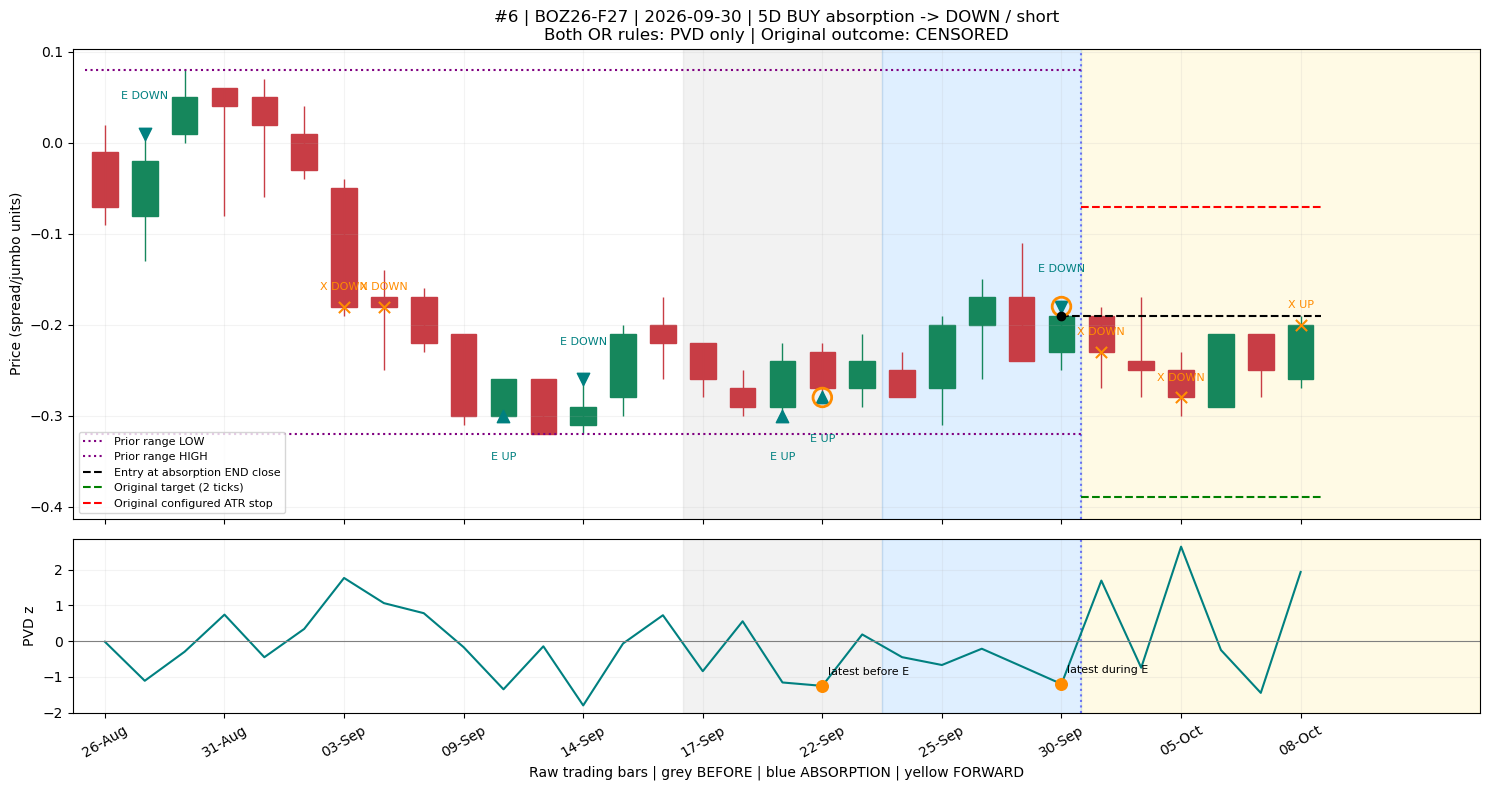

### Example 7: SMZ26-K27 — Both OR rules: PVD only

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-07-22 se 2026-07-24.

**Rejection:** NO. Prior 20 bars ka range -9.1–-1.8; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** SUCCESS; research payoff 53.00 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

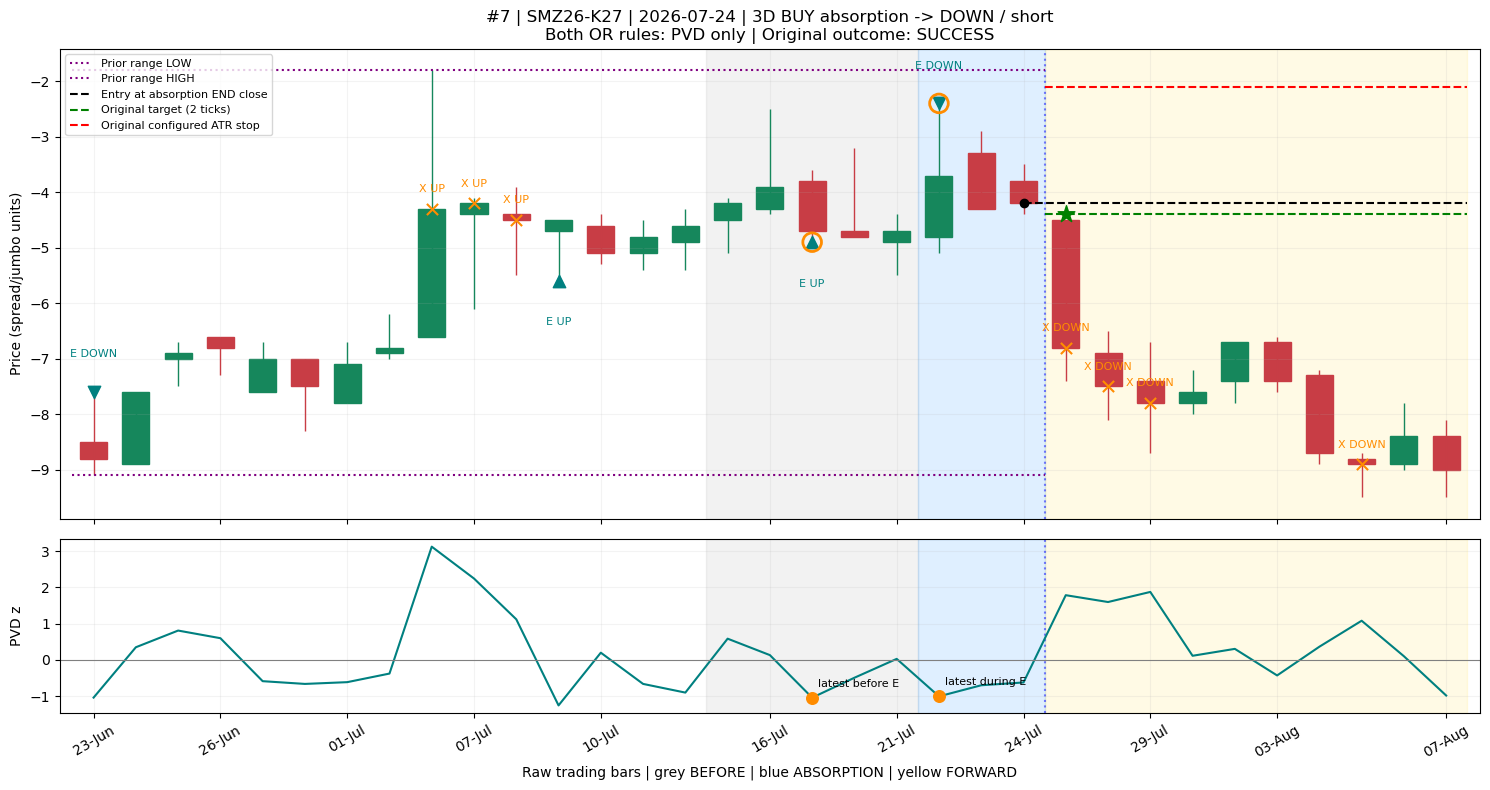

### Example 8: BOH27-K27 — Both OR rules: PVD only

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-07-31 se 2026-08-03.

**Rejection:** NO. Prior 20 bars ka range 0.15–0.7; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** UNRESOLVED; research payoff not resolved / not measured.

Observed horizon mein target/stop se label resolve nahi hua; average payoff mein include nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

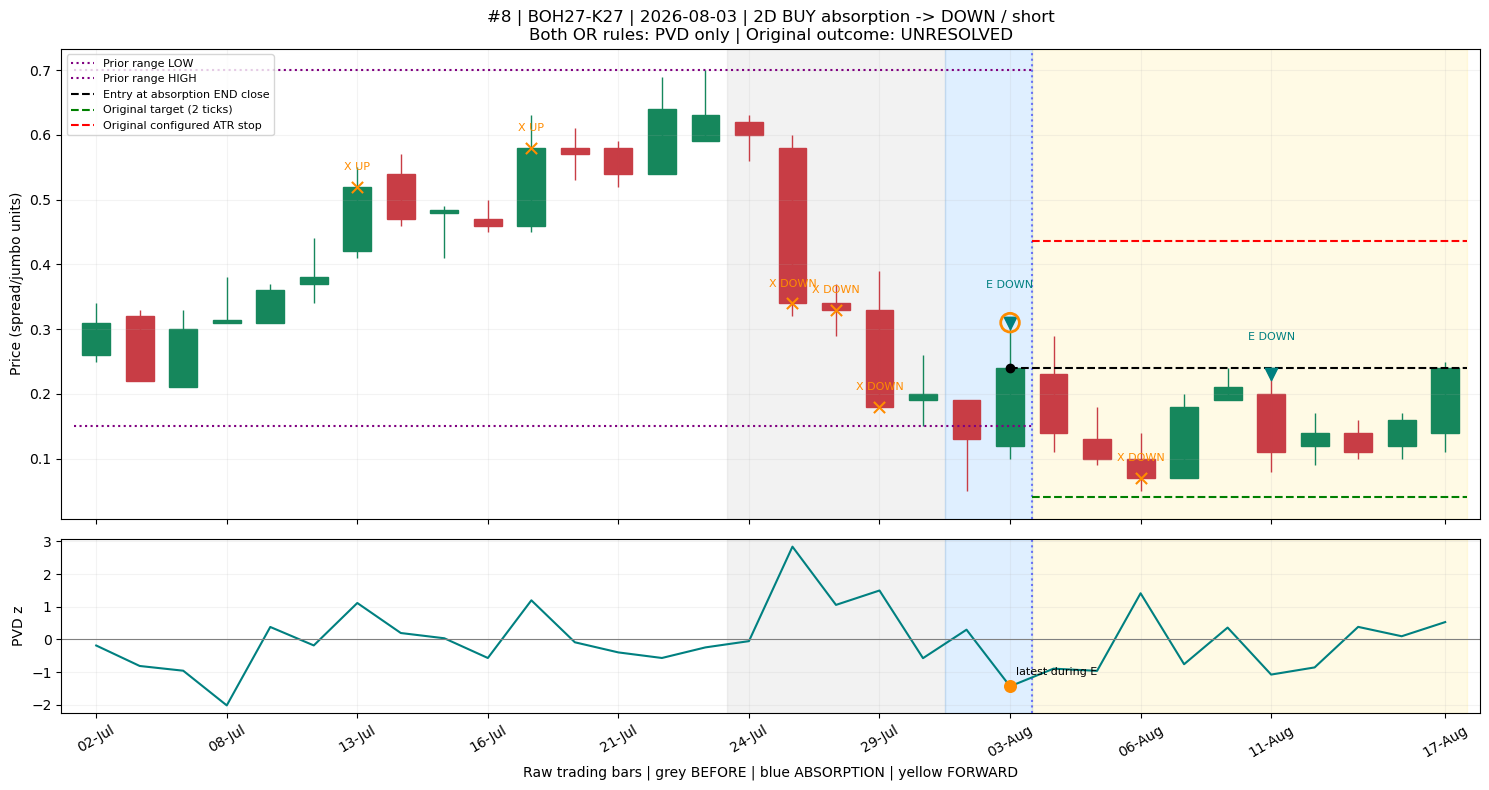

### Example 9: SMH27-N27 — Common OR only: PVD

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-06-29 se 2026-06-29.

**Rejection:** NO. Prior 20 bars ka range -8.2–-1.4; range absorption start se pehle ka hai.

**Latest exhaustion:** before=ALIGNED; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** SUCCESS; research payoff 7.00 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

Target pehle mila aur stop baad mein: original label SUCCESS hi rehta hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

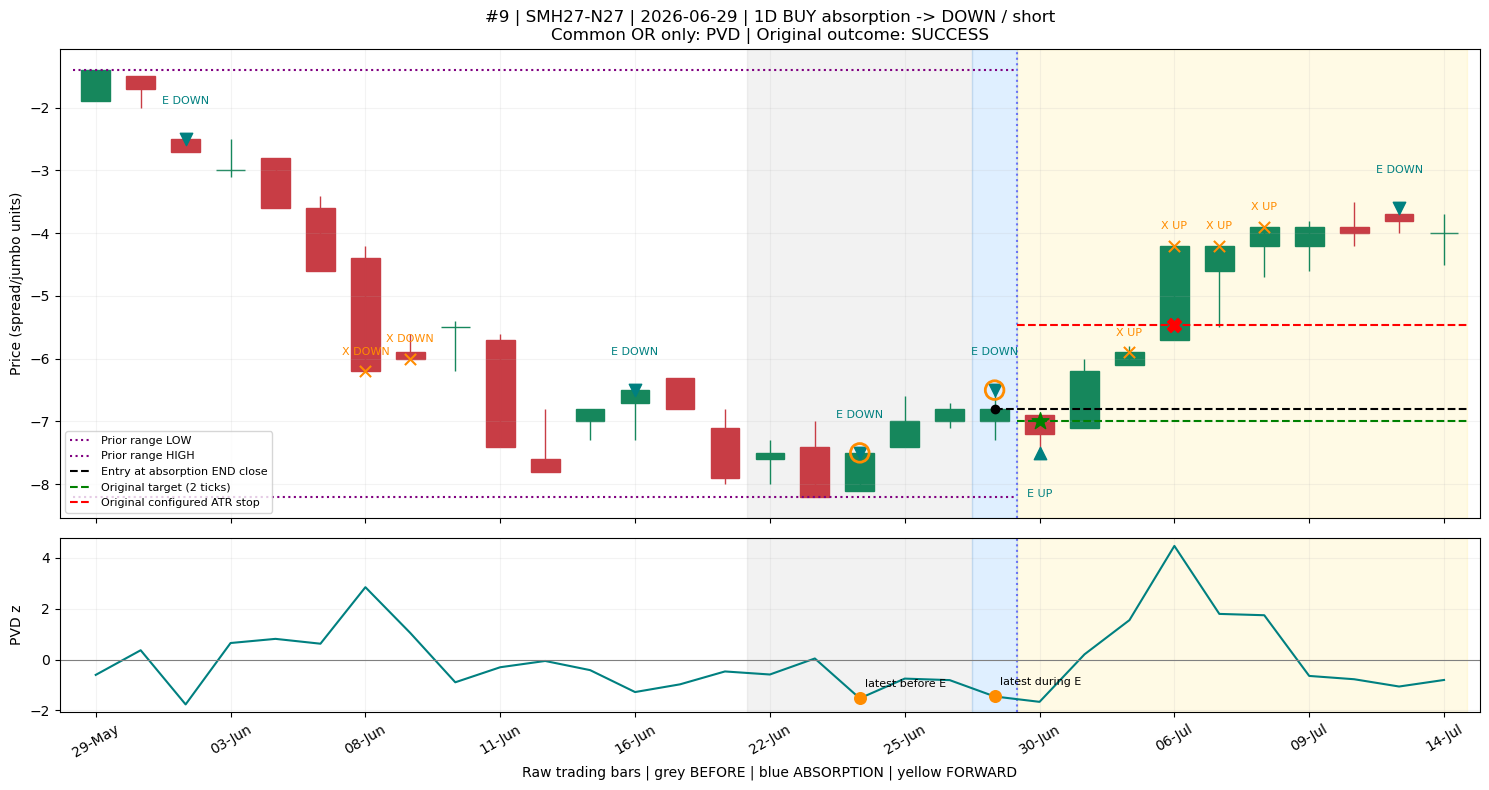

### Example 10: SMH27-N27 — Rejection present

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-09-01 se 2026-09-08.

**Rejection:** YES. Prior 20 bars ka range -6.8–-1.9; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=OPPOSITE. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** FAILURE; research payoff -20.79 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

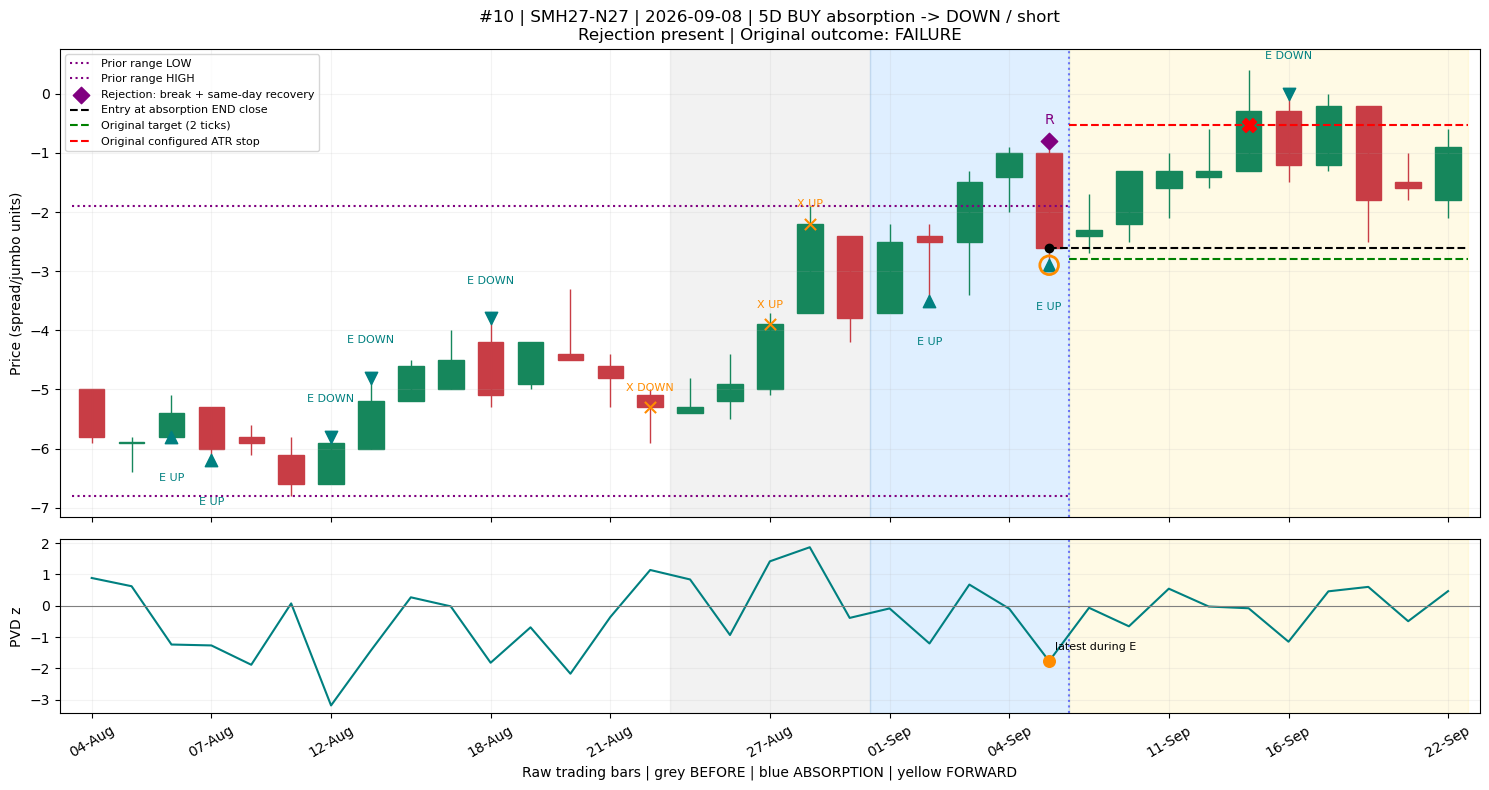

### Example 11: SMF27-N27 — Rejection present

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-08-31 se 2026-09-04.

**Rejection:** YES. Prior 20 bars ka range -10.3–-2.3; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** SUCCESS; research payoff 28.00 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

Target pehle mila aur stop baad mein: original label SUCCESS hi rehta hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

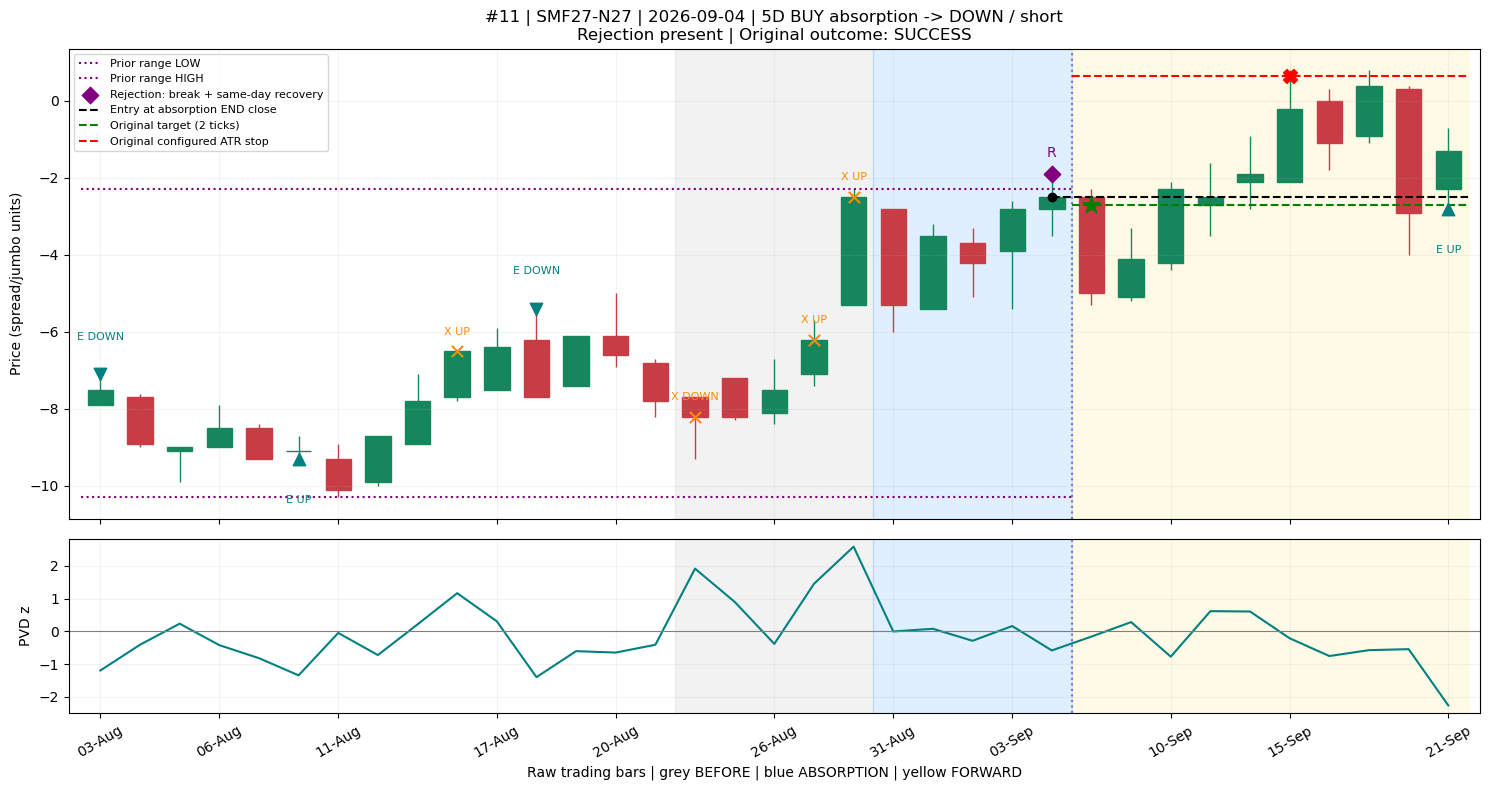

### Example 12: WH27-N27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-09-25 se 2026-09-25.

**Rejection:** YES. Prior 20 bars ka range -9.5–10.5; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

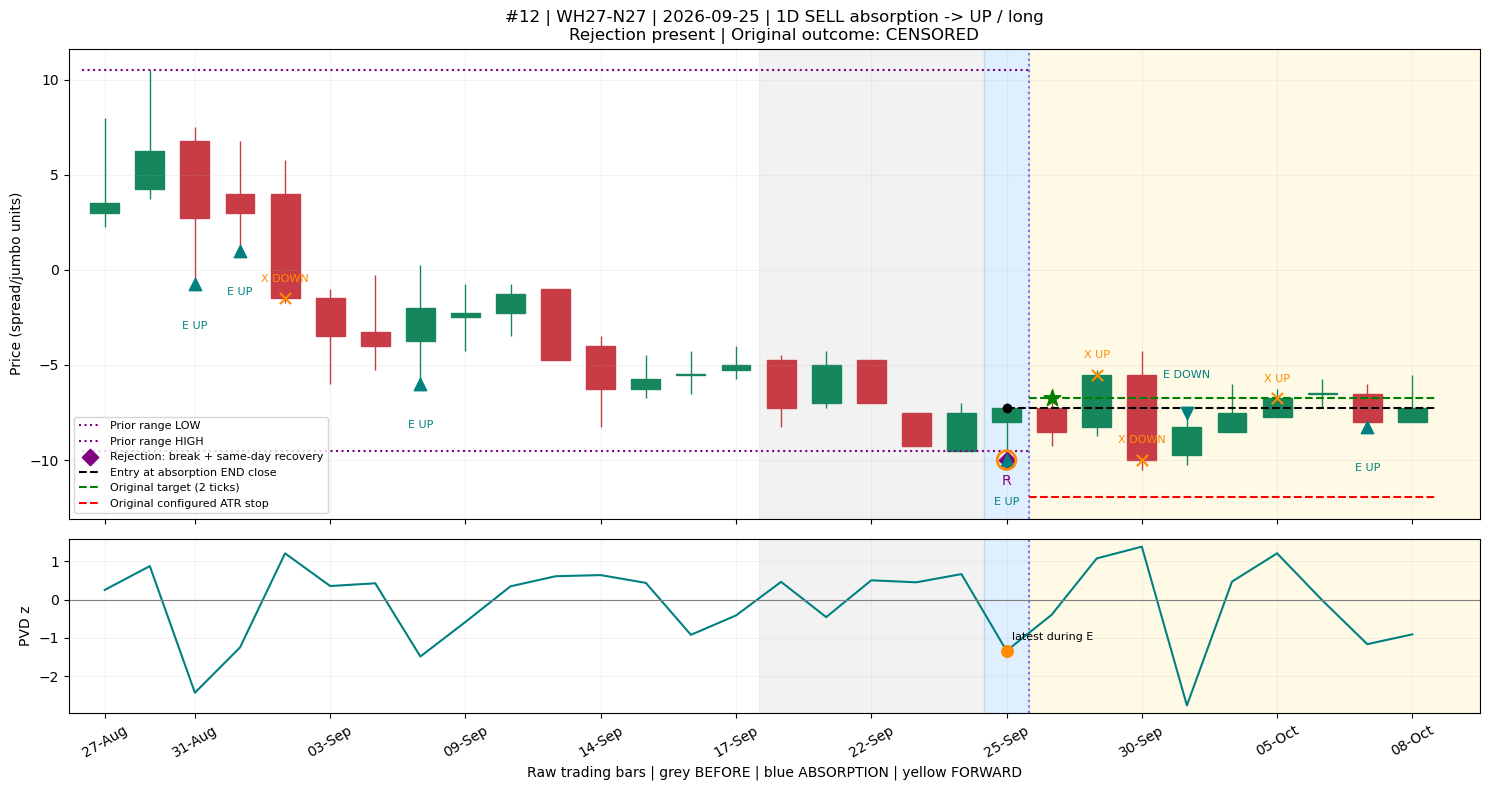

### Example 13: BOZ26-H27 — Rejection present

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-07-20 se 2026-07-24.

**Rejection:** YES. Prior 20 bars ka range 0.14–0.98; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** SUCCESS; research payoff 10.70 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

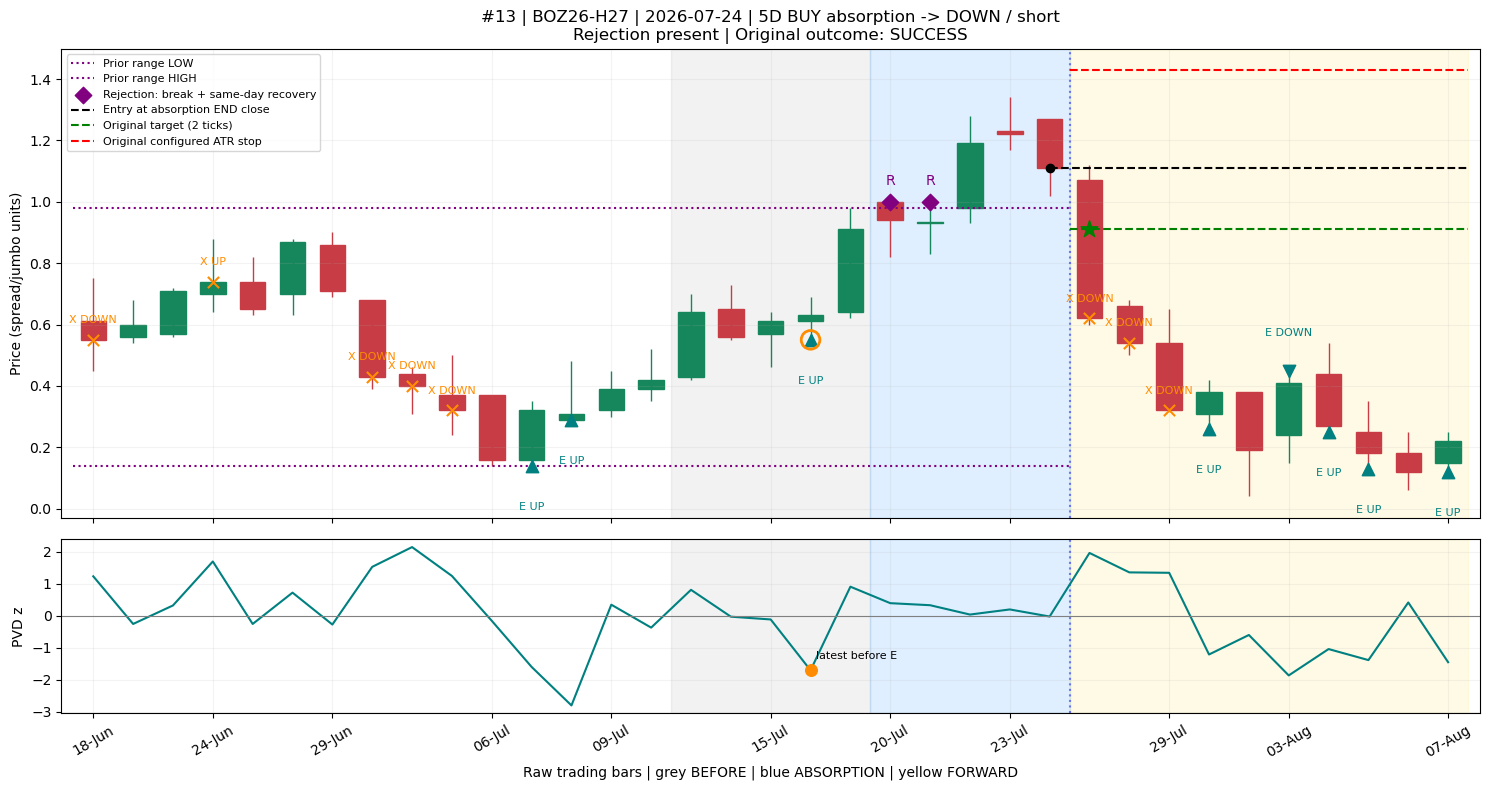

### Example 14: SMZ26-F27 — Specific OR only: PVD

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-09-24 se 2026-09-30.

**Rejection:** NO. Prior 20 bars ka range -3.2–0.3; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

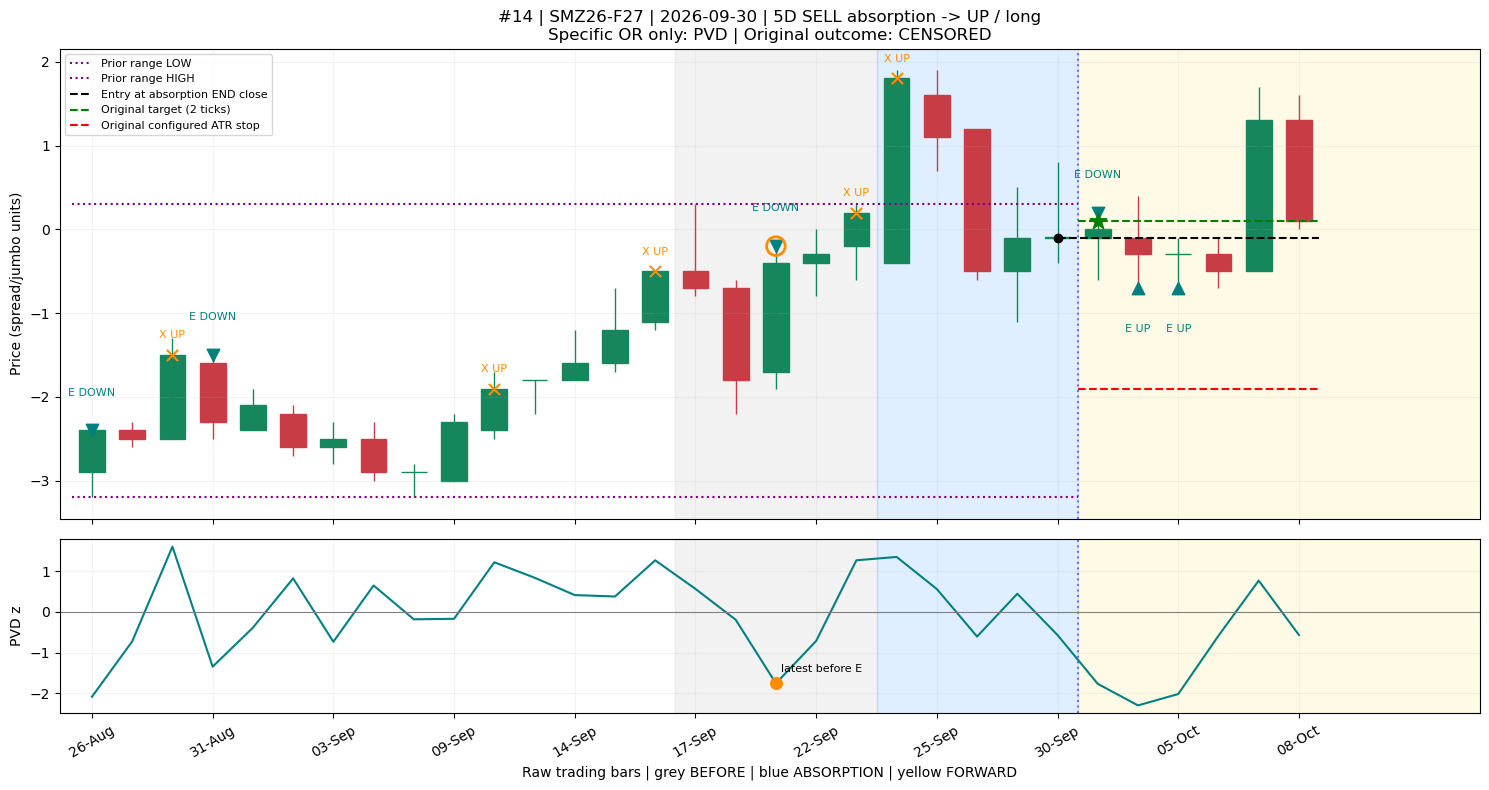

### Example 15: SMK27-N27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-10-05 se 2026-10-06.

**Rejection:** YES. Prior 20 bars ka range -2.9–0.1; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

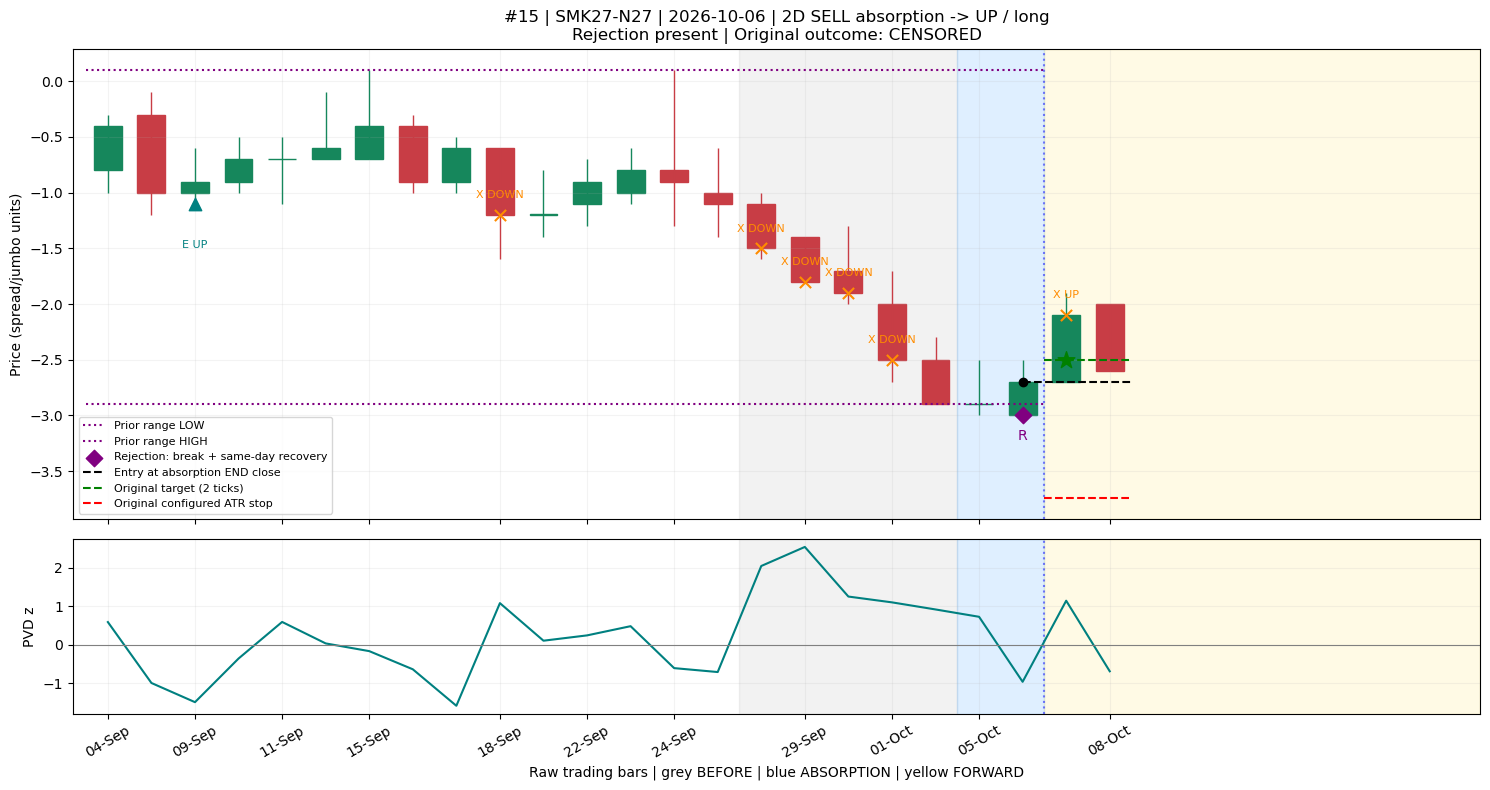

### Example 16: BOK27-N27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-06-18 se 2026-06-22.

**Rejection:** YES. Prior 20 bars ka range 0.52–0.84; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=OPPOSITE. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** FAILURE; research payoff -1.38 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

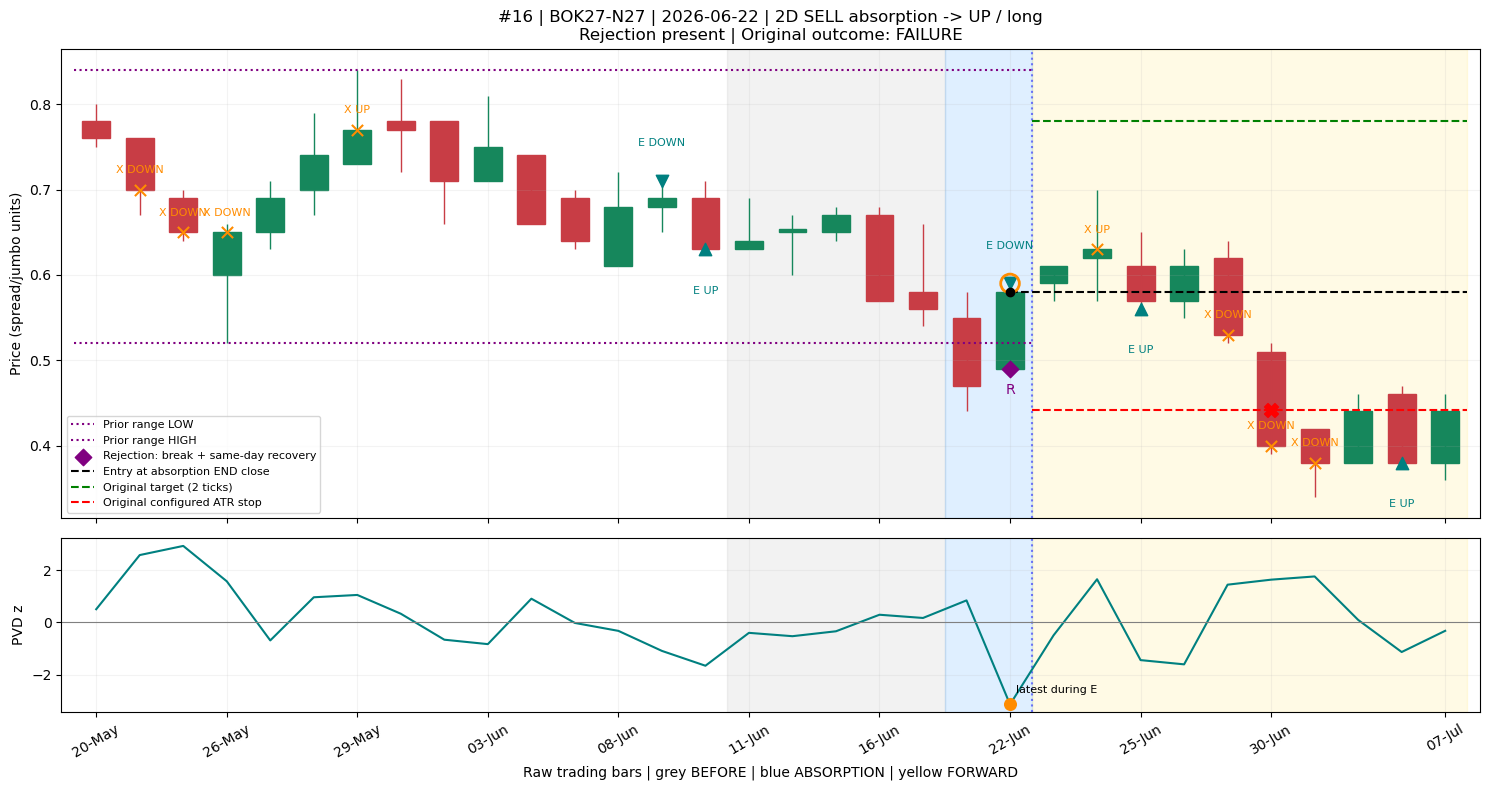

### Example 17: BOH27-K27 — Both OR rules: PVD only

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-06-03 se 2026-06-09.

**Rejection:** NO. Prior 20 bars ka range 0.41–0.85; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** FAILURE; research payoff -1.62 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

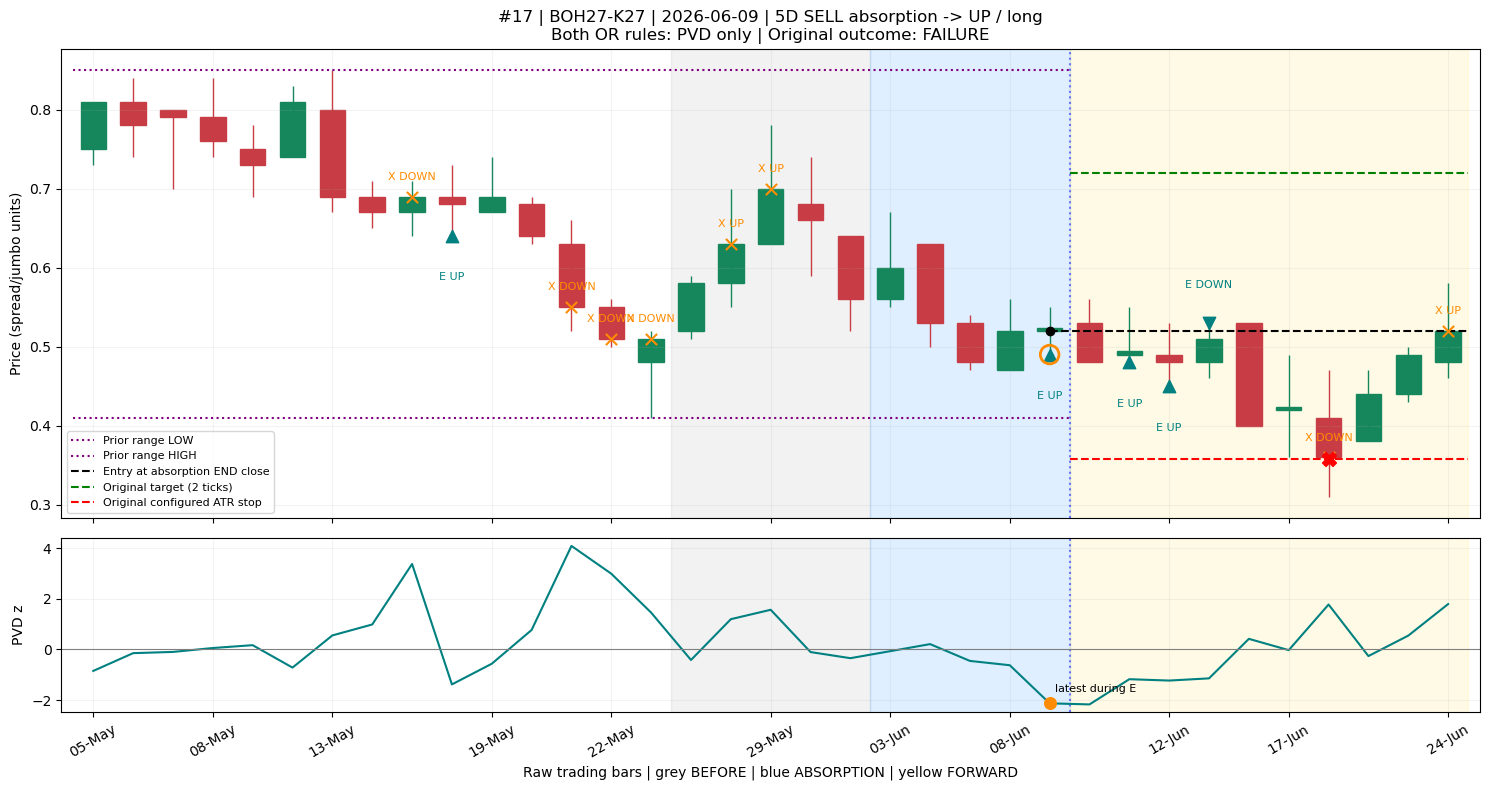

### Example 18: BOF27-H27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-09-24 se 2026-09-28.

**Rejection:** YES. Prior 20 bars ka range -0.24–0.12; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

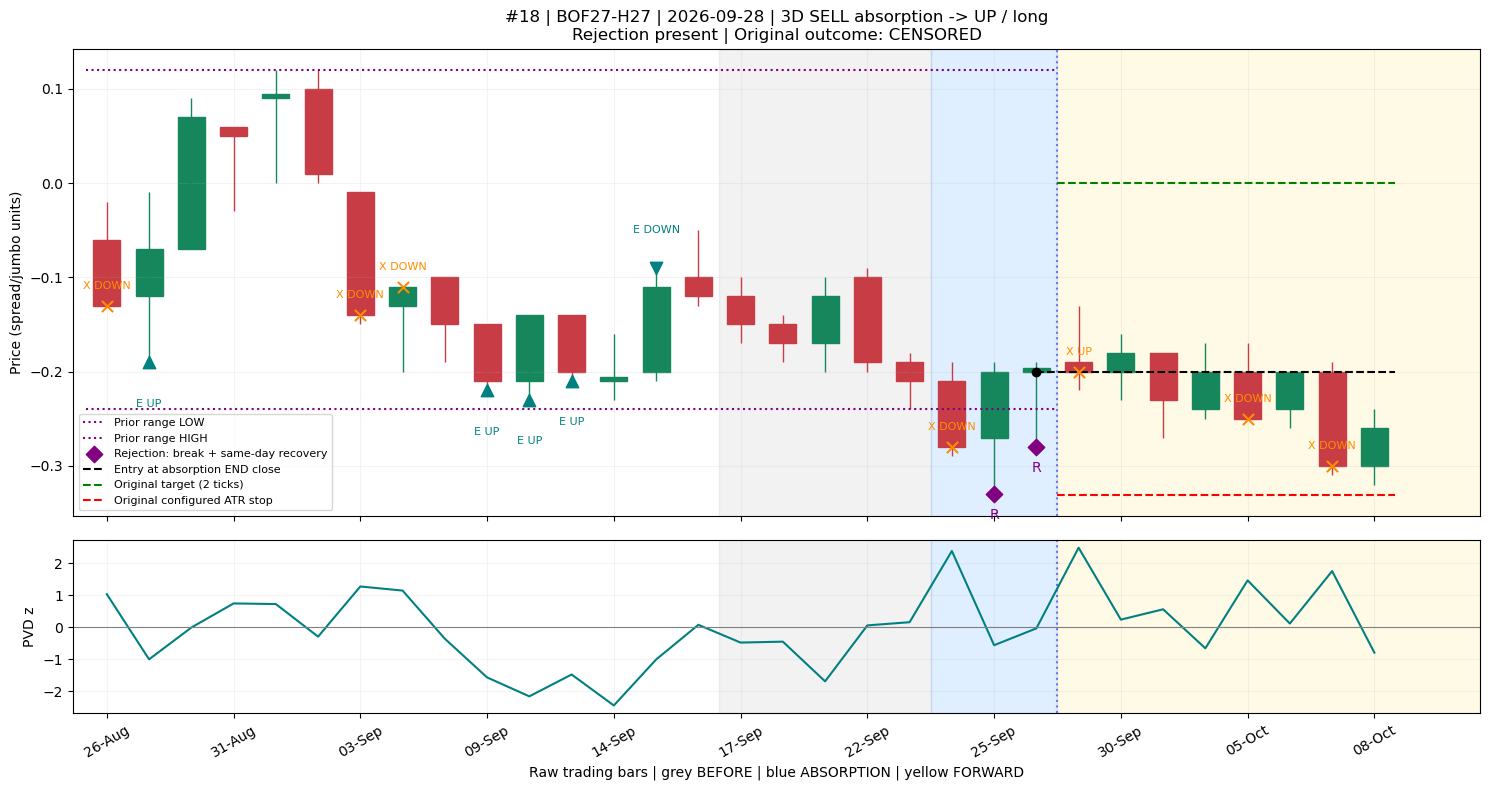

### Example 19: SMN27-Q27 — Both OR rules: PVD only

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-09-04 se 2026-09-11.

**Rejection:** NO. Prior 20 bars ka range 0.6–3.5; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=ALIGNED. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** FAILURE; research payoff -11.14 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

Daily bar ke andar stop/target order unknown tha; saved conservative rule apply hua.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

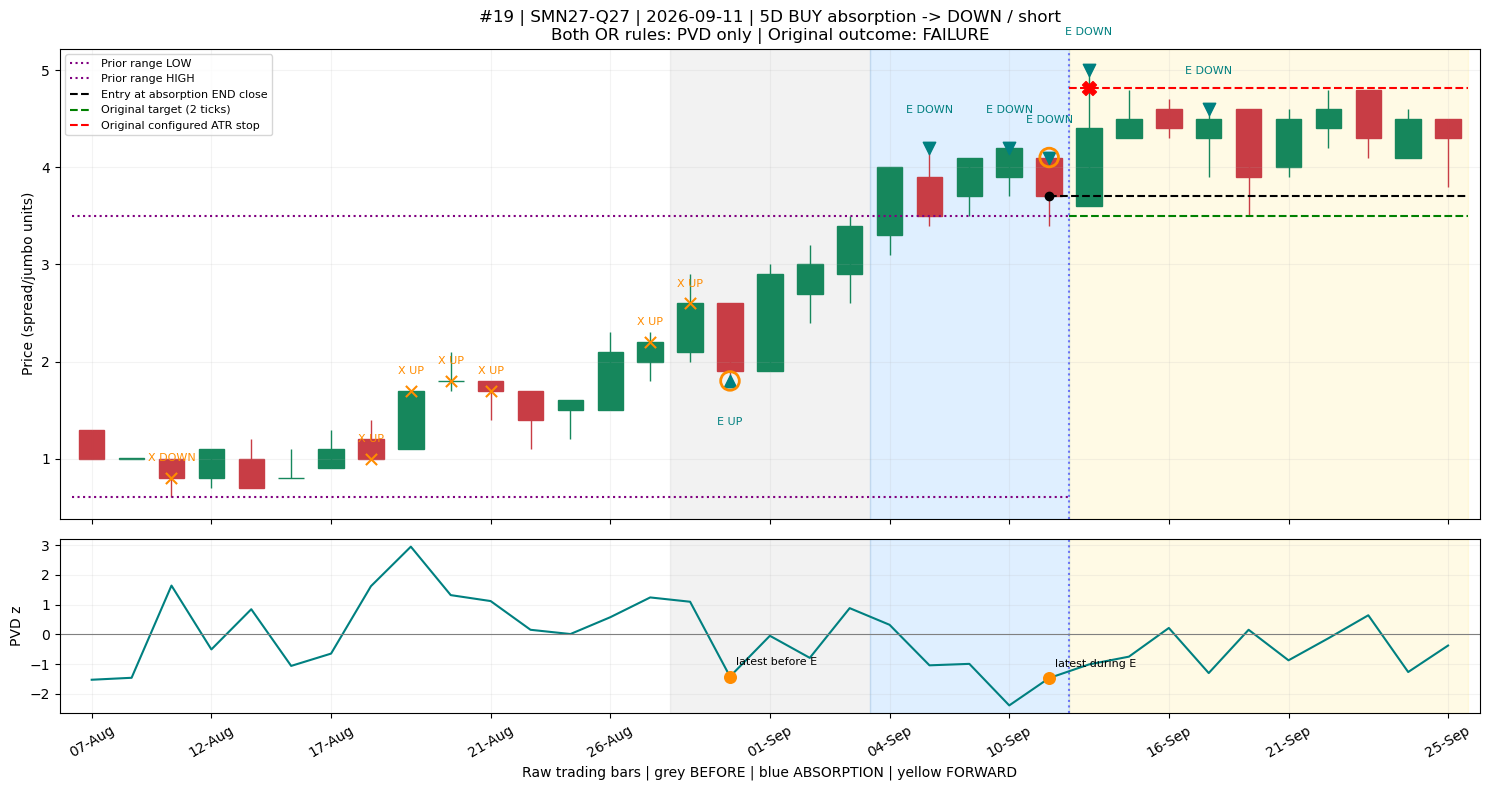

### Example 20: WK27-U27 — Specific OR only: PVD

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-08-21 se 2026-08-25.

**Rejection:** NO. Prior 20 bars ka range -10–5.25; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** FAILURE; research payoff -17.46 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

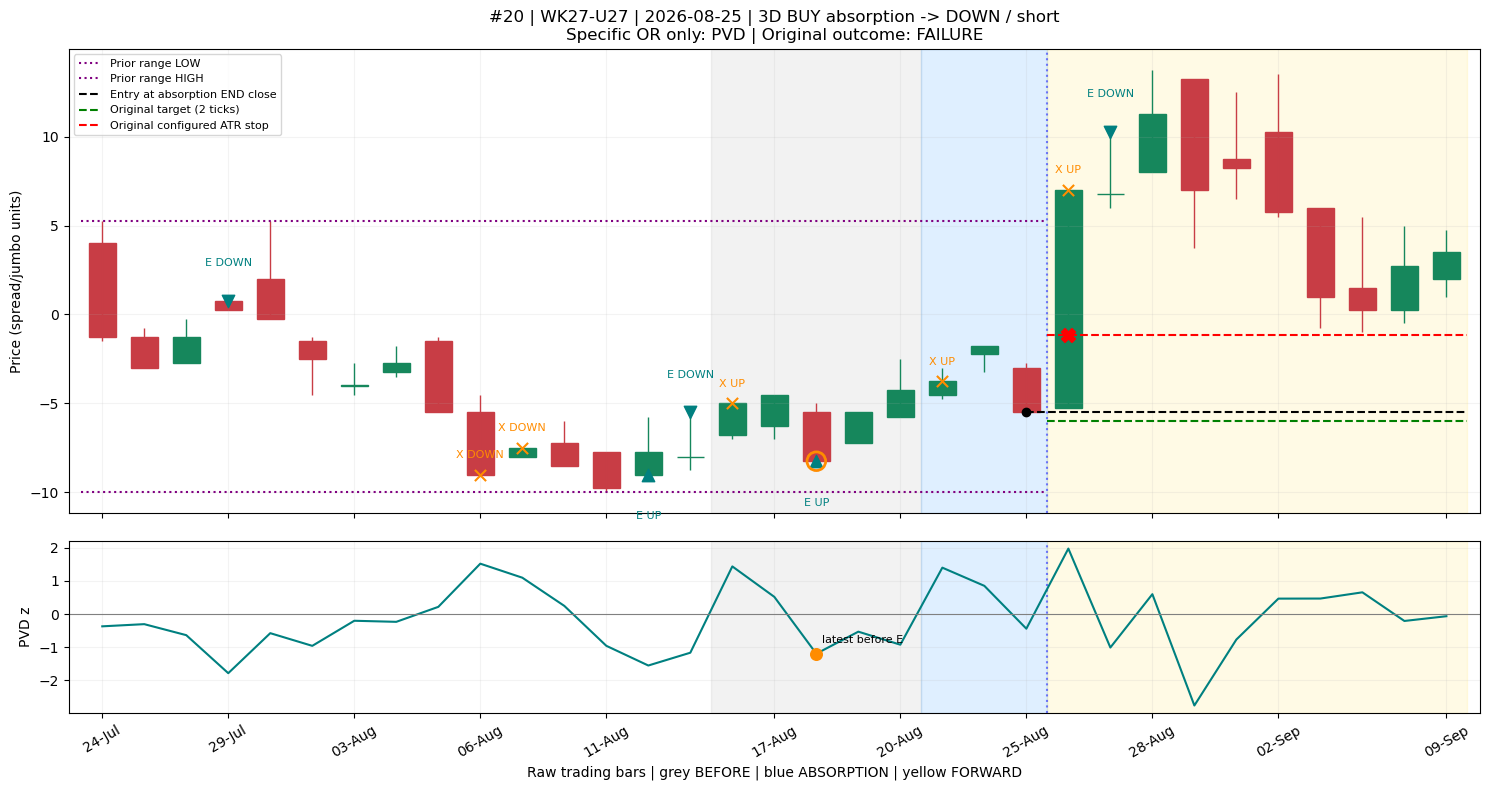

### Example 21: SMH27-N27 — Specific OR only: PVD

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-09-21 se 2026-09-25.

**Rejection:** NO. Prior 20 bars ka range -5.9–0.4; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** FAILURE; research payoff -22.07 ticks.

Original target se pehle stop laga: signal condition milna success ki guarantee nahi.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

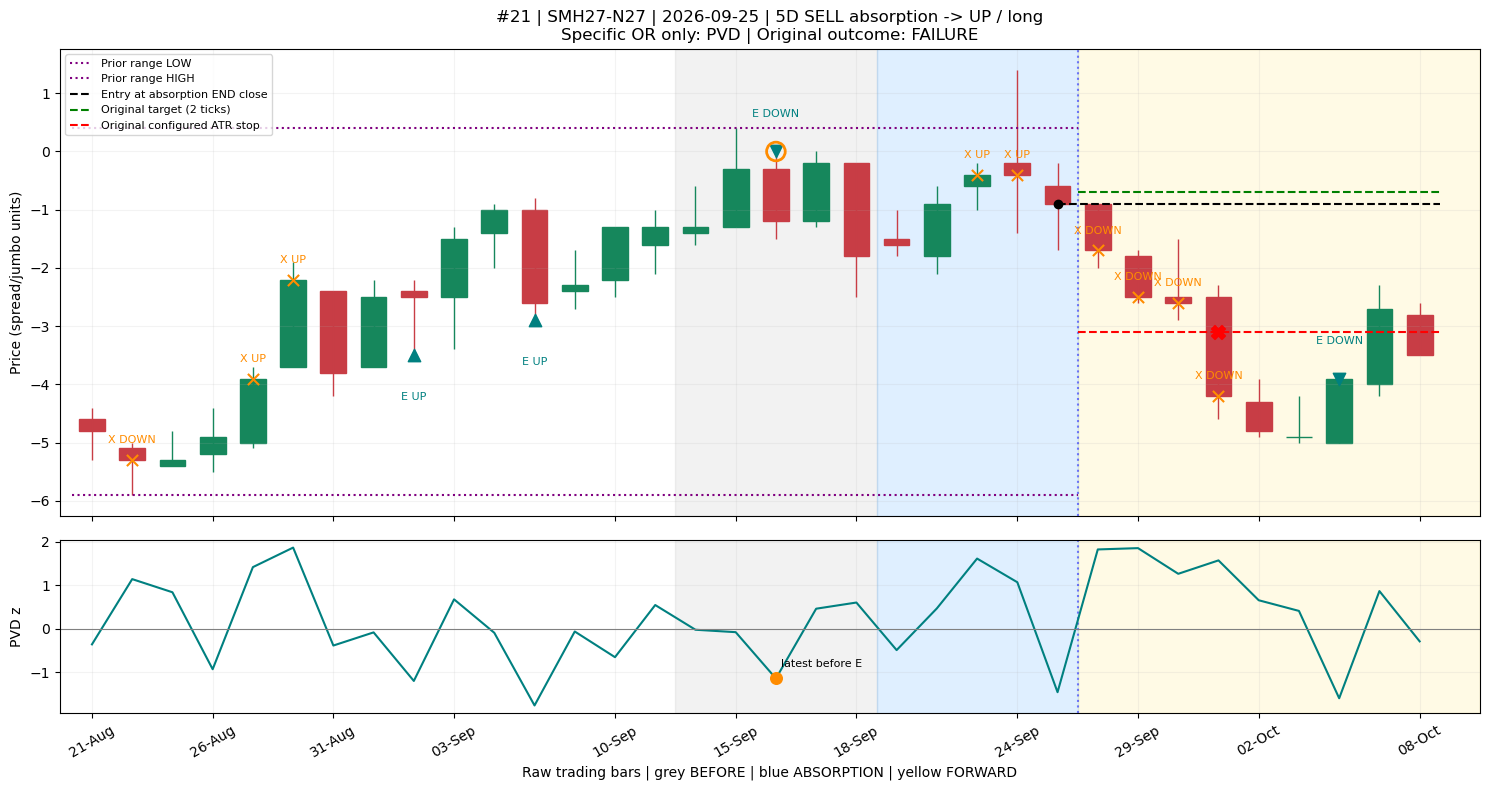

### Example 22: BOZ26-F27 — Neither OR: baseline example

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-10-02 se 2026-10-02.

**Rejection:** NO. Prior 20 bars ka range -0.32–-0.04; range absorption start se pehle ka hai.

**Latest exhaustion:** before=OPPOSITE; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** CENSORED; research payoff not resolved / not measured.

Future/size history incomplete hai; isko failure ya zero profit mat samjho.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

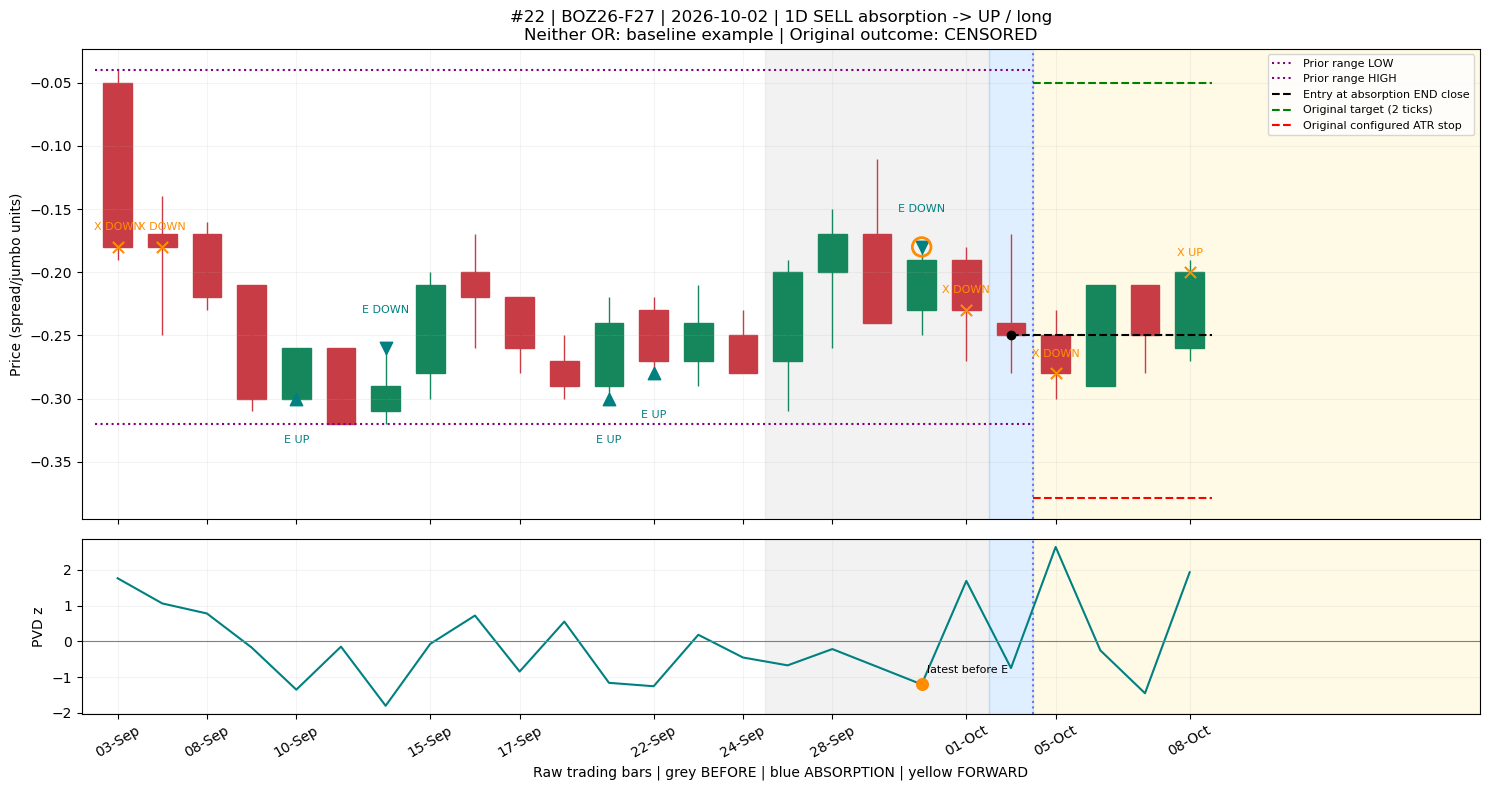

### Example 23: BOF27-N27 — Neither OR: baseline example

**Absorption:** BUY hai, original expectation **DOWN / short**. Window 2026-08-24 se 2026-08-28.

**Rejection:** NO. Prior 20 bars ka range 0.32–1.88; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR during-ALIGNED: SKIPPED. **Common OR:** rejection OR during-ALIGNED: SKIPPED.

**Actually hua:** SUCCESS; research payoff 6.80 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

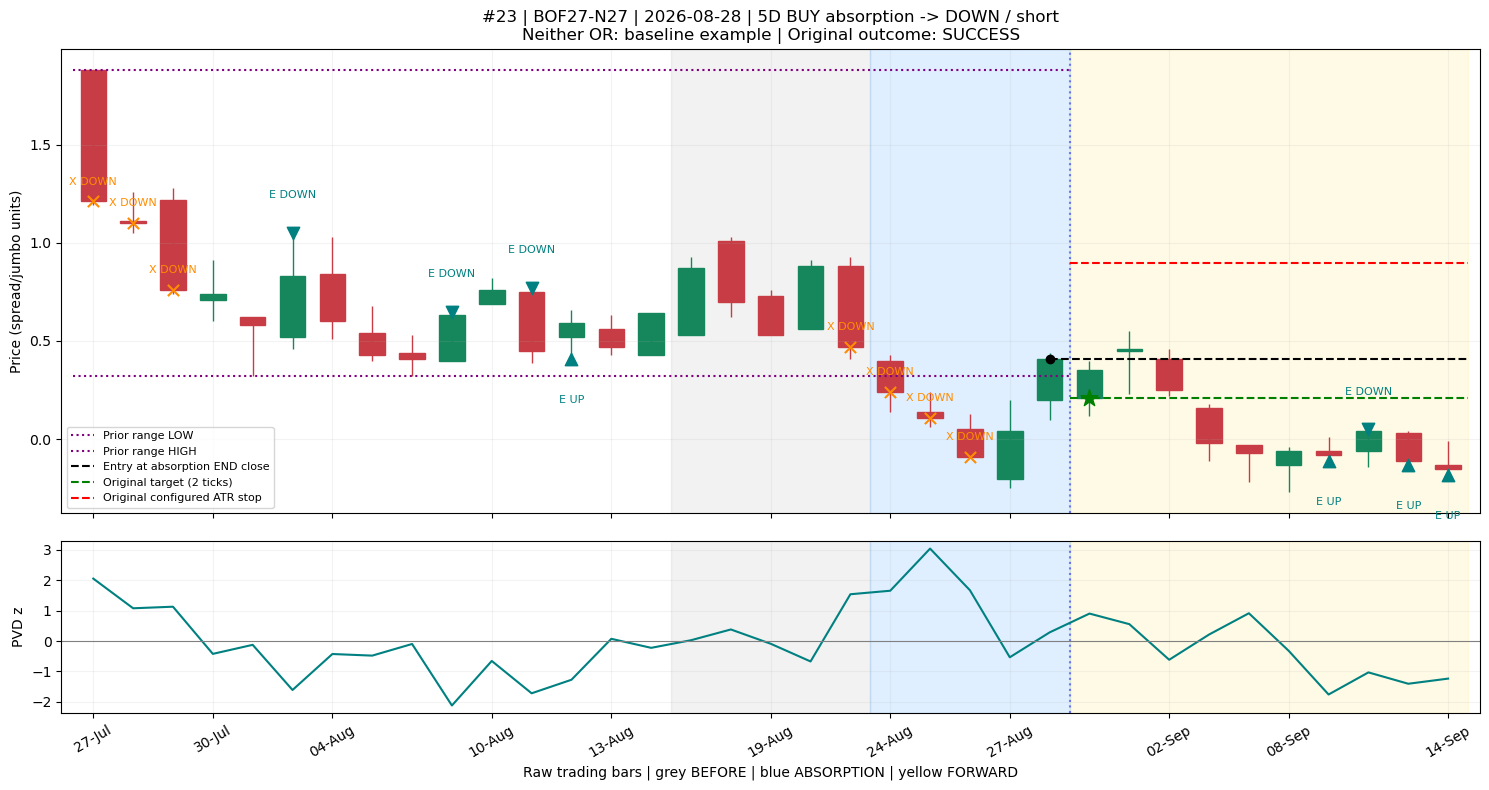

### Example 24: WZ26-H27 — Rejection present

**Absorption:** SELL hai, original expectation **UP / long**. Window 2026-07-21 se 2026-07-27.

**Rejection:** YES. Prior 20 bars ka range -15.5–-10.25; range absorption start se pehle ka hai.

**Latest exhaustion:** before=NO_SIGNAL; during=NO_SIGNAL. ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.

**Specific OR:** rejection OR before-OPPOSITE: SELECTED. **Common OR:** rejection OR during-ALIGNED: SELECTED.

**Actually hua:** SUCCESS; research payoff 7.00 ticks.

Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.

**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.

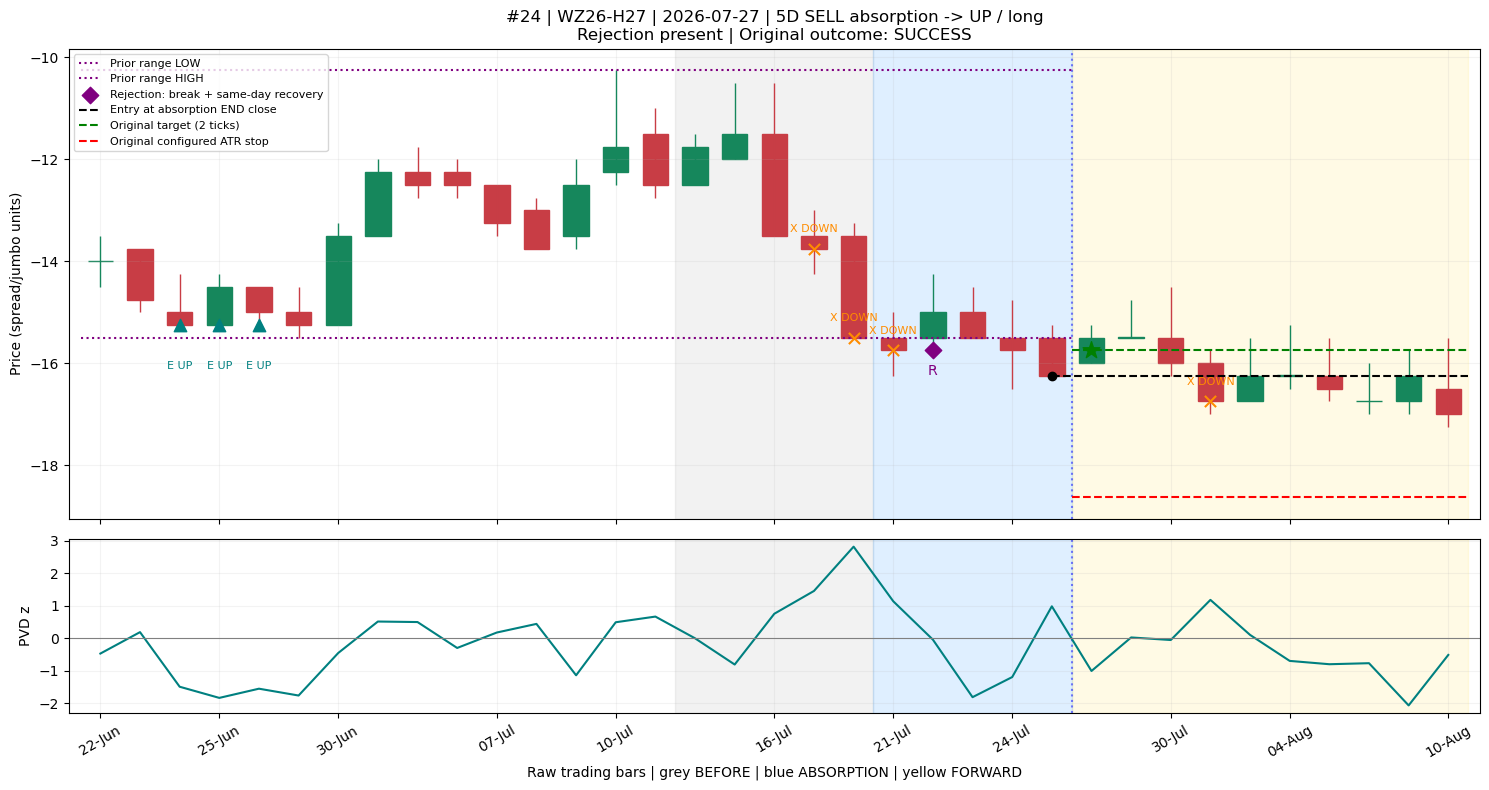

Plots + selected event ledger saved: C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents\market_analysis\combined_signal_analysis\outputs\relaxed_research\2026-10-09\trade_examples\relaxed_research


In [28]:
_example_daily_cache = {}

def example_daily(instrument):
    """Saved scoring snapshot; aaj ki cache/API se history change nahi hoti."""
    if instrument not in _example_daily_cache:
        d = pd.read_csv(EXAMPLE_RUN_DIR / f"{instrument}_daily_signals.csv")
        d["Date"] = pd.to_datetime(d["Date"], utc=True)
        _example_daily_cache[instrument] = d
    return _example_daily_cache[instrument]


def plot_multisignal_example(event, number=1):
    """One original event, both OR memberships, all outcomes and raw daily candles."""
    d = example_daily(event.instrument)
    start, end = int(event.window_start_index), int(event.signal_index)
    if d.iloc[end].Date != pd.Timestamp(event.Date):
        raise ValueError("Daily snapshot/event dates do not align.")
    prior = d.iloc[max(0, start-EXAMPLE_LOOKBACK):start]
    if len(prior) != EXAMPLE_LOOKBACK:
        raise ValueError("Prior range unavailable.")
    lo, hi = float(prior.low.min()), float(prior.high.max())
    side = event.absorption_side
    sign = 1 if side == "SELL" else -1
    direction = "UP / long" if sign == 1 else "DOWN / short"
    # Tick recovered from stored configured ATR stop distance; no product hardcoding.
    tick = abs(float(event.stop_loss)-float(event.entry_price))/float(event.stop_distance_ticks)
    if not np.isfinite(tick) or tick <= 0:
        raise ValueError("Invalid tick/stop metadata.")
    left, right = max(0, start-EXAMPLE_LOOKBACK), min(len(d)-1, end+EXAMPLE_FORWARD)
    part = d.iloc[left:right+1]
    fig, (ax, pvdax) = plt.subplots(2, 1, figsize=(15, 8), sharex=True,
                                   gridspec_kw={"height_ratios": [3.5, 1.3]})
    for a in (ax, pvdax):
        a.axvspan(max(left, start-EXAMPLE_BEFORE)-.5, start-.5, color="grey", alpha=.10)
        a.axvspan(start-.5, end+.5, color="dodgerblue", alpha=.14)
        a.axvspan(end+.5, end+EXAMPLE_FORWARD+.5, color="gold", alpha=.10)
        a.axvline(end+.5, color="blue", alpha=.5, linestyle=":")
        a.grid(alpha=.15)
    for j, bar in part.iterrows():
        color = "#16875c" if bar.close >= bar.open else "#c83d45"
        ax.vlines(j, bar.low, bar.high, color=color, linewidth=1)
        height = max(abs(bar.close-bar.open), tick*.04)
        ax.add_patch(Rectangle((j-.32, min(bar.open, bar.close)), .64, height,
                               facecolor=color, edgecolor=color))
    for level, name in [(lo, "Prior range LOW"), (hi, "Prior range HIGH")]:
        ax.hlines(level, left-.5, end+.5, color="purple", linestyles=":", label=name)
    during = d.iloc[start:end+1]
    rejection = ((during.low < lo) & (during.close > lo)) if sign == 1 else (
                 (during.high > hi) & (during.close < hi))
    if bool(rejection.any()) != bool(event.rejection):
        raise ValueError("Plotted rejection disagrees with stored feature.")
    for j in during.index[rejection]:
        value = d.iloc[j].low if sign == 1 else d.iloc[j].high
        ax.scatter(j, value, color="purple", marker="D", s=70, zorder=6,
                   label="Rejection: break + same-day recovery")
        ax.annotate("R", (j, value), xytext=(0, -18 if sign == 1 else 12),
                    textcoords="offset points", ha="center", color="purple")
    phase_parts = {"before": d.iloc[max(0,start-EXAMPLE_BEFORE):start], "during": during}
    used = {}
    for phase_name, segment in phase_parts.items():
        hits = segment.loc[segment.pvd_signal.astype(str).str.endswith("EXHAUSTION")]
        if len(hits):
            used[int(hits.index[-1])] = phase_name
    # All visible PVDs, including forward context, but only BEFORE/DURING latest E is used.
    for j, bar in part.iterrows():
        name = str(bar.pvd_signal)
        if name.endswith("EXHAUSTION"):
            up = name.startswith("DOWN")  # exhausted down trend -> UP reversal hypothesis
            y = bar.low if up else bar.high
            ax.scatter(j, y, marker="^" if up else "v", s=80, color="teal", zorder=7)
            ax.annotate("E UP" if up else "E DOWN", (j,y), xytext=(0,-32 if up else 25),
                        textcoords="offset points", fontsize=8, ha="center", color="teal")
            if j in used:
                ax.scatter(j,y,s=180,facecolors="none",edgecolors="darkorange",linewidths=2,zorder=8)
        elif name.endswith("EXPANSION"):
            ax.scatter(j, bar.close, marker="x", s=65, color="darkorange", zorder=6)
            ax.annotate("X UP" if name.startswith("UP") else "X DOWN", (j,bar.close),
                        xytext=(0,12),textcoords="offset points",fontsize=8,ha="center",color="darkorange")
    entry = float(event.entry_price)
    ax.hlines(entry, end, right+.5, color="black", linestyles="--", label="Entry at absorption END close")
    ax.hlines(entry+sign*EXAMPLE_TARGET*tick, end+.5, right+.5, color="green", linestyles="--",
              label=f"Original target ({EXAMPLE_TARGET:g} ticks)")
    ax.hlines(float(event.stop_loss), end+.5, right+.5, color="red", linestyles="--", label="Original configured ATR stop")
    ax.scatter(end, entry, color="black", marker="o", zorder=9)
    if pd.notna(event.profit_bar_offset):
        j = end+int(event.profit_bar_offset)
        if j <= right:
            ax.scatter(j, entry+sign*EXAMPLE_TARGET*tick, marker="*", color="green", s=160, zorder=9)
    truth = lambda value: str(value).lower() == "true"
    if truth(event.stop_hit) and pd.notna(event.exit_index):
        j = int(event.exit_index)
        if end < j <= right:
            ax.scatter(j,float(event.stop_loss),marker="X",color="red",s=100,zorder=9)
    pvdax.plot(part.index, part.pvd_z, color="teal", label="PVD z")
    for j, phase_name in used.items():
        pvdax.scatter(j,d.iloc[j].pvd_z,color="darkorange",s=70,zorder=6)
        pvdax.annotate(f"latest {phase_name} E", (j,d.iloc[j].pvd_z),
                       xytext=(4,8),textcoords="offset points",fontsize=8)
    pvdax.axhline(0,color="grey",linewidth=.8)
    pvdax.set_ylabel("PVD z")
    ax.set_ylabel("Price (spread/jumbo units)")
    ax.set_title(f"#{number} | {event.instrument} | {pd.Timestamp(event.Date).date()} | "
                 f"{int(event.duration)}D {side} absorption -> {direction}\n"
                 f"{event.scenario} | Original outcome: {event.outcome}")
    ax.set_xlim(left-.8, max(right+.8,end+EXAMPLE_FORWARD+.5))
    positions = np.unique(np.linspace(left,right,min(11,right-left+1)).astype(int))
    pvdax.set_xticks(positions)
    pvdax.set_xticklabels([d.iloc[j].Date.strftime("%d-%b") for j in positions],rotation=30)
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels,handles))
    ax.legend(unique.values(),unique.keys(),loc="best",fontsize=8)
    pvdax.set_xlabel("Raw trading bars | grey BEFORE | blue ABSORPTION | yellow FORWARD")
    fig.tight_layout()

    state_before, state_during = event.before_exhaustion_state, event.during_exhaustion_state
    phase_name = CROSS_PHASE[event['product']]
    target_state = CROSS_TARGET[event['product']]
    explain = [f"### Example {number}: {event.instrument} — {event.scenario}",
        f"**Absorption:** {side} hai, original expectation **{direction}**. "
        f"Window {d.iloc[start].Date.date()} se {d.iloc[end].Date.date()}.",
        f"**Rejection:** {'YES' if event.rejection else 'NO'}. Prior {EXAMPLE_LOOKBACK} bars "
        f"ka range {lo:.4g}–{hi:.4g}; range absorption start se pehle ka hai.",
        f"**Latest exhaustion:** before={state_before}; during={state_during}. "
        "ALIGNED = natural reversal absorption direction mein; OPPOSITE = doosri direction.",
        f"**Specific OR:** rejection OR {phase_name}-{target_state}: "
        f"{'SELECTED' if event.specific_keep else 'SKIPPED'}. "
        f"**Common OR:** rejection OR during-ALIGNED: {'SELECTED' if event.common_keep else 'SKIPPED'}.",
        f"**Actually hua:** {event.outcome}; research payoff "
        + (f"{event.research_payoff_ticks:.2f} ticks." if pd.notna(event.research_payoff_ticks) else "not resolved / not measured.")]
    if event.outcome == "SUCCESS":
        explain.append("Target stop se pehle mila. Green star first target bar hai; payoff hindsight maximum opportunity hai.")
    elif event.outcome == "FAILURE":
        explain.append("Original target se pehle stop laga: signal condition milna success ki guarantee nahi.")
    elif event.outcome == "UNRESOLVED":
        explain.append("Observed horizon mein target/stop se label resolve nahi hua; average payoff mein include nahi.")
    else:
        explain.append("Future/size history incomplete hai; isko failure ya zero profit mat samjho.")
    if truth(event.stop_after_profit):
        explain.append("Target pehle mila aur stop baad mein: original label SUCCESS hi rehta hai.")
    if truth(event.stop_bar_order_unknown):
        explain.append("Daily bar ke andar stop/target order unknown tha; saved conservative rule apply hua.")
    explain.append("**Presentation point:** full cohort table pattern ka evidence hai; ye chart uski mechanism aur exception dikhata hai. "
                   "Common rule SM mein weaker improvement, W mein baseline ke aas-paas tha. "
                   "After-window PVD entry decision mein use nahi hua. Counts retrospective longest-window preference use karte hain.")
    display(Markdown("\n\n".join(explain)))
    if SAVE_EXAMPLE_PLOTS:
        fig.savefig(EXAMPLE_PLOT_DIR / f"{number:02d}_{event.instrument}_{pd.Timestamp(event.Date).date()}.png",
                    dpi=140,bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return dict(event_id=event.event_id, plotted_rejection=bool(rejection.any()),
                specific_keep=bool(event.specific_keep), common_keep=bool(event.common_keep))

EXAMPLE_PLOT_AUDIT = pd.DataFrame([plot_multisignal_example(row, i+1)
                                 for i, (_, row) in enumerate(PLOT_EXAMPLES.iterrows())])
if SAVE_EXAMPLE_PLOTS:
    print("Plots + selected event ledger saved:", EXAMPLE_PLOT_DIR)


## 13. Kalman + PVD + volume: fixed 1:1 test

Run section 1 first to load RESEARCH. These cells use saved daily scores; no API calls. Saved snapshot date stays unchanged. Recompute the main research first if you want fresh data.

**Naya payoff:** entry ka configured ATR stop = 1R; target = same distance. Target first +1R, stop first -1R; configured horizon end par timeout close ka fractional R. Same-bar ambiguous stop-first; gap sensitivity separately. Censored excluded; timeouts included. Old maximum-opportunity results remain separate.

**Models:** PRICE_KALMAN estimates price level/slope. VOLUME_KALMAN adds previous-bar imbalance and relative-volume input to level change. Parameters fit only on the first training bars, then frozen. Training prefix cannot be event context. Volume missing input is neutral in filter and flagged; corresponding bars cannot be eligible context. UNCERTAIN is not automatically RANGE. Both variants compared on the same eligible events.

**Patterns:** TREND_WEAKENING_EXHAUSTION = prior clear trend + weakening + matching during exhaustion. COUNTERTREND_WEAKENING = absorption opposite prior trend; weakening vs not weakening. PRESSURE_STALL = same countertrend setup + normal/high volume and imbalance against absorption; weakening vs not. LOW_VOLUME_APPARENT_EXHAUSTION = during exhaustion + uncertain end trend; low/suddenly dropping volume vs normal.

Selected/comparison are disjoint within each pattern. Strategy rows overlap: do not sum them. Mean_R includes target, stop and timeout. Target_pct denominator is ALL completed trades. Gaps can lose more than 1R: Gap_mean_R shows this sensitivity. Confidence bands are conditional model uncertainty, not calibrated trading probabilities.

Costs are zero unless supplied below. Signals/month is pooled across requested instruments and calendar exposure, including model warmup; it does not guarantee each instrument gets that frequency. Event sampling is still the existing retrospective longest-window preference. These are exploratory associations; not independent out-of-sample confirmation.


In [29]:
import importlib
import market_analysis.combined_signal_analysis.kalman_pvd_research as kp
importlib.reload(kp)

KALMAN_PROFILES = ["relaxed_research"]  # optionally add "reference_research"
KALMAN_SETTINGS = {
    "products": ["BO", "SM", "W"],
    "training_bars": 60,
    "confidence_z": 1.64,
    "weakening_ratio": 0.5,
    "volume_lookback": 20,
    "sudden_lookback": 5,
    "low_volume_ratio": 0.3,
    "sudden_drop_ratio": 0.5,
    "pressure_imbalance": 0.3,
    "min_completed": 10,
    "min_retention": 0.2,
    "roundtrip_cost_ticks": {"BO": 0.0, "SM": 0.0, "W": 0.0},
}
# Initial calibration may take a few minutes; per-instrument progress is printed.
KALMAN_TEST = kp.run_experiment(RESEARCH, profiles=KALMAN_PROFILES, settings=KALMAN_SETTINGS)


relaxed_research | BOZ26-F27: fitting causal Kalman contexts...
relaxed_research | BOF27-H27: fitting causal Kalman contexts...
relaxed_research | BOH27-K27: fitting causal Kalman contexts...
relaxed_research | BOK27-N27: fitting causal Kalman contexts...
relaxed_research | BON27-Q27: fitting causal Kalman contexts...
relaxed_research | BOZ26-H27: fitting causal Kalman contexts...
relaxed_research | BOZ26-K27: fitting causal Kalman contexts...
relaxed_research | BOF27-K27: fitting causal Kalman contexts...
relaxed_research | BOF27-N27: fitting causal Kalman contexts...
relaxed_research | BOH27-N27: fitting causal Kalman contexts...
relaxed_research | SMZ26-F27: fitting causal Kalman contexts...
relaxed_research | SMF27-H27: fitting causal Kalman contexts...
relaxed_research | SMH27-K27: fitting causal Kalman contexts...
relaxed_research | SMK27-N27: fitting causal Kalman contexts...
relaxed_research | SMN27-Q27: fitting causal Kalman contexts...
relaxed_research | SMZ26-H27: fitting ca

In [30]:
# Paste every COPY block below back into chat, including coverage and errors.
kp.display_experiment(KALMAN_TEST)
# Detailed ledgers remain available:
# KALMAN_TEST["events"], ["monthly"], ["instrument_audit"], ["fit_audit"]
# KALMAN_TEST["daily"][(profile, instrument, "PRICE_KALMAN")]


## Kalman + PVD + volume | 1:1 research

Original absorption events; 1R target/stop, 10-bar configured horizon timeout included. Entry is signal close (ideal reference). Same-bar ties stop-first; gap-adjusted mean also shown. Costs default ZERO; Mean_R is simulated payoff, not maximum opportunity. Kalman fit only on initial prefix; paired variants use identical eligible events. Existing event selection is retrospective longest-window preference: this is exploratory, not a live backtest.

**Baseline:** poore absorption set par naya 1:1 result. **Strategies:** Keep_pct aur frequency ke saath average R compare karo. **Patterns:** selected vs matched-context comparison; positive Gain_R selected group better. LOW_VOLUME pattern mein positive gain ka matlab low-volume group better tha, filter useful tha ye nahi. Low N means pending evidence. Uncertain slope ka matlab automatically range nahi.

,Profile,Product,Signals,Completed,Target,Stop,Timeout,Censored,Invalid,Ambiguous,Gaps,Target_pct,Mean_R,Median_R,Mean_ticks,Gap_mean_R
0,relaxed_research,BO,166,146,59,60,27,20,0,0,7,40.411,-0.011,-0.000,-0.126,-0.012
1,relaxed_research,SM,172,162,86,63,13,10,0,0,0,53.086,0.144,1.000,2.542,0.144
2,relaxed_research,W,153,134,58,41,35,19,0,0,2,43.284,0.155,0.505,2.130,0.154


,Profile,Product,Variant,Strategy,Keep_pct,Signals_per_instrument_month,Signals,Completed,Target,Stop,Timeout,Censored,Invalid,Ambiguous,Gaps,Target_pct,Mean_R,Median_R,Mean_ticks,Gap_mean_R
0,relaxed_research,BO,PRICE_KALMAN,Paired baseline,100.000,3.770,161,141,59,56,26,20,0,0,4,41.844,0.016,0.061,-0.023,0.016
1,relaxed_research,BO,PRICE_KALMAN,Raw PVD aligned,26.708,1.007,43,39,20,11,8,4,0,0,0,51.282,0.175,1.000,0.228,0.175
2,relaxed_research,BO,PRICE_KALMAN,Kalman confirmed PVD,0.000,0.000,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
3,relaxed_research,BO,PRICE_KALMAN,Confirmed + normal volume,0.000,0.000,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
4,relaxed_research,BO,PRICE_KALMAN,Rejection OR raw aligned,37.267,1.405,60,55,22,17,16,5,0,0,0,40.000,0.028,0.077,-0.130,0.028
5,relaxed_research,BO,PRICE_KALMAN,Rejection OR confirmed,16.149,0.609,26,24,6,9,9,2,0,0,0,25.000,-0.164,-0.452,-0.621,-0.164
6,relaxed_research,BO,PRICE_KALMAN,Existing product OR,37.267,1.405,60,55,22,17,16,5,0,0,0,40.000,0.028,0.077,-0.130,0.028
7,relaxed_research,BO,VOLUME_KALMAN,Paired baseline,100.000,3.770,161,141,59,56,26,20,0,0,4,41.844,0.016,0.061,-0.023,0.016
8,relaxed_research,BO,VOLUME_KALMAN,Raw PVD aligned,26.708,1.007,43,39,20,11,8,4,0,0,0,51.282,0.175,1.000,0.228,0.175
9,relaxed_research,BO,VOLUME_KALMAN,Kalman confirmed PVD,0.000,0.000,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


,Profile,Product,Variant,Pattern,Eligible,Selected,Comparison,Completed_S,Completed_C,Target_S_pct,Target_C_pct,R_S,R_C,Gain_R,Gap_gain_R,Verdict
0,relaxed_research,BO,PRICE_KALMAN,TREND_WEAKENING_EXHAUSTION,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_SAMPLE
1,relaxed_research,BO,PRICE_KALMAN,COUNTERTREND_WEAKENING,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_SAMPLE
2,relaxed_research,BO,PRICE_KALMAN,PRESSURE_STALL,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_SAMPLE
3,relaxed_research,BO,PRICE_KALMAN,LOW_VOLUME_APPARENT_EXHAUSTION,74,10,64,9,60,44.444,48.333,0.013,0.173,-0.160,-0.160,INSUFFICIENT_SAMPLE
4,relaxed_research,BO,VOLUME_KALMAN,TREND_WEAKENING_EXHAUSTION,7,0,7,0,3,NaN,66.667,NaN,0.930,NaN,NaN,INSUFFICIENT_SAMPLE
5,relaxed_research,BO,VOLUME_KALMAN,COUNTERTREND_WEAKENING,5,0,5,0,2,NaN,50.000,NaN,0.894,NaN,NaN,INSUFFICIENT_SAMPLE
6,relaxed_research,BO,VOLUME_KALMAN,PRESSURE_STALL,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_SAMPLE
7,relaxed_research,BO,VOLUME_KALMAN,LOW_VOLUME_APPARENT_EXHAUSTION,71,10,61,9,58,44.444,50.000,0.013,0.183,-0.170,-0.170,INSUFFICIENT_SAMPLE
8,relaxed_research,SM,PRICE_KALMAN,TREND_WEAKENING_EXHAUSTION,2,0,2,0,2,NaN,50.000,NaN,0.000,NaN,NaN,INSUFFICIENT_SAMPLE
9,relaxed_research,SM,PRICE_KALMAN,COUNTERTREND_WEAKENING,1,0,1,0,1,NaN,100.000,NaN,1.000,NaN,NaN,INSUFFICIENT_SAMPLE


COPY 1R BASELINE
Profile,Product,Signals,Completed,Target,Stop,Timeout,Censored,Invalid,Ambiguous,Gaps,Target_pct,Mean_R,Median_R,Mean_ticks,Gap_mean_R
relaxed_research,BO,166,146,59,60,27,20,0,0,7,40.411,-0.0106,-0.0,-0.1257,-0.012
relaxed_research,SM,172,162,86,63,13,10,0,0,0,53.0864,0.1437,1.0,2.5417,0.1437
relaxed_research,W,153,134,58,41,35,19,0,0,2,43.2836,0.155,0.5047,2.1303,0.1538

COPY KALMAN STRATEGIES
Profile,Product,Variant,Strategy,Keep_pct,Signals_per_instrument_month,Signals,Completed,Target,Stop,Timeout,Censored,Invalid,Ambiguous,Gaps,Target_pct,Mean_R,Median_R,Mean_ticks,Gap_mean_R
relaxed_research,BO,PRICE_KALMAN,Paired baseline,100.0,3.7696,161,141,59,56,26,20,0,0,4,41.844,0.0158,0.0606,-0.0226,0.0158
relaxed_research,BO,PRICE_KALMAN,Raw PVD aligned,26.7081,1.0068,43,39,20,11,8,4,0,0,0,51.2821,0.175,1.0,0.2282,0.175
relaxed_research,BO,PRICE_KALMAN,Kalman confirmed PVD,0.0,0.0,0,0,0,0,0,0,0,0,0,,,,,
relaxed_research,BO,PRICE_KALMAN,Confirmed + normal volume,0.0,0.0,0

**Kaise dekho:** candles ke saath blue Kalman level. Slope band zero cross kare toh direction uncertain. Negative PVD alone reversal nahi. Orange background low/sudden-drop volume; low activity ko automatically failure nahi maana. Purple arrows absorption expectation hain. Plots model diagnosis hain; performance COPY tables se judge karo.

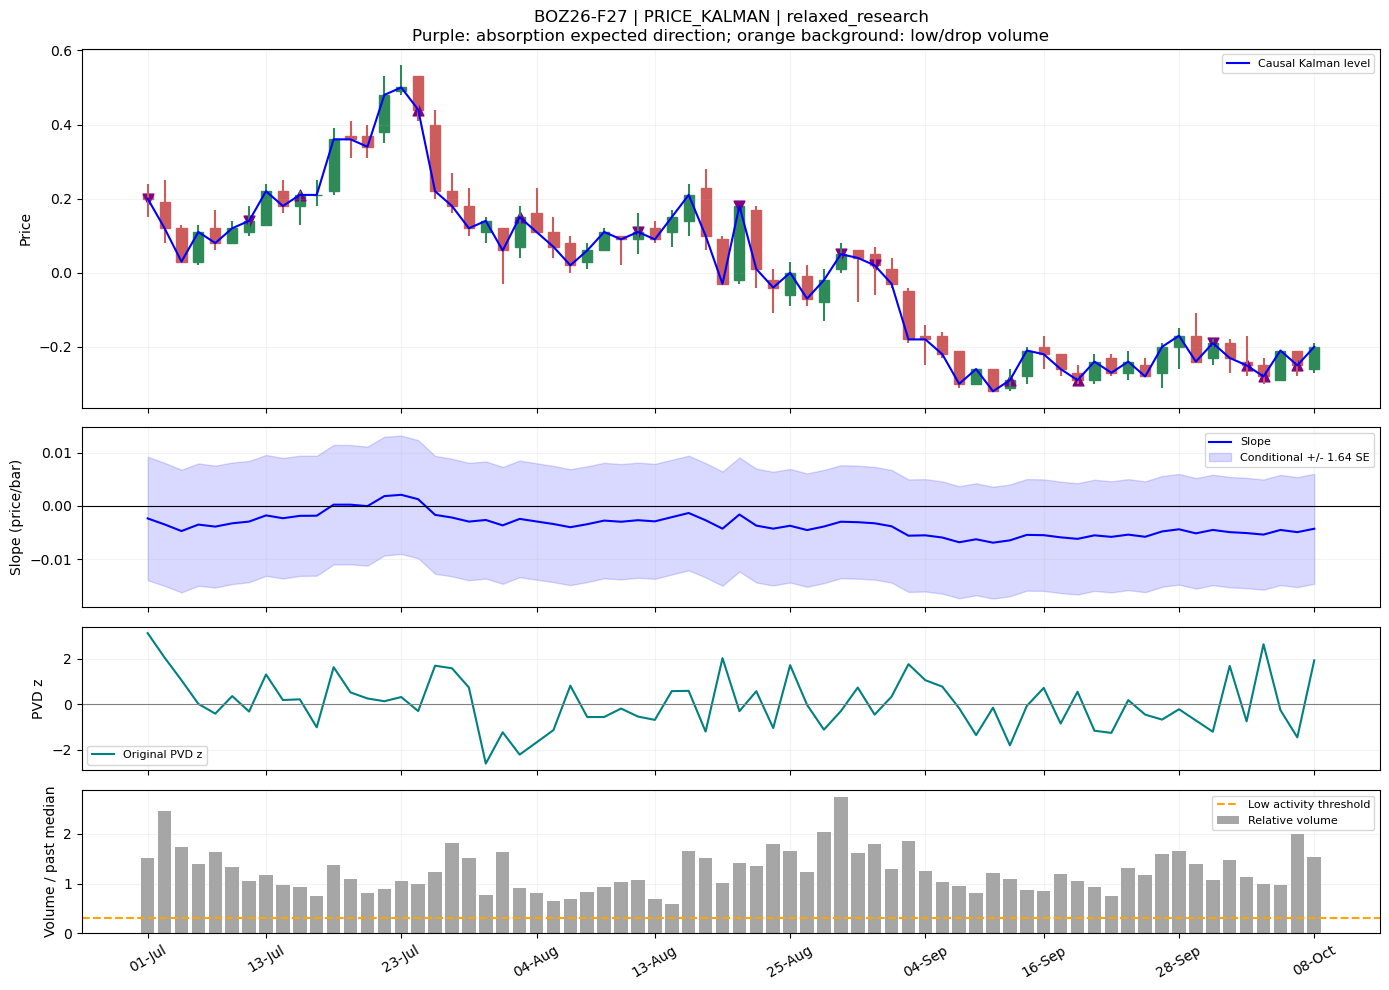

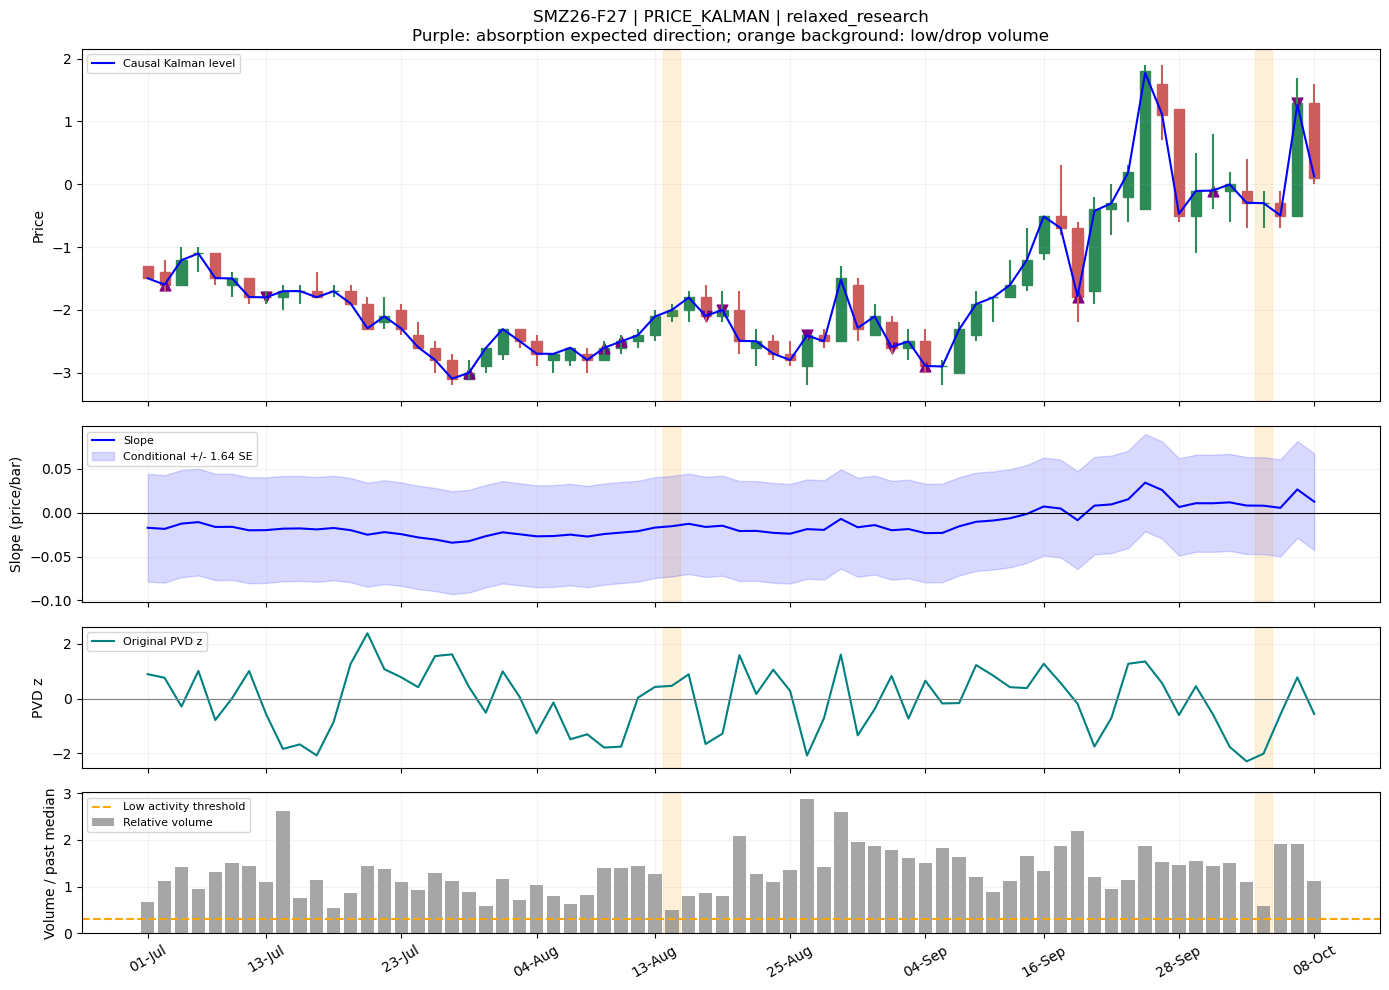

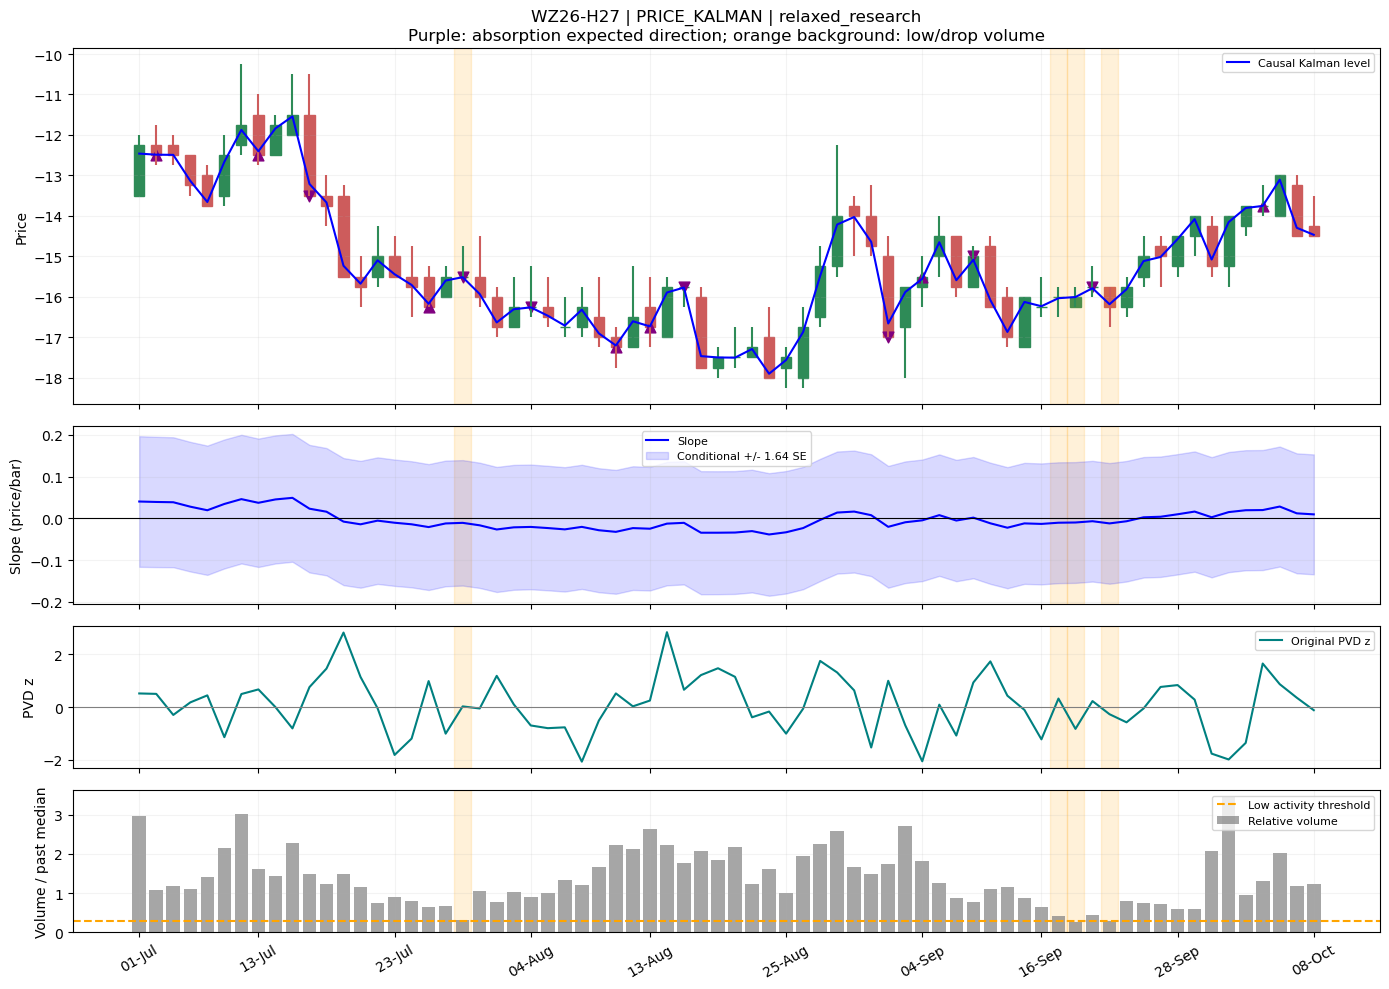

In [31]:
# Optional visual check: one instrument per product. Change these names if desired.
SHOW_KALMAN_PLOTS = True
KALMAN_PLOT_INSTRUMENTS = ["BOZ26-F27", "SMZ26-F27", "WZ26-H27"]
KALMAN_PLOT_VARIANT = "PRICE_KALMAN"  # or "VOLUME_KALMAN"
if SHOW_KALMAN_PLOTS:
    import matplotlib.pyplot as plt
    from IPython.display import display, Markdown
    display(Markdown("**Kaise dekho:** candles ke saath blue Kalman level. Slope band zero cross kare toh direction uncertain. "
                     "Negative PVD alone reversal nahi. Orange background low/sudden-drop volume; low activity ko automatically failure nahi maana. "
                     "Purple arrows absorption expectation hain. Plots model diagnosis hain; performance COPY tables se judge karo."))
    for instrument in KALMAN_PLOT_INSTRUMENTS:
        key = (KALMAN_PROFILES[0], instrument, KALMAN_PLOT_VARIANT)
        if key in KALMAN_TEST["daily"]:
            fig = kp.plot_context(KALMAN_TEST, instrument, KALMAN_PROFILES[0], KALMAN_PLOT_VARIANT)
            plt.close(fig)
        else:
            print("Plot unavailable:", key, "Check COPY ERRORS.")


## 14. SM fronts: sirf 2 percentage tables

Run section 1 first. Saved snapshot use hoga, API nahi. Settings mein product, structures aur gap change kar sakte ho.

**5 trading bars = maximum date gap 5 bars, earlier/later dono allowed.** Matching retrospective hai; later signal first trade ke entry time available nahi tha. Same BUY/SELL side only. Spreads compare with other spreads; jumbos with other jumbos. Compression threshold snapshot ka hai; consecutive threshold-hit days form one episode anchored at its FIRST day.

**Table 1:** eligible anchor signal mein se kitne ko at least one other front par same signal mila? Multiple matching fronts anchor count inflate nahi karte. Full +/- gap window scored hona chahiye in at least one peer; boundary/missing coverage excluded.

**Table 2:** har anchor-other-front ka nearest same signal; duplicate undirected pairs once. Pairs can share events, so independent samples nahi. Both_success = both absorption 1:1 TARGET, or both compression large-move SUCCESS. Same_outcome includes same TARGET/STOP/TIMEOUT for absorption and SUCCESS/FAILURE for compression. Same_move = full-horizon terminal UP/DOWN direction same, FLAT counted not same. Direction aur target-hit alag questions hain. N columns denominator dikhate hain.

**ATR correction:** TR=max(H-L, abs(H-prevClose), abs(L-prevClose)); ATR10=last 10 daily TR ka simple mean. Below cross-front 1:1 labels use ATR_PERIOD=10 explicitly, frozen at each event entry; original absorption detection thresholds/event selection remain from saved research. This differs from section 13 if its saved ATR period was 14. Timeout included, censored excluded. Exact stop/target levels are ideal fills; same-bar ambiguous stop-first. Compression outcome scans ALL next raw daily closes, not only signal days: max absolute close move > configured ticks, direction-free.


In [ ]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown
from market_analysis.finding_threshold import expected_profit_analysis as cross_ep
from market_analysis.combined_signal_analysis.kalman_pvd_research import trade_1r

CROSS_PRODUCT = "SM"
CROSS_PROFILE = "relaxed_research"
CROSS_STRUCTURES = ["spread", "jumbo"]  # ["spread"] for only the front spreads
MAX_GAP_BARS = 5
ATR_PERIOD = 10
ABS_FORWARD_BARS = 10
COMPRESSION_FORWARD_BARS = int(core.config.COMPRESSION["forward_days"])
COMPRESSION_MOVE_TICKS = float(core.config.COMPRESSION["k"])


def compact_front_tables(research_result):
    """Two pooled tables with complete-window coverage and outcome-blind matching."""
    if MAX_GAP_BARS < 0 or int(MAX_GAP_BARS) != MAX_GAP_BARS:
        raise ValueError("MAX_GAP_BARS must be a nonnegative integer")
    if min(ATR_PERIOD, ABS_FORWARD_BARS, COMPRESSION_FORWARD_BARS) < 1:
        raise ValueError("ATR/horizons must be positive")
    root = Path(research_result["output_dir"])
    paths = list((root / CROSS_PROFILE).glob("*/metadata.json"))
    if len(paths) != 1:
        raise ValueError("Expected exactly one saved profile snapshot")
    folder = paths[0].parent
    metadata = json.loads(paths[0].read_text(encoding="utf-8"))
    start, end = [pd.Timestamp(metadata[k]).normalize() for k in ("analysis_start", "analysis_end")]
    universe = pd.read_csv(root / "universe.csv")
    universe = universe.loc[universe["product"].eq(CROSS_PRODUCT) & universe.structure.isin(CROSS_STRUCTURES)]
    if universe.instrument.duplicated().any():
        raise ValueError("Duplicate instruments")
    saved_events = pd.read_csv(folder / "events.csv")
    if saved_events.event_id.duplicated().any():
        raise ValueError("Duplicate absorption event ids")
    calendars, records, ready, loaded, errors = [], [], {}, {}, []
    threshold = float(metadata["settings"]["compression_threshold"])
    stop_mult = float(metadata["abs_params"]["stop_atr_mult"])
    for item in universe.itertuples():
        try:
            d = pd.read_csv(folder / f"{item.instrument}_daily_signals.csv")
            d["Date"] = pd.to_datetime(d.Date, utc=True).dt.normalize()
            if not d.Date.is_monotonic_increasing or d.Date.duplicated().any():
                raise ValueError("Dates not unique/sorted")
            calendars.extend(d.Date[d.Date.between(start, end)].tolist())
            feat = cross_ep.build_v2_features(d, metadata["settings"]["candle_lengths"], metadata["abs_params"])
            valid = np.isfinite(feat[["z_delta", "z_price", "atr"]]).all(axis=1) & feat.atr.gt(0)
            abs_ready = set(pd.to_datetime(feat.loc[valid, "Date"], utc=True).dt.normalize())
            abs_ready = {date for date in abs_ready if start <= date <= end}
            comp_ready = set(d.loc[d.Date.between(start, end) & np.isfinite(d.compression_score), "Date"])
            ready[item.instrument, "ABS_BUY"] = abs_ready
            ready[item.instrument, "ABS_SELL"] = abs_ready
            ready[item.instrument, "COMPRESSION"] = comp_ready
            previous = d.close.shift(1)
            tr = pd.concat([d.high-d.low, (d.high-previous).abs(), (d.low-previous).abs()], axis=1).max(axis=1)
            atr = tr.rolling(ATR_PERIOD, min_periods=ATR_PERIOD).mean()
            loaded[item.instrument] = item.structure

            def terminal_direction(index, horizon):
                if index+horizon >= len(d):
                    return "UNKNOWN"
                value = float(d.iloc[index+horizon].close-d.iloc[index].close)
                if not np.isfinite(value):
                    return "UNKNOWN"
                tolerance = item.tick_size * 1e-6
                return "UP" if value > tolerance else "DOWN" if value < -tolerance else "FLAT"

            for e in saved_events.loc[saved_events.instrument.eq(item.instrument)].itertuples():
                j = int(e.signal_index)
                if pd.Timestamp(e.Date).normalize() != d.iloc[j].Date:
                    raise ValueError("Event date/index mismatch")
                risk = stop_mult * float(atr.iloc[j])
                if not np.isfinite(risk) or risk <= 0:
                    status = "UNKNOWN"
                else:
                    outcome = trade_1r(d, j, 1 if e.absorption_direction == "SELL" else -1,
                                      risk, float(item.tick_size), ABS_FORWARD_BARS)
                    status = outcome["status"]
                records.append(dict(id=e.event_id, instrument=item.instrument, structure=item.structure,
                                    signal="ABS_"+e.absorption_direction, Date=d.iloc[j].Date,
                                    outcome=status, move=terminal_direction(j, ABS_FORWARD_BARS)))

            mask = d.compression_score.ge(threshold) & np.isfinite(d.compression_score)
            previous_known = np.isfinite(d.compression_score.shift(1))
            onset = mask & ~mask.shift(1, fill_value=False) & previous_known
            for j in d.index[onset & d.Date.between(start, end)]:
                status = "CENSORED"
                if j+COMPRESSION_FORWARD_BARS < len(d):
                    future = d.close.iloc[j+1:j+COMPRESSION_FORWARD_BARS+1]
                    if np.isfinite(future).all():
                        move_ticks = (future-d.iloc[j].close).abs().max()/item.tick_size
                        status = "SUCCESS" if move_ticks > COMPRESSION_MOVE_TICKS else "FAILURE"
                    else:
                        status = "DATA_INVALID"
                records.append(dict(id=f"{item.instrument}:COMP:{d.iloc[j].Date.date()}",
                                    instrument=item.instrument, structure=item.structure, signal="COMPRESSION",
                                    Date=d.iloc[j].Date, outcome=status,
                                    move=terminal_direction(j, COMPRESSION_FORWARD_BARS)))
        except Exception as exc:
            errors.append(dict(instrument=item.instrument, error=str(exc)))
            loaded.pop(item.instrument, None)
            records = [r for r in records if r["instrument"] != item.instrument]
    ledger = pd.DataFrame(records)
    if ledger.empty:
        raise ValueError(f"No events: {errors}")
    ledger = ledger.loc[ledger.Date.between(start, end)].copy()
    if ledger.id.duplicated().any():
        raise ValueError("Duplicate ledger events")
    calendar = sorted(set(calendars))
    position = {date:i for i,date in enumerate(calendar)}
    lookup = ledger.set_index("id")
    pairs, anchors, table1, table2 = {}, [], [], []
    for structure in CROSS_STRUCTURES:
        peers = sorted(i for i,s in loaded.items() if s == structure)
        for signal in ["ABS_BUY", "ABS_SELL", "COMPRESSION"]:
            group = ledger.loc[ledger.structure.eq(structure) & ledger.signal.eq(signal)]
            eligible_count, matched_count = 0, 0
            for anchor in group.itertuples():
                i = position[anchor.Date]
                covered, matched = False, False
                if anchor.Date in ready[anchor.instrument, signal] and i-MAX_GAP_BARS >= 0 and i+MAX_GAP_BARS < len(calendar):
                    required = set(calendar[i-MAX_GAP_BARS:i+MAX_GAP_BARS+1])
                    for other in peers:
                        if other == anchor.instrument or not required.issubset(ready[other,signal]):
                            continue
                        covered = True
                        candidates = group.loc[group.instrument.eq(other) & group.Date.isin(required)].copy()
                        if candidates.empty:
                            continue
                        candidates["gap"] = candidates.Date.map(position).sub(i).abs()
                        buddy = candidates.sort_values(["gap", "Date", "id"]).iloc[0]
                        matched = True
                        key = tuple(sorted((anchor.id, buddy.id)))
                        pairs[key] = dict(structure=structure, signal=signal, a=key[0], b=key[1],
                                          gap=abs(position[buddy.Date]-i))
                eligible_count += int(covered)
                matched_count += int(matched)
                anchors.append(dict(id=anchor.id, eligible=covered, matched=matched))
            table1.append(dict(Structure=structure, Signal=signal, Eligible=eligible_count,
                               Excluded=len(group)-eligible_count,
                               Same_signal_pct=100*matched_count/eligible_count if eligible_count else np.nan))
    pair_ledger = pd.DataFrame(list(pairs.values()))
    details = []
    for pair in pairs.values():
        a, b = lookup.loc[pair["a"]], lookup.loc[pair["b"]]
        resolved = {"SUCCESS", "FAILURE"} if pair["signal"] == "COMPRESSION" else {"TARGET", "STOP", "TIMEOUT"}
        success = "SUCCESS" if pair["signal"] == "COMPRESSION" else "TARGET"
        known = a.outcome in resolved and b.outcome in resolved
        direction_known = a.move != "UNKNOWN" and b.move != "UNKNOWN"
        details.append(dict(**pair, outcome_known=known, both_success=known and a.outcome==success and b.outcome==success,
                            same_outcome=known and a.outcome==b.outcome, direction_known=direction_known,
                            same_move=direction_known and a.move==b.move and a.move in ("UP","DOWN"),
                            outcome_a=a.outcome, outcome_b=b.outcome, move_a=a.move, move_b=b.move))
    detail = pd.DataFrame(details)
    for row in table1:
        if detail.empty:
            p = pd.DataFrame(columns=["outcome_known","direction_known","both_success","same_outcome","same_move"])
        else:
            p = detail.loc[detail.structure.eq(row["Structure"]) & detail.signal.eq(row["Signal"])]
        n = int(p.outcome_known.sum()); nd = int(p.direction_known.sum())
        table2.append(dict(Structure=row["Structure"], Signal=row["Signal"], Outcome_pairs=n,
                           Both_success_pct=100*p.both_success.sum()/n if n else np.nan,
                           Same_outcome_pct=100*p.same_outcome.sum()/n if n else np.nan,
                           Direction_pairs=nd, Same_move_pct=100*p.same_move.sum()/nd if nd else np.nan))
    first, second = pd.DataFrame(table1), pd.DataFrame(table2)
    destination = root / "compact_cross_front" / CROSS_PROFILE / CROSS_PRODUCT
    destination.mkdir(parents=True, exist_ok=True)
    for name, frame in {"occurrence":first,"outcomes":second,"events":ledger,
                        "pairs":detail,"anchors":pd.DataFrame(anchors),"errors":pd.DataFrame(errors)}.items():
        frame.to_csv(destination/f"{name}.csv", index=False)
    settings = dict(product=CROSS_PRODUCT,profile=CROSS_PROFILE,structures=CROSS_STRUCTURES,
                    max_gap_bars=MAX_GAP_BARS,atr_period=ATR_PERIOD,stop_atr_mult=stop_mult,
                    abs_forward=ABS_FORWARD_BARS,compression_forward=COMPRESSION_FORWARD_BARS,
                    compression_move_ticks=COMPRESSION_MOVE_TICKS,compression_threshold=threshold,
                    analysis_start=str(start),analysis_end=str(end),loaded=list(loaded))
    (destination/"settings.json").write_text(json.dumps(settings,indent=2),encoding="utf-8")
    print(f"{CROSS_PRODUCT} | {CROSS_PROFILE} | {len(loaded)}/{len(universe)} instruments | max gap={MAX_GAP_BARS} trading bars | ATR={ATR_PERIOD}")
    if errors:
        print("Missing/failed instruments (results cover loaded instruments only):", errors)
    display(Markdown("**Table 1:** anchor ko kisi aur same-type front par same signal mila? Eligible denominator hai."))
    display(first.round(2))
    display(Markdown("**Table 2:** same-signal matched pairs mein dono successful / same outcome / same actual direction kitni baar? "
                     "Absorption success=1:1 target first. Compression success=large close movement, no directional prediction. "
                     "N columns sample size hain; FLAT same-direction success nahi."))
    display(second.round(2))
    print("COPY FRONT OCCURRENCE\n"+first.round(3).to_csv(index=False))
    print("COPY FRONT OUTCOMES\n"+second.round(3).to_csv(index=False))
    return dict(occurrence=first,outcomes=second,events=ledger,pairs=detail,anchors=pd.DataFrame(anchors),
                errors=pd.DataFrame(errors),settings=settings,output_dir=destination)

FRONT_COMPACT = compact_front_tables(RESEARCH)
